In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             accuracy_score, precision_recall_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

data_dir = "Dataset"

c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
circuits_df = pd.read_csv(f'{data_dir}/circuits.csv', index_col=0, na_values='\\N')
circuits_df.info()
circuits_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 77 entries, 1 to 79
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitRef  77 non-null     object 
 1   name        77 non-null     object 
 2   location    77 non-null     object 
 3   country     77 non-null     object 
 4   lat         77 non-null     float64
 5   lng         77 non-null     float64
 6   alt         77 non-null     int64  
 7   url         77 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 5.4+ KB


,circuitRef,name,location,country,lat,lng,alt,url
circuitId,,,,,,,,
1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [3]:
constructor_results_df = pd.read_csv(f'{data_dir}/constructor_results.csv', index_col=0, na_values='\\N')
constructor_results_df.info()
constructor_results_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 12625 entries, 1 to 17129
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   raceId         12625 non-null  int64  
 1   constructorId  12625 non-null  int64  
 2   points         12625 non-null  float64
 3   status         17 non-null     object 
dtypes: float64(1), int64(2), object(1)
memory usage: 493.2+ KB


,raceId,constructorId,points,status
constructorResultsId,,,,
1,18,1,14.0,NaN
2,18,2,8.0,NaN
3,18,3,9.0,NaN
4,18,4,5.0,NaN
5,18,5,2.0,NaN


In [4]:
constructor_standings_df = pd.read_csv(f'{data_dir}/constructor_standings.csv', index_col=0, na_values='\\N')
constructor_standings_df.info()
constructor_standings_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 13391 entries, 1 to 28982
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   raceId         13391 non-null  int64  
 1   constructorId  13391 non-null  int64  
 2   points         13391 non-null  float64
 3   position       13391 non-null  int64  
 4   positionText   13391 non-null  object 
 5   wins           13391 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 732.3+ KB


,raceId,constructorId,points,position,positionText,wins
constructorStandingsId,,,,,,
1,18,1,14.0,1,1,1
2,18,2,8.0,3,3,0
3,18,3,9.0,2,2,0
4,18,4,5.0,4,4,0
5,18,5,2.0,5,5,0


In [5]:
constructors_df = pd.read_csv(f'{data_dir}/constructors.csv', index_col=0, na_values='\\N')
constructors_df.info()
constructors_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 212 entries, 1 to 215
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorRef  212 non-null    object
 1   name            212 non-null    object
 2   nationality     212 non-null    object
 3   url             212 non-null    object
dtypes: object(4)
memory usage: 8.3+ KB


,constructorRef,name,nationality,url
constructorId,,,,
1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [6]:
driver_standings_df = pd.read_csv(f'{data_dir}/driver_standings.csv', index_col=0, na_values='\\N')
driver_standings_df.info()
driver_standings_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 34863 entries, 1 to 73270
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   raceId        34863 non-null  int64  
 1   driverId      34863 non-null  int64  
 2   points        34863 non-null  float64
 3   position      34863 non-null  int64  
 4   positionText  34863 non-null  object 
 5   wins          34863 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 1.9+ MB


,raceId,driverId,points,position,positionText,wins
driverStandingsId,,,,,,
1,18,1,10.0,1,1,1
2,18,2,8.0,2,2,0
3,18,3,6.0,3,3,0
4,18,4,5.0,4,4,0
5,18,5,4.0,5,5,0


In [7]:
drivers_df = pd.read_csv(f'{data_dir}/drivers.csv', index_col=0, na_values='\\N')
drivers_df.info()
drivers_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 861 entries, 1 to 862
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   driverRef    861 non-null    object 
 1   number       59 non-null     float64
 2   code         104 non-null    object 
 3   forename     861 non-null    object 
 4   surname      861 non-null    object 
 5   dob          861 non-null    object 
 6   nationality  861 non-null    object 
 7   url          861 non-null    object 
dtypes: float64(1), object(7)
memory usage: 60.5+ KB


,driverRef,number,code,forename,surname,dob,nationality,url
driverId,,,,,,,,
1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [8]:
lap_times_df = pd.read_csv(f'{data_dir}/lap_times.csv', na_values='\\N')
lap_times_df.info()
lap_times_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


In [9]:
pit_stops_df = pd.read_csv(f'{data_dir}/pit_stops.csv', na_values='\\N')
pit_stops_df.info()
pit_stops_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


In [10]:
qualifying_df = pd.read_csv(f'{data_dir}/qualifying.csv', index_col=0, na_values='\\N')
qualifying_df.info()
qualifying_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 10494 entries, 1 to 10551
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   raceId         10494 non-null  int64 
 1   driverId       10494 non-null  int64 
 2   constructorId  10494 non-null  int64 
 3   number         10494 non-null  int64 
 4   position       10494 non-null  int64 
 5   q1             10338 non-null  object
 6   q2             5847 non-null   object
 7   q3             3629 non-null   object
dtypes: int64(5), object(3)
memory usage: 737.9+ KB


,raceId,driverId,constructorId,number,position,q1,q2,q3
qualifyId,,,,,,,,
1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [11]:
races_df = pd.read_csv(f'{data_dir}/races.csv', index_col=0, na_values='\\N')
races_df.info()
races_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 1125 entries, 1 to 1144
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   year         1125 non-null   int64 
 1   round        1125 non-null   int64 
 2   circuitId    1125 non-null   int64 
 3   name         1125 non-null   object
 4   date         1125 non-null   object
 5   time         394 non-null    object
 6   url          1125 non-null   object
 7   fp1_date     90 non-null     object
 8   fp1_time     68 non-null     object
 9   fp2_date     90 non-null     object
 10  fp2_time     68 non-null     object
 11  fp3_date     72 non-null     object
 12  fp3_time     53 non-null     object
 13  quali_date   90 non-null     object
 14  quali_time   68 non-null     object
 15  sprint_date  18 non-null     object
 16  sprint_time  15 non-null     object
dtypes: int64(3), object(14)
memory usage: 158.2+ KB


,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
raceId,,,,,,,,,,,,,,,,,
1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
results_df = pd.read_csv(f'{data_dir}/results.csv', index_col=0, na_values='\\N')
results_df.info()   
results_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 26759 entries, 1 to 26764
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   raceId           26759 non-null  int64  
 1   driverId         26759 non-null  int64  
 2   constructorId    26759 non-null  int64  
 3   number           26753 non-null  float64
 4   grid             26759 non-null  int64  
 5   position         15806 non-null  float64
 6   positionText     26759 non-null  object 
 7   positionOrder    26759 non-null  int64  
 8   points           26759 non-null  float64
 9   laps             26759 non-null  int64  
 10  time             7680 non-null   object 
 11  milliseconds     7680 non-null   float64
 12  fastestLap       8252 non-null   float64
 13  rank             8510 non-null   float64
 14  fastestLapTime   8252 non-null   object 
 15  fastestLapSpeed  8252 non-null   float64
 16  statusId         26759 non-null  int64  
dtypes: float64(7), in

,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
resultId,,,,,,,,,,,,,,,,,
1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [13]:
# Check for duplicate (raceId, driverId) combinations
dup_check = results_df.groupby(['raceId', 'driverId']).size()
duplicates = dup_check[dup_check > 1]

print(f"Number of duplicate (raceId, driverId) pairs: {len(duplicates)}")
print(f"\nSample duplicates:")
print(duplicates.head(10))

# Look at what one of these actually looks like
first_dup_race = duplicates.index[0][0]
first_dup_driver = duplicates.index[0][1]
print(f"\nBoth rows for raceId={first_dup_race}, driverId={first_dup_driver}:")
print(results_df[
    (results_df['raceId'] == first_dup_race) & 
    (results_df['driverId'] == first_dup_driver)
][['raceId','driverId','grid','positionOrder','positionText','points']])


Number of duplicate (raceId, driverId) pairs: 85

Sample duplicates:
raceId  driverId
540     229         2
717     373         2
733     465         2
742     475         2
745     418         2
746     475         2
766     541         2
770     479         2
774     566         2
776     581         2
dtype: int64

Both rows for raceId=540, driverId=229:
          raceId  driverId  grid  positionOrder positionText  points
resultId                                                            
13189        540       229     0             26            F     0.0
13192        540       229     0             29            F     0.0


In [14]:
seasons_df = pd.read_csv(f'{data_dir}/seasons.csv', index_col=0, na_values='\\N')
seasons_df.info()
seasons_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 75 entries, 2009 to 2024
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   url     75 non-null     object
dtypes: object(1)
memory usage: 1.2+ KB


,url
year,
2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [15]:
sprint_results_df = pd.read_csv(f'{data_dir}/sprint_results.csv', index_col=0, na_values='\\N')
sprint_results_df.info()
sprint_results_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 360 entries, 1 to 360
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   raceId          360 non-null    int64  
 1   driverId        360 non-null    int64  
 2   constructorId   360 non-null    int64  
 3   number          360 non-null    int64  
 4   grid            360 non-null    int64  
 5   position        345 non-null    float64
 6   positionText    360 non-null    object 
 7   positionOrder   360 non-null    int64  
 8   points          360 non-null    int64  
 9   laps            360 non-null    int64  
 10  time            340 non-null    object 
 11  milliseconds    340 non-null    float64
 12  fastestLap      351 non-null    float64
 13  fastestLapTime  351 non-null    object 
 14  statusId        360 non-null    int64  
dtypes: float64(3), int64(9), object(3)
memory usage: 45.0+ KB


,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
resultId,,,,,,,,,,,,,,,
1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


In [16]:
status_df = pd.read_csv(f'{data_dir}/status.csv', index_col=0, na_values='\\N')
status_df.info()
status_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 139 entries, 1 to 141
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   status  139 non-null    object
dtypes: object(1)
memory usage: 2.2+ KB


,status
statusId,
1,Finished
2,Disqualified
3,Accident
4,Collision
5,Engine


# Fix data types (dates and lap times)

**Alasan:** `na_values` hanya menandai nilai yang hilang. Tanggal dan waktu lap seperti `"1:26.572"` masih tersimpan sebagai teks, sehingga tidak bisa dikurangkan, dibandingkan, atau dirata-ratakan.

**Yang kita konversi:**

| Kolom sumber | Hasil |
|---|---|
| `races.date` | tanggal sungguhan (`datetime64`) |
| `drivers.dob` | tanggal sungguhan (`datetime64`) |
| teks waktu lap (mis. `"1:26.572"`) | detik, disimpan di kolom baru `*_sec` |

Kolom teks waktu lap yang asli tetap dipertahankan.

> **Catatan:** Semua konversi dilakukan pada salinan kerja (nama huruf kecil seperti `races`, `results`). Tabel mentah `*_df` tidak pernah diubah.

In [17]:
import re

# Working copies: the raw *_df tables stay untouched
races      = races_df.copy()
drivers    = drivers_df.copy()
qualifying = qualifying_df.copy()
results    = results_df.copy()
pit_stops  = pit_stops_df.copy()
lap_times  = lap_times_df.copy()

# 1) Dates: text -> real dates
races['date']  = pd.to_datetime(races['date'])
drivers['dob'] = pd.to_datetime(drivers['dob'])

# 2) Lap times: text -> seconds
def laptime_to_seconds(t):
    """'1:26.572' -> 86.572 ; '23.456' -> 23.456 ; missing or unreadable -> NaN"""
    if pd.isna(t):
        return np.nan
    t = str(t).strip()
    m = re.fullmatch(r'(\d+):(\d+(?:\.\d+)?)', t)
    if m:
        return int(m.group(1)) * 60 + float(m.group(2))
    try:
        return float(t)
    except ValueError:
        return np.nan

for col in ['q1', 'q2', 'q3']:
    qualifying[col + '_sec'] = qualifying[col].apply(laptime_to_seconds)

results['fastestLapTime_sec'] = results['fastestLapTime'].apply(laptime_to_seconds)
pit_stops['duration_sec']     = pit_stops['duration'].apply(laptime_to_seconds)
lap_times['time_sec']         = lap_times['milliseconds'] / 1000

# 3) Proof that it worked
print('races.date dtype :', races['date'].dtype)
print('drivers.dob dtype:', drivers['dob'].dtype)
print()
print(qualifying[['q1', 'q1_sec']].dropna().head(3))
print()

# Every non-missing text value must have converted. All of these should print 0.
checks = [('qualifying q1', qualifying['q1'], qualifying['q1_sec']),
          ('qualifying q2', qualifying['q2'], qualifying['q2_sec']),
          ('qualifying q3', qualifying['q3'], qualifying['q3_sec']),
          ('results fastestLapTime', results['fastestLapTime'], results['fastestLapTime_sec']),
          ('pit_stops duration', pit_stops['duration'], pit_stops['duration_sec'])]
for name, text_col, sec_col in checks:
    print(f"{name:25} failed conversions: {int((text_col.notna() & sec_col.isna()).sum())}")

races.date dtype : datetime64[ns]
drivers.dob dtype: datetime64[ns]

                 q1  q1_sec
qualifyId                  
1          1:26.572  86.572
2          1:26.103  86.103
3          1:25.664  85.664

qualifying q1             failed conversions: 0
qualifying q2             failed conversions: 0
qualifying q3             failed conversions: 0
results fastestLapTime    failed conversions: 0
pit_stops duration        failed conversions: 0


**Temuan:** `races.date` dan `drivers.dob` kini sudah menjadi tanggal sungguhan, sehingga kita bisa menghitung hal-hal seperti usia pembalap atau selisih hari antar balapan. Waktu lap pada `qualifying` (q1, q2, q3), `results` (fastestLapTime), dan `pit_stops` (duration) telah dikonversi menjadi detik dalam kolom baru `*_sec`, sedangkan kolom teks aslinya tetap dipertahankan. Kelima pemeriksaan konversi melaporkan 0 kegagalan, jadi tidak ada waktu lap yang hilang. Waktu lap yang memang kosong tetap kosong (NaN); tidak ada yang diisi.

# Working copies (the raw tables stay untouched)

**Alasan:** jika sebuah sel menambah kolom atau memfilter baris langsung pada tabel yang sudah dimuat, menjalankannya dua kali atau tidak berurutan akan diam-diam mengubah data yang menjadi dasar semua sel berikutnya. Karena itu, kita memuat setiap tabel sekali saja (`*_df`, tidak pernah diubah) dan melakukan semua pekerjaan pada salinan berhuruf kecil.

Enam tabel yang dipakai pada langkah perbaikan tipe data (`races`, `drivers`, `qualifying`, `results`, `pit_stops`, `lap_times`) sudah disalin di atas. Di sini kita menyalin delapan tabel sisanya dan memeriksa bahwa tabel mentah tidak pernah berubah.

> **Aturan untuk sisa proyek:** kolom baru, filter, dan merge dilakukan pada tabel berhuruf kecil, tidak pernah pada tabel `*_df`.

In [18]:
# The other 8 tables (the first 6 were already copied in the type-fixing cell, do NOT copy them again)
circuits              = circuits_df.copy()
constructors          = constructors_df.copy()
status                = status_df.copy()
driver_standings      = driver_standings_df.copy()
constructor_standings = constructor_standings_df.copy()
constructor_results   = constructor_results_df.copy()
sprint_results        = sprint_results_df.copy()
seasons               = seasons_df.copy()

# ---- Verification: raw tables must be untouched ----
pairs = [
    ('circuits', circuits_df, circuits), ('constructors', constructors_df, constructors),
    ('status', status_df, status), ('driver_standings', driver_standings_df, driver_standings),
    ('constructor_standings', constructor_standings_df, constructor_standings),
    ('constructor_results', constructor_results_df, constructor_results),
    ('sprint_results', sprint_results_df, sprint_results), ('seasons', seasons_df, seasons),
    ('races', races_df, races), ('drivers', drivers_df, drivers),
    ('qualifying', qualifying_df, qualifying), ('results', results_df, results),
    ('pit_stops', pit_stops_df, pit_stops), ('lap_times', lap_times_df, lap_times),
]

for name, raw, work in pairs:
    assert raw is not work, f"{name}: the copy and the raw table are the same object"
    assert raw.shape[0] == work.shape[0], f"{name}: row count differs"

# The columns we added must exist ONLY on the copies
new_cols = {
    'qualifying': (qualifying_df, ['q1_sec', 'q2_sec', 'q3_sec']),
    'results':    (results_df,    ['fastestLapTime_sec']),
    'pit_stops':  (pit_stops_df,  ['duration_sec']),
    'lap_times':  (lap_times_df,  ['time_sec']),
}
for name, (raw, cols) in new_cols.items():
    for c in cols:
        assert c not in raw.columns, f"{name}_df was modified: it contains {c}"

# The date conversion must exist ONLY on the copies
assert not pd.api.types.is_datetime64_any_dtype(races_df['date']),   "races_df was modified"
assert not pd.api.types.is_datetime64_any_dtype(drivers_df['dob']),  "drivers_df was modified"
assert pd.api.types.is_datetime64_any_dtype(races['date']),          "races copy is not converted"

print("All 14 working copies exist and the raw tables are untouched.")

All 14 working copies exist and the raw tables are untouched.


**Temuan:** keempat belas tabel kini sudah memiliki salinan kerja, dan pemeriksaan mengonfirmasi bahwa tabel mentah `*_df` masih memiliki tipe data aslinya dan tidak ada kolom tambahan. Menjalankan ulang sel mana pun tidak akan lagi merusak data mentah. Mulai sekarang, semua merge, filter, dan kolom baru menggunakan tabel berhuruf kecil.

# Exploratory Data Analysis (EDA)

Sebelum membangun model, kita perlu memahami data yang digunakan secara mendalam. Bagian ini menjawab empat pertanyaan:

1. **Seperti apa variabel target kita?** Apakah `positionOrder` adalah kolom yang tepat? Seberapa tidak seimbang kelas positif (podium)?
2. **Baris mana yang sebaiknya dipertahankan?** Sebagian entri adalah pembalap yang tidak pernah start (DNQ). Haruskah mereka disertakan?
3. **Apa sinyal prediktif terkuat kita?** Posisi grid ternyata sangat prediktif terhadap hasil podium.
4. **Seberapa lengkap data kualifikasi kita?** Kita perlu tahu mulai tahun berapa waktu lap kualifikasi dapat diandalkan sebagai fitur.

Kita bekerja sepenuhnya dari `results_df` yang digabung dengan `races_df` (untuk kolom tahun). Belum ada pembersihan yang diterapkan, jadi kita mengamati data mentah apa adanya.

## Memeriksa `results_df`

`results_df` adalah tabel utama proyek ini. Setiap baris mewakili satu pembalap dalam satu balapan. Kita perlu memeriksa:

* **Berapa jumlah baris dan kolomnya?**
* **Kolom mana yang memiliki nilai kosong (null)?** Ini memberi tahu data apa yang hilang dan apakah hal itu menjadi masalah.
* **Nilai apa saja yang muncul pada `positionText`?** Kolom ini menyandikan hasil balapan (finis, mundur, tidak lolos kualifikasi, dll.) dan menjadi kunci dalam mendefinisikan variabel target.

In [19]:
print("Shape:", results_df.shape)
print("\nNull counts:")
print(results_df.isnull().sum())
print("\nSample positionText values:")
print(results_df['positionText'].value_counts().head(15))

Shape: (26759, 17)

Null counts:
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

Sample positionText values:
positionText
R     8897
F     1368
3     1135
4     1135
2     1133
5     1131
1     1128
6     1124
7     1104
8     1076
9     1038
10     978
11     902
12     800
13     713
Name: count, dtype: int64


**Temuan:**

* Tabel ini berisi 26.759 baris (satu baris per pembalap per entri balapan) dan 17 kolom.
* Kolom `position` punya 10.953 nilai kosong, karena kolom ini dibiarkan kosong untuk pembalap yang mundur atau tidak menyelesaikan balapan. Sebagai gantinya kita pakai `positionOrder`, yang selalu terisi dan memberi peringkat numerik ke setiap pembalap, termasuk yang mundur.
* `positionText` menunjukkan gambaran lengkap hasil balapan. Nilai yang paling sering muncul:
   * `R` (sekitar 8.900 baris): pembalap mundur di tengah balapan
   * `F` (sekitar 1.400 baris): pembalap gagal lolos kualifikasi dan tidak pernah start
   * String angka `1` sampai `20+`: pembalap menyelesaikan balapan di posisi tersebut
* Banyak kolom lain (waktu lap, kecepatan lap tercepat, rank) punya banyak nilai kosong karena hanya dicatat untuk balapan era modern. Hal ini akan kita tangani pada tahap feature engineering.

##  Podium Rate by Era

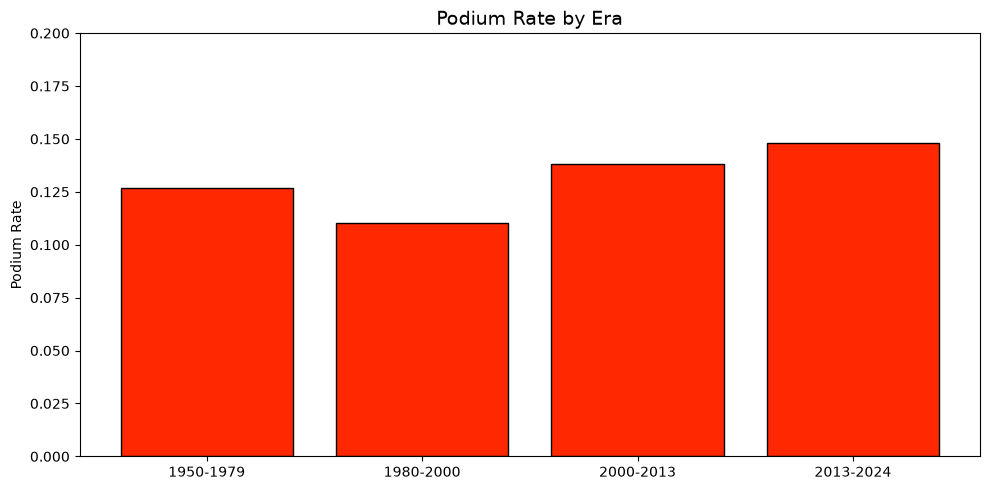

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
era_labels = ['1950-1979', '1980-2000', '2000-2013', '2013-2024']
era_values = [0.1269, 0.1101, 0.1382, 0.1479]
ax.bar(era_labels, era_values, color='#FF2800', edgecolor='black')
ax.set_title('Podium Rate by Era', fontsize=14)
ax.set_ylabel('Podium Rate')
ax.set_ylim(0, 0.2)
plt.tight_layout()
plt.show()

**Yang kita pelajari:** Tingkat podium relatif stabil di semua era (sekitar 11–15%). Era modern (2013–2024) punya angka tertinggi karena jumlah mobil dibatasi tepat 20 unit, jadi 3 podium ÷ 20 mobil = 15%. Pada 1980-an, lebih dari 30 mobil ikut balapan sehingga tingkat podiumnya lebih rendah. Artinya, kelas positif (podium = 1) hanya mewakili sekitar 1 dari 7–8 baris, sebuah ketidakseimbangan kelas yang harus kita tangani saat pemodelan.

## Race Outcome Distribution

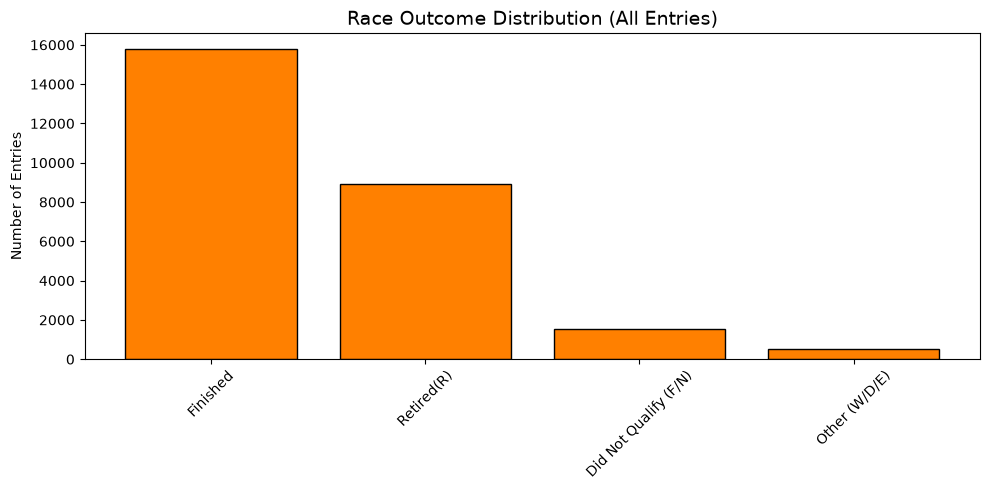

In [21]:
post_counts = results_df['positionText'].value_counts()
finished = post_counts[post_counts.index.str.isnumeric()].sum()
outcome_labels = ['Finished', 'Retired(R)', 'Did Not Qualify (F/N)', 'Other (W/D/E)']

outcome_values = [
    finished,
    post_counts.get('R', 0),
    post_counts.get('F', 0) + post_counts.get('N', 0),
    post_counts.get('W', 0) + post_counts.get('D', 0) + post_counts.get('E', 0)
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(outcome_labels, outcome_values, color="#FF8000", edgecolor='black')

ax.set_title('Race Outcome Distribution (All Entries)', fontsize=14)
ax.set_ylabel('Number of Entries')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Yang kita pelajari:** Sekitar sepertiga dari seluruh entri balapan berakhir dengan mundur (R). Ini penting karena pembalap yang mundur tidak mungkin naik podium, apa pun posisi start mereka. Sekitar 2.000 baris "Did Not Qualify" adalah pembalap yang bahkan tidak pernah start, dan baris-baris ini akan kita keluarkan sepenuhnya dari tabel pemodelan (lihat Keputusan 2 pada catatan pembersihan). Kategori "Other" mencakup diskualifikasi, pengunduran diri sebelum balapan, dan pengecualian.

## Podium Rate by Grid Position

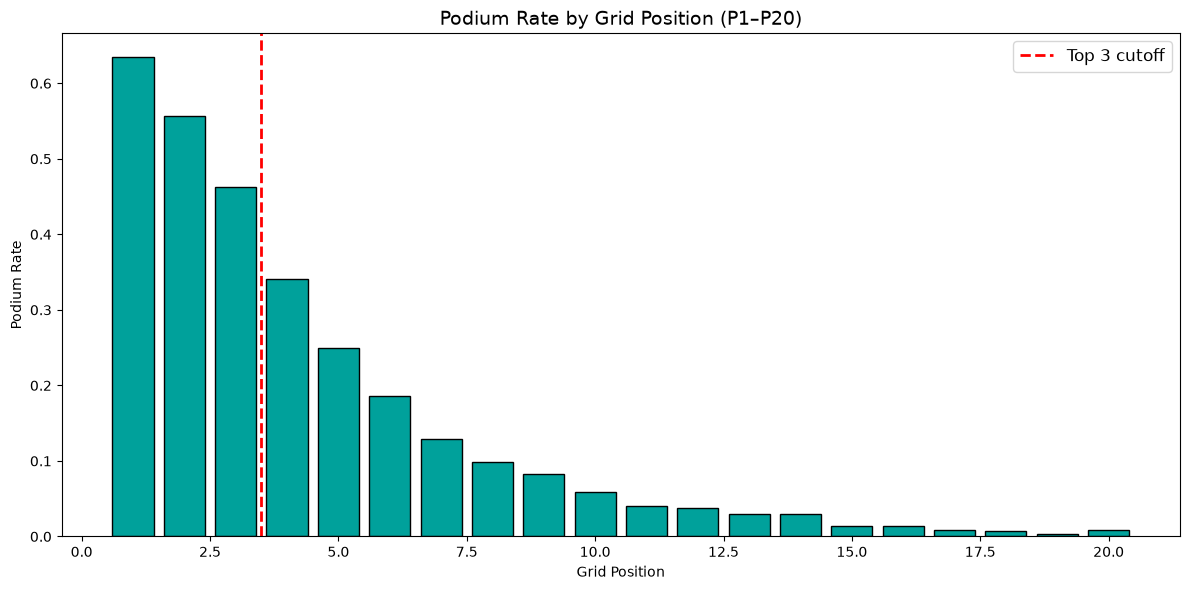

In [22]:
results_with_year = results_df.merge(races_df[['year']], left_on='raceId', right_index=True)
results_with_year['podium'] = (results_with_year['positionOrder'] <= 3)

grid_podium = (results_with_year[results_with_year['grid'].between(1, 20)]
               .groupby('grid')['podium'].mean())

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(grid_podium.index, grid_podium.values, color='#00A19B', edgecolor='black')
ax.set_title('Podium Rate by Grid Position (P1–P20)', fontsize=14)
ax.set_xlabel('Grid Position')
ax.set_ylabel('Podium Rate')
ax.axvline(x=3.5, color='red', linestyle='--', linewidth=2, label='Top 3 cutoff')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

**Yang kita pelajari:** Ini adalah grafik terpenting dalam seluruh EDA kita. Posisi grid punya hubungan monoton yang hampir sempurna dengan peluang naik podium:

* Start dari P1: peluang podium sekitar 65%
* Start dari P2: sekitar 55%
* Start dari P3: sekitar 46%
* Start dari P10 ke bawah: hampir nol

Penurunannya tajam dan konsisten. Hal ini sangat membenarkan penggunaan grid sebagai fitur, bahkan grid adalah fitur tunggal yang paling prediktif dalam model kita.

> **Catatan:** `grid` adalah posisi start setelah penalti diterapkan, sehingga berbeda dengan posisi kualifikasi (`quali_pos`) yang juga akan kita masukkan sebagai fitur terpisah. Selisih antara keduanya menangkap efek penalti grid.

# Investigating Duplicate (RaceID, driverId) Pairs

Kita sudah memastikan bahwa ada 85 pasangan duplikat. Sebelum memutuskan cara memperbaikinya, kita perlu memahami jenis duplikat apa yang terjadi.

Ada dua kemungkinan penjelasan:

1. **Mobil bersama (1950-an sampai 1960-an):** Seorang pembalap mengambil alih mobil rekan setimnya di tengah balapan, sehingga muncul dua baris hasil, satu untuk tiap mobil yang dikendarai.
2. **Kesalahan input data:** Pembalap yang sama tidak sengaja tercatat dua kali untuk balapan yang sama.

Untuk membedakan keduanya, kita periksa nilai `grid` dan `positionText` pada setiap pasangan duplikat. Jika pembalap benar-benar start dalam balapan, nilai `grid`-nya akan > 0. Jika kedua baris menunjukkan `grid = 0` dengan `positionText = F` (gagal lolos kualifikasi), kemungkinan besar itu adalah kesalahan input data.

In [23]:
# For eeach duplicate pairs, get both rows and check their grid values
dup_index = duplicates.index # these ara (RaceId, driverId)

## All duplicate rows
dup_rows = results_df[
    results_df.set_index(['raceId', 'driverId']).index.isin(dup_index)
].copy()

print(f"Total rows involved in duplicates: {len(dup_rows)}")
print(f"\nGrid value distribution in duplicate rows:")
print(dup_rows['grid'].value_counts().head(10))

print("\npositionText distribution in duplicate rows:")
print(dup_rows['positionText'].value_counts())

# How many duplicate PAIRS have at least one row with grid > 0?
dup_rows['has_start'] = dup_rows['grid'] > 0
pairs_with_start = dup_rows.groupby(['raceId','driverId'])['has_start'].any()
print(f"\nDuplicate pairs where driver actually started: {pairs_with_start.sum()}")
print(f"Duplicate pairs where driver never started (all grid=0): {(~pairs_with_start).sum()}")

Total rows involved in duplicates: 176

Grid value distribution in duplicate rows:
grid
1     21
5     15
10    11
6     10
8     10
7     10
11     9
13     8
2      7
12     6
Name: count, dtype: int64

positionText distribution in duplicate rows:
positionText
R     92
4     11
3     10
2      9
11     7
8      6
7      6
6      5
1      5
15     4
F      4
5      4
9      4
W      2
10     2
D      1
12     1
16     1
18     1
19     1
Name: count, dtype: int64

Duplicate pairs where driver actually started: 82
Duplicate pairs where driver never started (all grid=0): 3


In [24]:
# Look at a duplicate where the driver actually started
started_dups = dup_rows[dup_rows['grid'] > 0]
example_race = started_dups.iloc[0]['raceId']
example_driver = started_dups.iloc[0]['driverId']

print(f"Example: raceId={example_race}, driverId={example_driver}")
print(results_df[
    (results_df['raceId'] == example_race) & 
    (results_df['driverId'] == example_driver)
][['raceId','driverId','constructorId','grid','positionOrder','positionText','points','laps']])

# Also check what year these races are from
dup_race_ids = dup_rows['raceId'].unique()
dup_years = races_df.loc[races_df.index.isin(dup_race_ids), 'year']
print(f"\nYears where duplicates occur:")
print(dup_years.value_counts().sort_index())

Example: raceId=717, driverId=373
          raceId  driverId  constructorId  grid  positionOrder positionText  \
resultId                                                                      
17363        717       373            172     1              7            7   
24304        717       373            172     1             12            R   

          points  laps  
resultId                
17363        0.0   102  
24304        0.0    54  

Years where duplicates occur:
year
1950    3
1951    2
1952    3
1953    5
1954    5
1955    4
1956    6
1957    5
1958    3
1960    1
1961    2
1962    1
1964    1
1978    1
Name: count, dtype: int64


**Temuan:**

* Dari 85 pasangan duplikat, 82 pasangan punya `grid > 0`, artinya pembalap benar-benar start dalam balapan. Ini adalah mobil bersama (shared drive) yang asli dari era 1950-an sampai 1964.
* 3 pasangan punya `grid = 0` dengan `positionText = F`. Ini tampaknya kesalahan input data (pembalap DNQ yang tercatat dua kali).
* Distribusi `positionText` menunjukkan banyak baris `R` (mundur) berdampingan dengan posisi numerik. Pola ini sesuai dengan mobil bersama, yaitu pembalap mundur di satu mobil lalu mengambil alih mobil lain.
* Tahunnya mendukung hal ini: semua duplikat terjadi antara 1950 dan 1978, tepat pada era ketika mobil bersama diizinkan.

**Kesimpulan:** Duplikat ini bukan kesalahan data, melainkan keunikan sejarah F1 awal yang nyata. Kita tetap harus menerapkan aturan untuk menyederhanakannya menjadi satu baris per (`raceId`, `driverId`) sebelum pemodelan (lihat Keputusan 1 pada catatan pembersihan).

## Qualifying Coverage % of Races with Qualifying Data

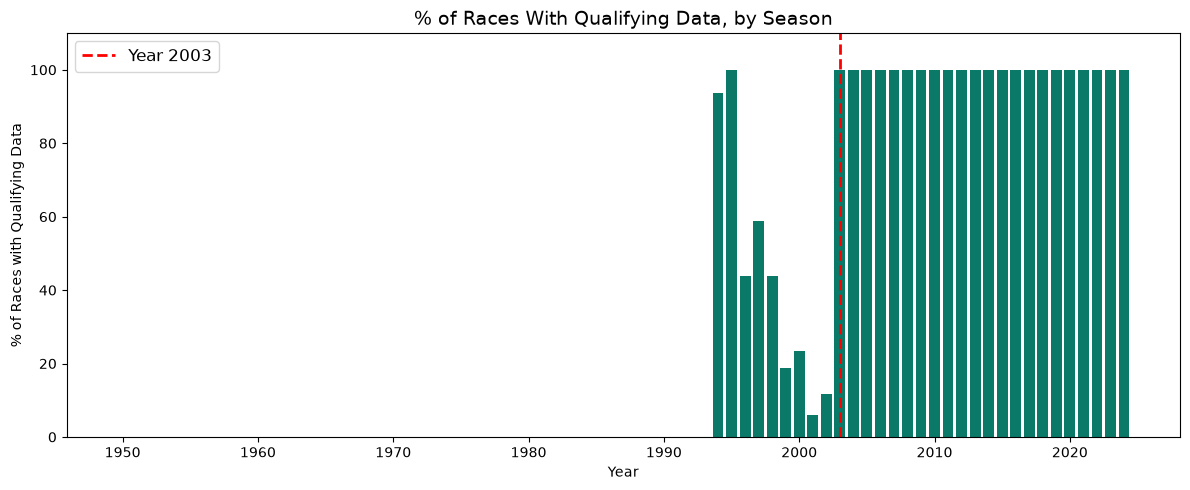

In [25]:
quali_coverage = (qualifying_df
                  .groupby('raceId')['position']
                  .count()
                  .reset_index(name='drivers_with_quali'))

quali_by_year = quali_coverage.merge(
    races_df[['year']], left_on='raceId', right_index=True
)

races_per_year = races_df.groupby('year').size()
races_with_quali = quali_by_year.groupby('year')['raceId'].nunique()
quali_race_coverage = (races_with_quali / races_per_year * 100).fillna(0)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(quali_race_coverage.index, quali_race_coverage.values,
       color='#0A7968', edgecolor='none', width=0.8)
ax.set_title('% of Races With Qualifying Data, by Season', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('% of Races with Qualifying Data')
ax.set_ylim(0, 110)
ax.axvline(x=2003, color='red', linestyle='--', linewidth=2, label='Year 2003')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

**Yang kita pelajari:** Data kualifikasi mulai muncul di dataset kita sekitar 1994, bukan dari 2000 seperti yang mungkin diasumsikan. Namun, cakupan sebelum 2003 tidak bisa diandalkan, bahkan turun sampai 5% pada beberapa musim. Mulai 2003 dan seterusnya, cakupannya 100% untuk setiap balapan. Sebelum 1994, sama sekali tidak ada data kualifikasi.

**Keputusan (akan diimplementasikan):** Fitur berbasis kualifikasi hanya dianggap andal untuk balapan dari 2003 ke atas. Untuk balapan sebelum 2003, kita memakai posisi grid sebagai pengganti (proxy). Hal ini juga memengaruhi pilihan jendela data latih: jika kita menyertakan fitur kualifikasi, sebaiknya pelatihan dibatasi pada data pasca-2003 agar tidak terlalu banyak nilai yang hilang.

# Average Drivers with Qualifying Data per Race

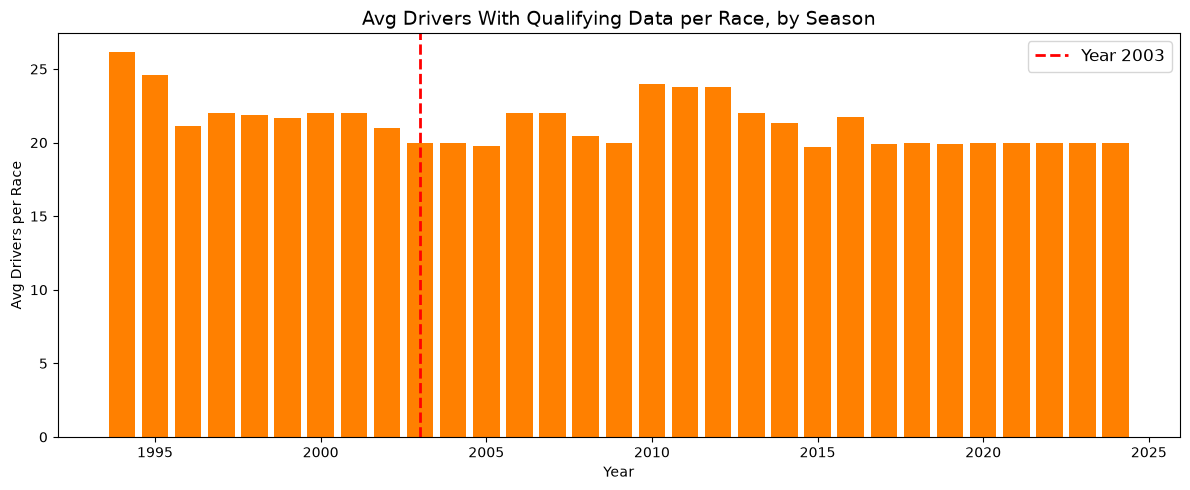

In [26]:
avg_by_year = quali_by_year.groupby('year')['drivers_with_quali'].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(avg_by_year.index, avg_by_year.values, color='#FF8000', edgecolor='none', width=0.8)

ax.set_title('Avg Drivers With Qualifying Data per Race, by Season', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('Avg Drivers per Race')
ax.axvline(x=2003, color='red', linestyle='--', linewidth=2, label='Year 2003')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

**Yang kita pelajari:** Ketika data kualifikasi ada untuk sebuah balapan, datanya mencakup semua pembalap yang berpartisipasi di balapan itu (20 sampai 26, tergantung era). Artinya, data yang hilang terjadi di tingkat balapan, bukan tingkat pembalap: sebuah balapan entah tercakup sepenuhnya atau tidak ada sama sekali. Tidak ada kasus di mana sebagian pembalap punya waktu kualifikasi sementara yang lain tidak dalam balapan yang sama.

Hal ini menyederhanakan strategi imputasi kita: untuk setiap balapan yang data kualifikasinya hilang, kita bisa langsung memakai posisi grid sebagai pengganti bagi semua pembalap di balapan tersebut, tanpa perlu menangani data hilang sebagian dalam satu balapan.

# Data Cleaning Decisions

## Keputusan 1: Baris Duplikat (`raceId`, `driverId`)

- **Masalah:** Ditemukan 85 pasangan duplikat, 82 di antaranya melibatkan pembalap yang benar-benar start. Duplikat ini berasal dari mobil bersama pada era 1950-an sampai 1964, ketika pembalap bertukar mobil di tengah balapan.

- **Aturan:** Pertahankan baris yang `positionText`-nya berupa angka (finis terklasifikasi). Jika kedua baris adalah mundur (retirement), pertahankan baris dengan `positionOrder` yang lebih baik.

- **Alasan:** Finis terklasifikasi mewakili hasil akhir resmi.

- **Hasil:** 88 baris dihapus dari tabel pemodelan (3 dari 91 baris berulang milik pembalap yang tidak start dan memang sudah dikeluarkan).

## Keputusan 2: Pembalap yang Tidak Start

- **Masalah:** Sebanyak 2.054 baris memiliki `positionText` F, N, W, D, atau E, tetapi tidak semuanya benar-benar tidak pernah start.

- **Aturan (tabel pemodelan):** Keluarkan F (gagal lolos kualifikasi), W (mengundurkan diri), dan E (dikeluarkan). Pertahankan N, D, dan R: mereka berada di grid dan menempuh lap, sehingga menjadi bagian dari balapan pada titik batas prediksi.

- **Bukti:** Diuji dengan slot grid dan jumlah lap yang diselesaikan pada bagian tabel pemodelan ("Which rows are real race starters?"). Yang mengidentifikasi pembalap tidak start adalah `positionText`, bukan `grid`.

- **Status:** Q1 dan Q3 hanya mengeluarkan F dan W (9 baris lebih sedikit dibanding tabel pemodelan). Menyelaraskannya dengan tabel pemodelan cukup dengan satu baris perubahan (`NON_STARTER_CODES`), yang masih harus dikonfirmasi oleh tim.

## Keputusan 3: Indianapolis 500 (1950-1960)

- **Masalah:** Indy 500 dihitung dalam kejuaraan pada 1950-1960, tetapi formatnya, pembalapnya, dan grid-nya sama sekali berbeda.

- **Aturan:** Keluarkan balapan ini dari tabel pemodelan (berdasarkan nama balapan dan tahun, sehingga US Grand Prix biasa di sirkuit yang sama tetap dipertahankan).

- **Alasan:** Entri Indy 500 mengacaukan analisis balapan kandang dan tidak beririsan dengan pembalap maupun sirkuit F1 reguler.

## Keputusan 4: Nilai Penanda (`\N`)

- **Masalah:** CSV mentah memakai string literal `\N` untuk nilai yang hilang.

- **Aturan:** Ditangani saat pemuatan dengan `na_values='\\N'`.

- **Status:** Selesai.

## Keputusan 5: Kolom Tanggal dan Waktu

- **Masalah:** `dob` dan `date` berupa string, dan waktu lap seperti `"1:26.572"` berupa teks.

- **Aturan:** Konversi tanggal dengan `pd.to_datetime()` dan waktu lap menjadi detik, pada salinan kerja tabel.

- **Status:** Selesai (lihat "Fix data types").

## Keputusan 6: `grid = 0`

- **Masalah:** 80 baris di tabel pemodelan memiliki `grid = 0` (start dari pit lane atau slot hilang), padahal model akan membaca 0 sebagai slot terbaik.

- **Aturan:** Pertahankan `grid` asli, lalu tambahkan flag `grid_is_zero` dan kolom `grid_filled` (satu slot di belakang slot nyata terakhir pada balapan tersebut).

- **Status:** Selesai (lihat "Handle grid = 0").

## Keputusan 7: Cakupan Data Kualifikasi

- **Masalah:** Data kualifikasi lengkap sejak 2003, tidak merata sejak 1994, dan hilang sebelum itu.

- **Aturan:** Untuk balapan tanpa data kualifikasi, gunakan slot grid sebagai posisi kualifikasi dan tambahkan flag `has_quali`.

- **Status:** Selesai (lihat "Qualifying position").

In [27]:
results_df[results_df['positionText'].isin(['D','E','N'])]['grid'].describe()

count    350.000000
mean      15.091429
std        7.701649
min        0.000000
25%       10.000000
50%       16.000000
75%       21.000000
max       31.000000
Name: grid, dtype: float64

In [28]:
fw = results_df[results_df['positionText'].isin(['F','W'])]
print((fw['grid'] > 0).sum(), "of", len(fw), "F/W rows have grid > 0")

153 of 1704 F/W rows have grid > 0


## Konstanta Proyek Bersama

Satu definisi yang dibaca oleh setiap bagian, sehingga tim bisa mengubah sebuah aturan di satu tempat saja. `MODEL_NON_STARTER_CODES` berisi daftar kode `positionText` yang berarti "tidak pernah start dalam balapan". Konstanta ini dipakai oleh tabel pemodelan dan oleh Q2. (Q1 dan Q3 masih hanya memakai `F` dan `W`, yang selisihnya 9 baris; lihat Keputusan 2.)

In [29]:
MODEL_NON_STARTER_CODES = ['F', 'W', 'E']   
# evidence: "Which rows are real race starters?" in the modeling-table section

## Pertanyaan Data Engineering

Tiga pertanyaan di bawah ini membutuhkan join bertingkat (multi-hop) lintas beberapa tabel. Setiap jawaban didukung oleh visualisasi dan justifikasi singkat mengenai grain, penanganan data yang hilang, dan batas waktu pra-balapan (pre-race cutoff) bila relevan.

In [30]:
# Q1 BASE TABLE: one row per (raceId, driverId) with year, circuit, grid, podium

# ── TEAM DECISION (pending confirmation) ─────────────────────────────────────
# Which positionText codes mean "never started the race"?
#   F = failed to qualify, W = withdrawn  -> never started (my proposal)
#   N, D, E = not classified / disqualified / excluded -> they DID start
NON_STARTER_CODES = ['F', 'W']  # evidence: "Which rows are real race starters?" in the modeling-table section
# NON_STARTER_CODES = ['F', 'N', 'W', 'D', 'E']   
# # original rule, if the team prefers it

# 1. Work on a copy (raw data must stay untouched)
res = results_df.copy()
print("Rows at start:", len(res))

# 2. Remove drivers who never started
# use positionText, NOT grid, because 153 F/W rows have a non-zero grid.
res = res[~res['positionText'].isin(NON_STARTER_CODES)]
print("Rows after removing non-starters:", len(res))

# 3. Fix the grain : one row per (raceId, driveId)
# Rule: prefer the classified finish (numeric positionText);
# if both rows are classified, prefer the one with the better positionOrder
res['_is_ret'] = (~res['positionText'].str.isnumeric()).astype(int)
res = (res.sort_values(['raceId', 'driverId', '_is_ret', "positionOrder"])
       .drop_duplicates(['raceId', 'driverId'], keep='first')
       .drop(columns=['_is_ret']))
print("Rows after fixing deduplication:", len(res))

# 4. Attach year / round / circuitId / race name
# raceId is the INDEX of races_df, so we join with right_index=True
races_small = (races_df[['year', 'round', 'circuitId', 'name']]
               .rename(columns={'name': 'race_name'}))
q1 = res.merge(races_small, left_on='raceId', right_index=True)

# 5. Attach circuit name / country
# circuitId is the INDEX of circuits_df
circ_small = (circuits_df[['name', 'country']]
              .rename(columns={'name': 'circuit', 'country': 'circuit_country'}))
q1 = q1.merge(circ_small, left_on='circuitId', right_index=True, how='left')

# ── 6. Exclude the Indianapolis 500 (1950-1960) ──────────────────────────────
# Filter by race name AND year, so other races at the same venue are kept.
is_indy = q1['race_name'].str.contains('Indianapolis 500', case=False) & (q1['year'] <= 1960)
print("Indy 500 rows removed:", is_indy.sum())
q1 = q1[~is_indy]

# ── 7. Create the target and the era label ───────────────────────────────────
q1['podium'] = (q1['positionOrder'] <= 3).astype(int)
q1['era'] = np.where(q1['year'] < 2014, 'pre-2014', '2014+')

# ── 8. Sanity checks ─────────────────────────────────────────────────────────
print("\n── Sanity checks ──")
print("Final shape:", q1.shape)
print("Unique (raceId, driverId):", not q1.duplicated(['raceId', 'driverId']).any())
print("Missing year / circuit after joins:", q1[['year', 'circuit']].isna().sum().to_dict())
print("Podium rate:", f"{q1['podium'].mean():.1%}")
print("Rows per era:\n", q1['era'].value_counts())
print()
print(q1[['raceId', 'driverId', 'grid', 'positionOrder', 'year', 'circuit', 'podium', 'era']].head())

Rows at start: 26759
Rows after removing non-starters: 25055
Rows after fixing deduplication: 24967
Indy 500 rows removed: 381

── Sanity checks ──
Final shape: (24586, 25)
Unique (raceId, driverId): True
Missing year / circuit after joins: {'year': 0, 'circuit': 0}
Podium rate: 13.7%
Rows per era:
 era
pre-2014    19988
2014+        4598
Name: count, dtype: int64

          raceId  driverId  grid  positionOrder  year  \
resultId                                                
7573           1         1    18             20  2009   
7563           1         2     9             10  2009   
7559           1         3     5              6  2009   
7558           1         4    10              5  2009   
7572           1         5    12             19  2009   

                                 circuit  podium       era  
resultId                                                    
7573      Albert Park Grand Prix Circuit       0  pre-2014  
7563      Albert Park Grand Prix Circuit       0 

Total front-row starts: 2213
Overall front-row -> podium rate: 60.5%

Circuits in both eras: 24 of 77
era      pre-2014      2014+
count   24.000000  24.000000
mean    50.791667  16.291667
std     33.263087   7.043215
min      4.000000   2.000000
25%     26.000000   8.000000
50%     50.000000  18.000000
75%     65.750000  22.000000
max    124.000000  26.000000


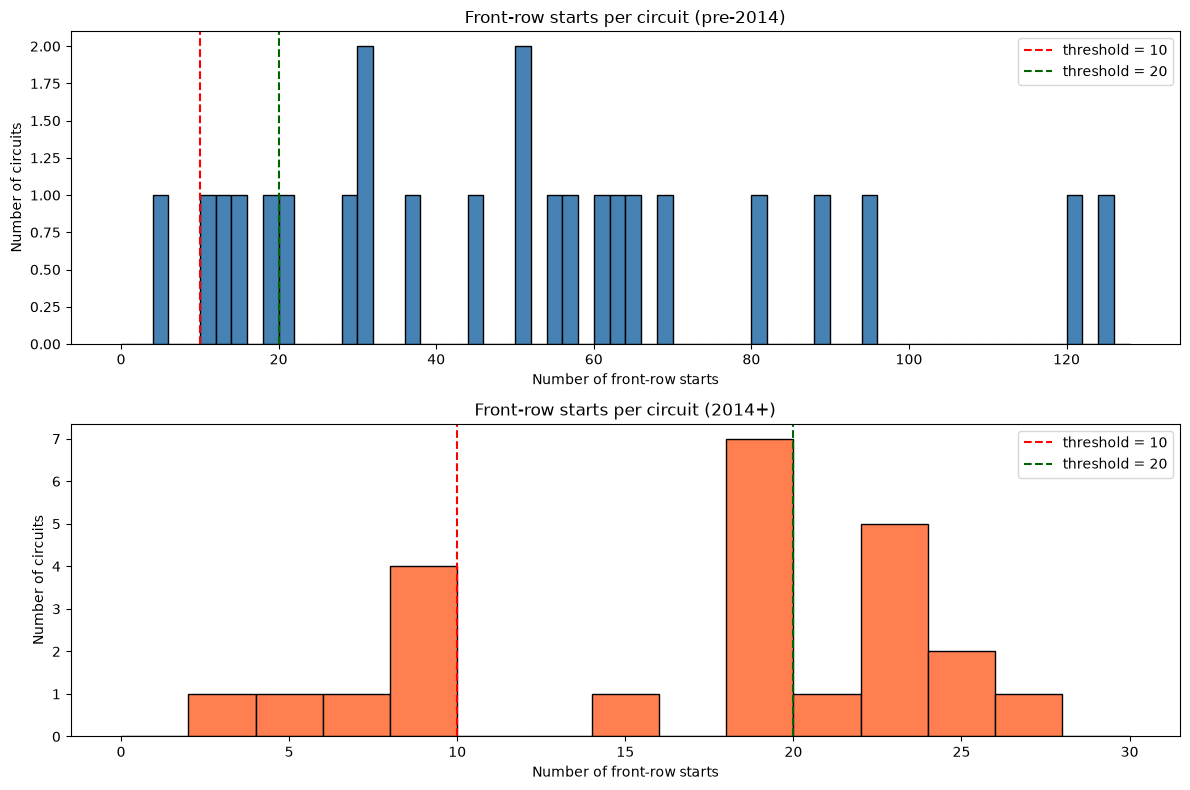

Threshold 5: 21 circuits kept
Threshold 10: 16 circuits kept
Threshold 15: 13 circuits kept
Threshold 20: 6 circuits kept


In [31]:
# ── Grid-based front row: grid position 1 or 2 ───────────────────────────────
# grid = 0 is excluded automatically, because we only keep grid 1 and 2.
front_row = q1[q1['grid'].isin([1, 2])]
print("Total front-row starts:", len(front_row))
print("Overall front-row -> podium rate:", f"{front_row['podium'].mean():.1%}")

# Front-row starts per circuit and era
counts = (front_row.groupby(['circuit', 'era']).size()
                   .unstack(fill_value=0))
counts = counts[['pre-2014', '2014+']]

# Circuits that exist in BOTH eras (needed to compare ranks)
both = counts[(counts['pre-2014'] > 0) & (counts['2014+'] > 0)]
print("\nCircuits in both eras:", len(both), "of", len(counts))
print(both.describe())

# Plot: how many front-row starts does each circuit have?
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, era, color in zip(axes, ['pre-2014', '2014+'], ['steelblue', 'coral']):
    ax.hist(both[era], bins=range(0, int(both[era].max()) + 5, 2),
            color=color, edgecolor='black')
    ax.axvline(10, color='red', linestyle='--', label='threshold = 10')
    ax.axvline(20, color='darkgreen', linestyle='--', label='threshold = 20')
    ax.set_title(f'Front-row starts per circuit ({era})')
    ax.set_xlabel('Number of front-row starts')
    ax.set_ylabel('Number of circuits')
    ax.legend()
plt.tight_layout()
plt.show()

# How many circuits survive each threshold?
for t in [5, 10, 15, 20]:
    n = ((both['pre-2014'] >= t) & (both['2014+'] >= t)).sum()
    print(f"Threshold {t}: {n} circuits kept")

## Memilih Ukuran Sampel Minimum untuk Q1

**Mengapa kita membutuhkannya.** Tingkat konversi sebuah sirkuit adalah podium ÷ start dari barisan depan. Jika sebuah sirkuit hanya punya 3 start dari barisan depan dan 3 podium, tingkatnya 100%, tetapi angka itu hampir tidak bermakna: satu hasil yang berbeda saja akan menggesernya 33 poin. Meranking sirkuit berdasarkan tingkat seperti itu sebagian besar hanya meranking keberuntungan. Karena itu kita hanya meranking sirkuit dengan jumlah start yang cukup, dan menentukan ambangnya dari data, bukan menebak.

**Yang kita lihat.**

* Kita hanya mengambil posisi grid 1 dan 2 (barisan depan). `grid = 0` otomatis tidak ikut karena bukan 1 atau 2.
* Secara keseluruhan ada 2.213 start dari barisan depan dan 60,5% di antaranya berakhir di podium. Angka ini menjadi pembanding dasar bagi setiap sirkuit.
* Hanya 24 dari 77 sirkuit yang menjadi tuan rumah start barisan depan di kedua era. Sirkuit yang hanya ada di satu era tidak bisa menunjukkan perubahan peringkat, sehingga tidak diikutkan dalam perbandingan.

**Yang ditunjukkan histogram.**

* **Pra-2014:** sirkuit memiliki 4 sampai 124 start barisan depan (rata-rata 51). Hampir semua sirkuit punya data yang banyak, sehingga hampir semua ambang akan berfungsi di sini.
* **2014+:** era hybrid hanya mencakup sekitar 11 musim dan setiap balapan punya tepat dua pembalap di barisan depan, sehingga tidak ada sirkuit yang bisa melebihi sekitar 26 start (rata-rata 16). Histogram terbagi menjadi dua kelompok: sirkuit reguler (18-28 start) dan sirkuit sesekali (2-10 start), dengan celah di sekitar 10-14.

**Berapa banyak sirkuit yang bertahan pada tiap ambang.**

| Minimum start per era | Sirkuit yang dipertahankan | Penilaian |
|---|---|---|
| 5 | 21 | Terlalu longgar: satu balapan mengubah tingkat sebesar 20 poin |
| 10 | 16 | **Dipilih:** memotong pada celah alami di data |
| 15 | 13 | Mungkin saja, tetapi membuang sirkuit dengan sekitar 7 balapan era hybrid |
| 20 | 6 | Terlalu ketat: terlalu sedikit sirkuit tersisa untuk membandingkan peringkat |

**Keputusan.** Sebuah sirkuit hanya diranking jika memiliki minimal 10 start barisan depan di setiap era. Dengan aturan ini 16 sirkuit dipertahankan dan sirkuit yang hanya sesekali muncul dikeluarkan.

**Keterbatasan.** Bahkan dengan 10-26 start, sebuah tingkat konversi masih tidak pasti (kira-kira ±15 poin persentase). Karena itu, selisih peringkat yang kecil kita anggap sebagai noise dan hanya perubahan peringkat yang besar yang kita interpretasikan. Kedua era juga memiliki panjang yang berbeda (sekitar 64 vs 11 musim), sehingga kita membandingkan peringkat dan tingkat konversi, tidak pernah jumlah mentahnya.

In [32]:
# Q1 (grid version): front-row -> podium conversion by circuit and era

MIN_STARTS = 10   # decided from the histograms above

front_row = q1[q1['grid'].isin([1, 2])]

# For each circuit and era: number of front-row starts and number of podiums
summary = (front_row.groupby(['circuit', 'era'])['podium']
                    .agg(starts='count', podiums='sum')
                    .reset_index())
summary['rate'] = summary['podiums'] / summary['starts']

# Wide format: one row per circuit, columns for each era
wide = summary.pivot(index='circuit', columns='era', values=['starts', 'rate'])
wide.columns = [f'{a}_{b}' for a, b in wide.columns]   # e.g. starts_pre-2014, rate_2014+
wide = wide.dropna()                                    # keep circuits in BOTH eras

# Keep only circuits with enough starts in BOTH eras
keep = (wide['starts_pre-2014'] >= MIN_STARTS) & (wide['starts_2014+'] >= MIN_STARTS)
wide = wide[keep].copy()
print(f"Circuits ranked: {len(wide)}")

# Rank 1 = highest conversion rate
wide['rank_pre'] = wide['rate_pre-2014'].rank(ascending=False, method='min').astype(int)
wide['rank_post'] = wide['rate_2014+'].rank(ascending=False, method='min').astype(int)
wide['rank_change'] = wide['rank_pre'] - wide['rank_post']   # positive = moved UP after 2014

table = wide[['starts_pre-2014', 'rate_pre-2014', 'rank_pre',
              'starts_2014+', 'rate_2014+', 'rank_post', 'rank_change']]
table = table.sort_values('rank_pre')
display(table.round(2))

# Rank correlation: has the overall ordering changed?
rho = wide['rank_pre'].corr(wide['rank_post'], method='spearman')
print(f"\nSpearman rank correlation between the two eras: {rho:.2f}")

Circuits ranked: 16


,starts_pre-2014,rate_pre-2014,rank_pre,starts_2014+,rate_2014+,rank_post,rank_change
circuit,,,,,,,
Suzuka Circuit,50.0,0.70,1,18.0,0.89,2,-1
Hungaroring,56.0,0.68,2,22.0,0.59,16,-14
Circuit de Barcelona-Catalunya,45.0,0.67,3,22.0,0.82,4,-1
Bahrain International Circuit,18.0,0.67,3,24.0,0.67,14,-11
Shanghai International Circuit,20.0,0.65,5,14.0,0.79,7,-2
Yas Marina Circuit,10.0,0.60,6,22.0,0.86,3,3
Autódromo Hermanos Rodríguez,30.0,0.60,6,18.0,0.61,15,-9
Autódromo José Carlos Pace,62.0,0.60,8,19.0,0.79,6,2
Marina Bay Street Circuit,12.0,0.58,9,18.0,0.72,12,-3



Spearman rank correlation between the two eras: -0.08


**Yang kita pelajari (front row berdasarkan grid):** Dari 16 sirkuit yang punya minimal 10 start barisan depan di setiap era, peringkatnya berubah hampir total setelah 2014. Korelasi peringkat Spearman sebesar -0,08, artinya urutan pra-2014 sama sekali tidak menjelaskan urutan pasca-2014.

* **Penanjak terbesar:** Monaco (peringkat 15 → 1, 49% → 89%) dan Spa (peringkat 12 → 4).
* **Penurun terbesar:** Hungaroring (peringkat 2 → 16, 68% → 59%), Bahrain (peringkat 3 → 14), dan Mexico City (peringkat 6 → 15).
* Sebagian besar sirkuit menunjukkan tingkat konversi yang lebih tinggi setelah 2014. Ini sejalan dengan mobil terdepan di era hybrid yang lebih andal dan dominan, sehingga sebagian perubahan peringkat mencerminkan era, bukan sirkuitnya sendiri (hipotesis, belum diuji).

> **Peringatan:** dengan 10-26 start per sirkuit, tingkat konversi memiliki ketidakpastian sekitar ±15 poin. Perubahan kecil (mis. Suzuka dari peringkat 1 → 2) hanya noise; hanya perubahan besar (Monaco, Hungaroring) yang bisa dipercaya. Peringkat bersifat relatif, jadi sebuah sirkuit bisa turun peringkat padahal tingkat konversinya sendiri tidak berubah (Bahrain: 67% → 67%).

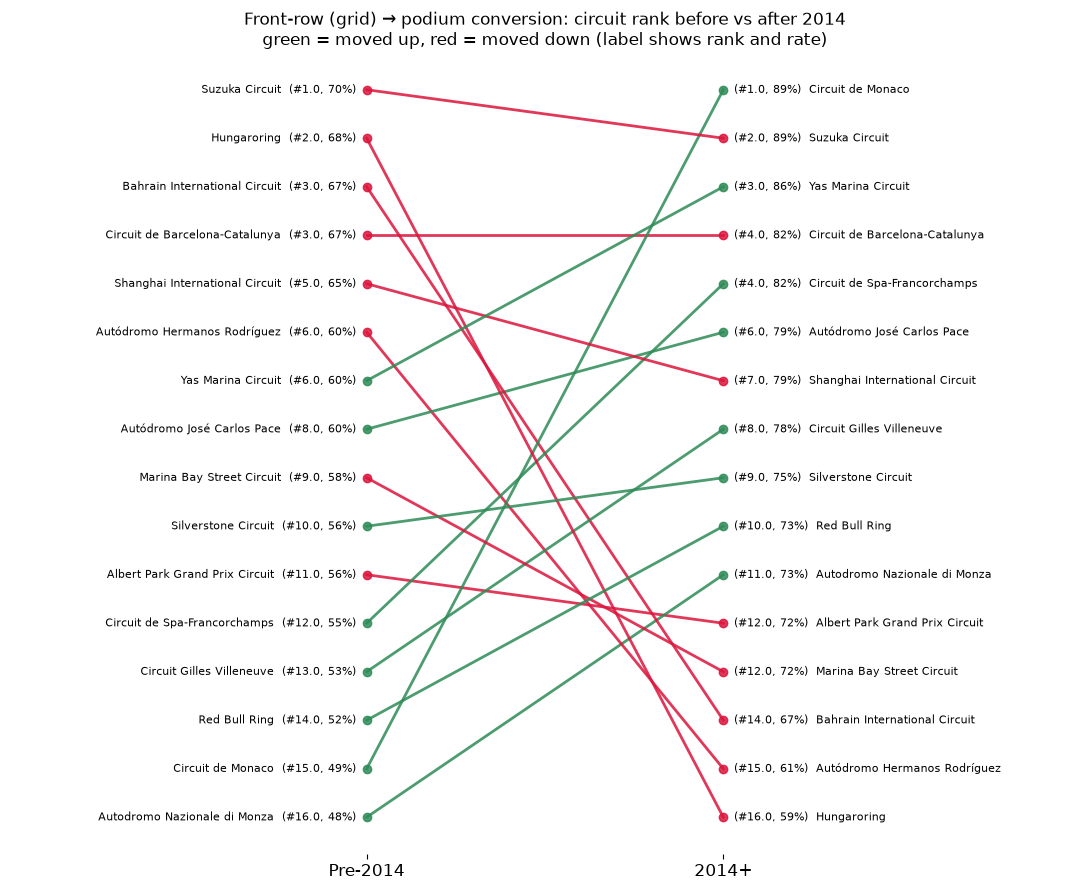

In [33]:
# ── Slope chart (tie-safe): unique y positions, true rank shown in the label ──
fig, ax = plt.subplots(figsize=(11, 9))

# Unique vertical slots: sort by rank, break ties by rate
left  = wide.sort_values(['rank_pre',  'rate_pre-2014'], ascending=[True, False]).reset_index()
right = wide.sort_values(['rank_post', 'rate_2014+'],    ascending=[True, False]).reset_index()
ypos_left  = {c: i + 1 for i, c in enumerate(left['circuit'])}
ypos_right = {c: i + 1 for i, c in enumerate(right['circuit'])}

for circuit, row in wide.iterrows():
    color = 'seagreen' if row['rank_change'] > 0 else ('crimson' if row['rank_change'] < 0 else 'gray')
    yl, yr = ypos_left[circuit], ypos_right[circuit]
    ax.plot([0, 1], [yl, yr], color=color, marker='o', linewidth=2, alpha=0.85)
    ax.text(-0.03, yl, f"{circuit[:30]}  (#{row['rank_pre']}, {row['rate_pre-2014']:.0%})",
            ha='right', va='center', fontsize=8)
    ax.text(1.03, yr, f"(#{row['rank_post']}, {row['rate_2014+']:.0%})  {circuit[:30]}",
            ha='left', va='center', fontsize=8)

ax.set_xlim(-1.0, 2.0)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Pre-2014', '2014+'], fontsize=12)
ax.set_yticks([])
ax.invert_yaxis()
ax.set_title('Front-row (grid) → podium conversion: circuit rank before vs after 2014\n'
             'green = moved up, red = moved down (label shows rank and rate)')
for s in ['top', 'right', 'bottom', 'left']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [34]:
# Q1 (qualifying version): front row defined by QUALIFYING position 1 or 2

MIN_STARTS = 10
QUALI_START_YEAR = 2003

# qualifying_df has one row per (raceId, driverId); keep only what we need
quali_small = (qualifying_df[['raceId', 'driverId', 'position']]
               .rename(columns={'position': 'quali_pos'}))

# Check the grain of qualifying before joining
print("Duplicate (raceId, driverId) in qualifying:",
      quali_small.duplicated(['raceId', 'driverId']).sum())

# Join onto the Q1 base table (left join keeps every race entry)
q1q = q1.merge(quali_small, on=['raceId', 'driverId'], how='left')
q1q = q1q[q1q['year'] >= QUALI_START_YEAR]
print("Rows 2003+:", len(q1q))
print("Rows with a qualifying position:", q1q['quali_pos'].notna().sum())

# How often do qualifying position and grid differ for the front row?
fr_q = q1q[q1q['quali_pos'].isin([1, 2])]
print("\nFront-row starts by QUALIFYING:", len(fr_q))
print("Of these, started from a different grid slot (penalties etc.):",
      (fr_q['grid'] != fr_q['quali_pos']).sum())
print("Podium rate (qualifying front row):", f"{fr_q['podium'].mean():.1%}")

Duplicate (raceId, driverId) in qualifying: 0
Rows 2003+: 8910
Rows with a qualifying position: 8889

Front-row starts by QUALIFYING: 852
Of these, started from a different grid slot (penalties etc.): 50
Podium rate (qualifying front row): 71.0%


## Q1, Bagian 2: Pertanyaan yang Sama Menggunakan Posisi KUALIFIKASI

**Mengapa kita melakukan ini.** Soal meminta kita membedakan dua hal:

* **Grid position** = tempat pembalap benar-benar start dalam balapan (setelah penalti).
* **Qualifying position** = tempat pembalap finis pada sesi kualifikasi (hari Sabtu).

Biasanya keduanya sama, tetapi penalti bisa membuat pembalap mundur. Karena itu kita mengulang Q1 dengan posisi kualifikasi 1 atau 2 sebagai "barisan depan", lalu membandingkannya dengan versi grid.

**Yang kita lakukan, langkah demi langkah.**

1. Mengambil `qualifying_df` dan menempelkan posisi kualifikasi setiap pembalap ke tabel balapan kita, dengan join pada (`raceId`, `driverId`). Kita lebih dulu memeriksa bahwa tabel kualifikasi tidak punya baris duplikat (`raceId`, `driverId`), sehingga join tidak bisa menambah baris.
2. Hanya mengambil data tahun 2003 ke atas, karena EDA cakupan menunjukkan data kualifikasi lengkap sejak 2003. Artinya era menjadi 2003-2013 vs 2014+ (bukan 1950-2013 vs 2014+ seperti pada versi grid).
3. Menghitung tingkat konversi (podium ÷ start barisan depan) per sirkuit dan era, menerapkan minimum yang sama yaitu 10 start per era, lalu meranking sirkuit.
4. Agar perbandingannya adil, kita juga menjalankan ulang versi grid pada jendela 2003+ yang sama, memakai satu fungsi bersama sehingga setiap perbedaan murni berasal dari definisinya dan bukan dari kode yang berbeda.

In [35]:
# Q1 (qualifying version) rates and ranks, plus a same-window grid comparison

def rank_table(df, front_mask, label):
    """Conversion rate and rank per circuit and era, for a given front-row definition."""
    fr = df[front_mask]
    s = (fr.groupby(['circuit', 'era'])['podium']
           .agg(starts='count', podiums='sum').reset_index())
    s['rate'] = s['podiums'] / s['starts']
    w = s.pivot(index='circuit', columns='era', values=['starts', 'rate'])
    w.columns = [f'{a}_{b}' for a, b in w.columns]
    w = w.dropna()
    w = w[(w['starts_pre-2014'] >= MIN_STARTS) & (w['starts_2014+'] >= MIN_STARTS)].copy()
    w[f'rank_pre_{label}']  = w['rate_pre-2014'].rank(ascending=False, method='min')
    w[f'rank_post_{label}'] = w['rate_2014+'].rank(ascending=False, method='min')
    return w

# Qualifying-based front row (2003+)
wq = rank_table(q1q, q1q['quali_pos'].isin([1, 2]), 'quali')
print(f"Circuits ranked (qualifying, 2003+): {len(wq)}")
rho_q = wq['rank_pre_quali'].corr(wq['rank_post_quali'], method='spearman')
print(f"Spearman pre vs post (qualifying): {rho_q:.2f}")
display(wq.sort_values('rank_pre_quali').round(2))

# Grid-based front row on the SAME 2003+ window, for a fair comparison
wg = rank_table(q1q, q1q['grid'].isin([1, 2]), 'grid')
print(f"\nCircuits ranked (grid, 2003+): {len(wg)}")
rho_g = wg['rank_pre_grid'].corr(wg['rank_post_grid'], method='spearman')
print(f"Spearman pre vs post (grid, same window): {rho_g:.2f}")

# How similar are the two definitions? Compare their post-2014 and pre-2014 ranks
common = wq.index.intersection(wg.index)
print(f"\nCircuits ranked in both versions: {len(common)}")
for era, col in [('pre-2014 (2003-2013)', 'pre'), ('2014+', 'post')]:
    r = wq.loc[common, f'rank_{col}_quali'].corr(wg.loc[common, f'rank_{col}_grid'], method='spearman')
    print(f"Spearman, qualifying vs grid ranking, {era}: {r:.2f}")

Circuits ranked (qualifying, 2003+): 14
Spearman pre vs post (qualifying): 0.54


,starts_2014+,starts_pre-2014,rate_2014+,rate_pre-2014,rank_pre_quali,rank_post_quali
circuit,,,,,,
Silverstone Circuit,24.0,22.0,0.75,0.77,1.0,7.0
Autodromo Nazionale di Monza,22.0,22.0,0.73,0.73,2.0,8.0
Suzuka Circuit,18.0,18.0,0.89,0.72,3.0,2.0
Circuit de Spa-Francorchamps,22.0,18.0,0.82,0.72,3.0,3.0
Shanghai International Circuit,14.0,20.0,0.79,0.70,5.0,6.0
Circuit de Monaco,19.0,22.0,0.89,0.68,6.0,1.0
Bahrain International Circuit,24.0,18.0,0.67,0.67,7.0,13.0
Circuit de Barcelona-Catalunya,22.0,22.0,0.82,0.64,8.0,3.0
Circuit Gilles Villeneuve,18.0,20.0,0.72,0.60,9.0,9.0



Circuits ranked (grid, 2003+): 14
Spearman pre vs post (grid, same window): 0.36

Circuits ranked in both versions: 14
Spearman, qualifying vs grid ranking, pre-2014 (2003-2013): 0.89
Spearman, qualifying vs grid ranking, 2014+: 0.88


**Yang kita pelajari:**

* Tabel kualifikasi tidak memiliki baris duplikat, dan hanya 21 dari 8.910 entri (0,2%) yang tidak punya posisi kualifikasi, sehingga join berjalan bersih.
* Ada 852 start barisan depan berdasarkan kualifikasi. Dari jumlah itu, 50 (sekitar 6%) start dari slot grid yang berbeda karena penalti atau start dari pit lane. Ini bukti bahwa posisi kualifikasi dan grid memang dua hal yang berbeda, tetapi selisihnya kecil.
* Tingkat podium 71% lebih tinggi dibanding 60,5% pada versi grid, tetapi perbandingan ini tidak adil: versi ini hanya mencakup 2003 ke atas, ketika mobil lebih andal. Kita bandingkan pada tahun yang sama di langkah berikutnya.

In [36]:
# ══════════════════════════════════════════════════════════════════════════════
# Q1 (qualifying version): rates and ranks, plus a same-window grid comparison
# ══════════════════════════════════════════════════════════════════════════════
def rank_table(df, front_mask, label):
    """Conversion rate and rank per circuit and era, for a given front-row definition."""
    fr = df[front_mask]
    s = (fr.groupby(['circuit', 'era'])['podium']
           .agg(starts='count', podiums='sum').reset_index())
    s['rate'] = s['podiums'] / s['starts']
    w = s.pivot(index='circuit', columns='era', values=['starts', 'rate'])
    w.columns = [f'{a}_{b}' for a, b in w.columns]
    w = w.dropna()
    w = w[(w['starts_pre-2014'] >= MIN_STARTS) & (w['starts_2014+'] >= MIN_STARTS)].copy()
    w[f'rank_pre_{label}']  = w['rate_pre-2014'].rank(ascending=False, method='min')
    w[f'rank_post_{label}'] = w['rate_2014+'].rank(ascending=False, method='min')
    return w

# Qualifying-based front row (2003+)
wq = rank_table(q1q, q1q['quali_pos'].isin([1, 2]), 'quali')
print(f"Circuits ranked (qualifying, 2003+): {len(wq)}")
rho_q = wq['rank_pre_quali'].corr(wq['rank_post_quali'], method='spearman')
print(f"Spearman pre vs post (qualifying): {rho_q:.2f}")
display(wq.sort_values('rank_pre_quali').round(2))

# Grid-based front row on the SAME 2003+ window, for a fair comparison
wg = rank_table(q1q, q1q['grid'].isin([1, 2]), 'grid')
print(f"\nCircuits ranked (grid, 2003+): {len(wg)}")
rho_g = wg['rank_pre_grid'].corr(wg['rank_post_grid'], method='spearman')
print(f"Spearman pre vs post (grid, same window): {rho_g:.2f}")

# How similar are the two definitions? Compare their post-2014 and pre-2014 ranks
common = wq.index.intersection(wg.index)
print(f"\nCircuits ranked in both versions: {len(common)}")
for era, col in [('pre-2014 (2003-2013)', 'pre'), ('2014+', 'post')]:
    r = wq.loc[common, f'rank_{col}_quali'].corr(wg.loc[common, f'rank_{col}_grid'], method='spearman')
    print(f"Spearman, qualifying vs grid ranking, {era}: {r:.2f}")

Circuits ranked (qualifying, 2003+): 14
Spearman pre vs post (qualifying): 0.54


,starts_2014+,starts_pre-2014,rate_2014+,rate_pre-2014,rank_pre_quali,rank_post_quali
circuit,,,,,,
Silverstone Circuit,24.0,22.0,0.75,0.77,1.0,7.0
Autodromo Nazionale di Monza,22.0,22.0,0.73,0.73,2.0,8.0
Suzuka Circuit,18.0,18.0,0.89,0.72,3.0,2.0
Circuit de Spa-Francorchamps,22.0,18.0,0.82,0.72,3.0,3.0
Shanghai International Circuit,14.0,20.0,0.79,0.70,5.0,6.0
Circuit de Monaco,19.0,22.0,0.89,0.68,6.0,1.0
Bahrain International Circuit,24.0,18.0,0.67,0.67,7.0,13.0
Circuit de Barcelona-Catalunya,22.0,22.0,0.82,0.64,8.0,3.0
Circuit Gilles Villeneuve,18.0,20.0,0.72,0.60,9.0,9.0



Circuits ranked (grid, 2003+): 14
Spearman pre vs post (grid, same window): 0.36

Circuits ranked in both versions: 14
Spearman, qualifying vs grid ranking, pre-2014 (2003-2013): 0.89
Spearman, qualifying vs grid ranking, 2014+: 0.88


## Yang Kita Pelajari (Versi Kualifikasi, 2003-2013 vs 2014+)

**Bagaimana kita sampai di sini.** Kita mendefinisikan barisan depan sebagai posisi kualifikasi 1 atau 2, membatasi data pada 2003 ke atas (ketika cakupan kualifikasi lengkap), lalu meranking sirkuit berdasarkan tingkat konversi barisan depan → podium di setiap era. Kita mensyaratkan minimal 10 start barisan depan per era, sehingga tersisa 14 sirkuit (lebih sedikit dari 16 pada versi grid, karena jendela era awal kini hanya 11 musim).

### 1. Apakah peringkat berubah setelah 2014? Ya, cukup sedang.

Korelasi peringkat Spearman antara kedua era adalah 0,54 (1 = urutan identik, 0 = tidak berhubungan).

* **Kenaikan terbesar:** Monaco (peringkat 6 → 1, 68% → 89%), Barcelona (peringkat 8 → 3, 64% → 82%), dan Yas Marina (peringkat 9 → 3, 60% → 82%).
* **Penurunan terbesar:** Silverstone (peringkat 1 → 7), Monza (peringkat 2 → 8), Bahrain (peringkat 7 → 13), dan Hungaroring (peringkat 11 → 14).
* Sebagian besar sirkuit menunjukkan tingkat yang lebih tinggi setelah 2014. Karena itu, sebagian perubahan peringkat mungkin mencerminkan era (mobil terdepan yang lebih dominan dan andal), bukan sirkuitnya sendiri. Ini hipotesis yang belum kita uji.

### 2. Apakah definisi (kualifikasi vs grid) berpengaruh? Sangat sedikit.

Pada jendela 2003+ yang sama, kedua definisi meranking sirkuit hampir identik: Spearman 0,89 untuk 2003-2013 dan 0,88 untuk 2014+. Ini sejalan dengan pemeriksaan sebelumnya bahwa hanya sekitar 6% pembalap barisan depan kualifikasi yang start dari slot grid berbeda.

### 3. Mengapa versi grid 1950-2013 tampak lebih berubah-ubah (-0,08)?

Versi itu membandingkan 1950-2013 dengan 2014+. Pada jendela 2003+ yang sama, versi grid menghasilkan 0,36, jauh lebih dekat ke hasil kualifikasi. Jadi perubahan peringkat yang ekstrem sebagian disebabkan oleh perbandingan era yang sangat lama dan kurang andal dengan era modern, bukan hanya karena perubahan aturan 2014.

> **Peringatan:** dengan 10-24 start per sirkuit, setiap tingkat konversi memiliki ketidakpastian sekitar ±15 poin persentase, sehingga perubahan peringkat kecil (seperti Suzuka dari peringkat 3 → 2) hanyalah noise. Yas Marina (10 start pra-2014) dan Marina Bay (12) memiliki peringkat awal yang paling tidak andal. Peringkat seri dibagi bersama (misalnya Suzuka dan Spa sama-sama peringkat 3).

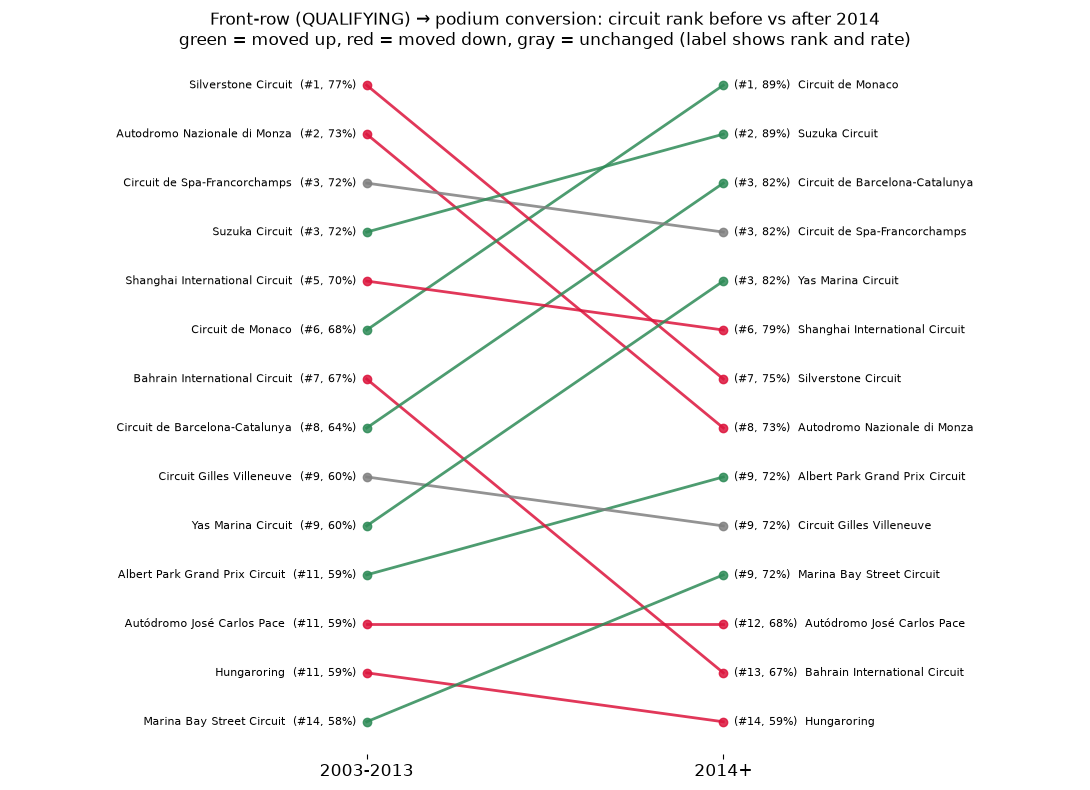

In [37]:
# ── Slope chart (qualifying version, 2003-2013 vs 2014+) ─────────────────────
wq = wq.copy()
wq['rank_change'] = wq['rank_pre_quali'] - wq['rank_post_quali']   # positive = moved up

fig, ax = plt.subplots(figsize=(11, 8))

left  = wq.sort_values(['rank_pre_quali',  'rate_pre-2014'], ascending=[True, False]).reset_index()
right = wq.sort_values(['rank_post_quali', 'rate_2014+'],    ascending=[True, False]).reset_index()
ypos_left  = {c: i + 1 for i, c in enumerate(left['circuit'])}
ypos_right = {c: i + 1 for i, c in enumerate(right['circuit'])}

for circuit, row in wq.iterrows():
    color = 'seagreen' if row['rank_change'] > 0 else ('crimson' if row['rank_change'] < 0 else 'gray')
    yl, yr = ypos_left[circuit], ypos_right[circuit]
    ax.plot([0, 1], [yl, yr], color=color, marker='o', linewidth=2, alpha=0.85)
    ax.text(-0.03, yl, f"{circuit[:30]}  (#{int(row['rank_pre_quali'])}, {row['rate_pre-2014']:.0%})",
            ha='right', va='center', fontsize=8)
    ax.text(1.03, yr, f"(#{int(row['rank_post_quali'])}, {row['rate_2014+']:.0%})  {circuit[:30]}",
            ha='left', va='center', fontsize=8)

ax.set_xlim(-1.0, 2.0)
ax.set_xticks([0, 1])
ax.set_xticklabels(['2003-2013', '2014+'], fontsize=12)
ax.set_yticks([])
ax.invert_yaxis()
ax.set_title('Front-row (QUALIFYING) → podium conversion: circuit rank before vs after 2014\n'
             'green = moved up, red = moved down, gray = unchanged (label shows rank and rate)')
for s in ['top', 'right', 'bottom', 'left']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Cara membaca grafik:** setiap garis mewakili satu sirkuit. Hijau = naik peringkat setelah 2014, merah = turun peringkat, abu-abu = tidak berubah. Dibandingkan dengan grafik grid (1950-2013 vs 2014+), garis yang saling bersilangan lebih sedikit, sesuai dengan korelasi Spearman yang lebih tinggi (0,54 vs -0,08).

* **Kenaikan terbesar:** Monaco (peringkat 6 → 1), Barcelona (peringkat 8 → 3), dan Yas Marina (peringkat 9 → 3).
* **Penurunan terbesar:** Silverstone (peringkat 1 → 7), Monza (peringkat 2 → 8), dan Bahrain (peringkat 7 → 13).
* Perubahan satu peringkat (misalnya José Carlos Pace dari peringkat 11 → 12) masih dalam batas noise dan tidak diinterpretasikan.

## Q1 Jawaban Akhir: Sirkuit mana yang mengubah start barisan depan menjadi podium, dan apakah itu berubah setelah 2014?

**Jawaban.** Pembalap barisan depan finis di podium sekitar 60% dari waktu di seluruh tahun (definisi grid, 1950-2024) dan sekitar 71% dari 2003 ke atas (definisi kualifikasi). Di antara sirkuit dengan data cukup, peringkat berubah secara moderat setelah 2014 (Spearman 0,54, kualifikasi, 2003-2013 vs 2014+).

* **Konversi tertinggi setelah 2014:** Monaco dan Suzuka (89%), lalu Yas Marina, Barcelona, dan Spa (82%).
* **Penanjak terbesar:** Monaco, Barcelona, Yas Marina. **Penurun terbesar:** Silverstone, Monza, Bahrain.
* Kualifikasi vs grid nyaris tidak mengubah peringkat (Spearman 0,88-0,89 pada jendela 2003+ yang sama), karena hanya sekitar 6% pembalap barisan depan kualifikasi (50 dari 852) yang start dari slot grid berbeda.
* Perbandingan grid 1950-2013 vs 2014+ tampak seperti perubahan total (Spearman -0,08), tetapi ini sebagian besar didorong oleh era yang sangat lama dan kurang andal: pada jendela 2003+ yang sama, versi grid menghasilkan 0,36.

**Grain.** Satu baris per (`raceId`, `driverId`). Pembalap yang tidak start (`positionText` F dan W) dihapus, duplikat mobil bersama disederhanakan (pertahankan finis terklasifikasi, jika tidak ada pertahankan `positionOrder` yang lebih baik), dan Indianapolis 500 (1950-1960) dikeluarkan. Satu start barisan depan adalah satu baris seperti itu dengan posisi 1 atau 2.

**Data yang hilang.** Data kualifikasi tidak ada sebelum 1994 dan tidak merata sampai 2002, sehingga versi kualifikasi hanya memakai 2003+ (cakupan lengkap). Sebanyak 21 dari 8.910 entri (0,2%) tidak punya posisi kualifikasi dan gugur dari hitungan barisan depan.

**Batas waktu pra-balapan.** Posisi grid dan posisi kualifikasi sama-sama diketahui sebelum balapan dimulai, sehingga keduanya valid sebagai informasi pra-balapan. Hasil podium hanya yang kita ukur, tidak pernah menjadi input.

**Pilihan metode.** Minimum 10 start barisan depan per sirkuit di setiap era (dipilih dari histogram); sirkuit harus muncul di kedua era; yang dibandingkan adalah peringkat dan tingkat konversi, tidak pernah jumlah mentah, karena panjang kedua era berbeda.

**Keterbatasan.** Tingkat konversi dari 10-24 start memiliki ketidakpastian sekitar ±15 poin persentase, sehingga perubahan peringkat kecil hanyalah noise. Tingkat yang lebih tinggi setelah 2014 menunjukkan bahwa sebagian perubahan mencerminkan era (mobil dominan dan andal), bukan sirkuitnya; ini belum kita uji. Kualitas mobil juga tercampur dengan sirkuit (tim dominan di trek tertentu). Aturan yang hanya mengeluarkan F dan W (mempertahankan D, E, N) masih menunggu konfirmasi tim; mengubahnya hanya memengaruhi 350 dari sekitar 26.800 baris.

---

## Q2 · Home races effect

**Pertanyaan:** Apakah pembalap lebih sering finis di podium ketika balapan di sirkuit di negara asal mereka, setelah mengontrol posisi start?

**Mengapa ini penting untuk pemodelan:** Jika ada dorongan balapan kandang yang nyata di luar apa yang dijelaskan posisi grid, maka `is_home` adalah fitur yang valid dan aman dari kebocoran data (leakage-safe), karena diketahui sebelum balapan dimulai.

**Pemeriksaan batas waktu pra-balapan:** `is_home` diturunkan dari kebangsaan pembalap (statis, selalu diketahui) dan negara sirkuit (tetap untuk setiap balapan). Tidak ada informasi pasca-balapan yang dipakai. ✅

**Grain:** Satu baris per pembalap per balapan (sama dengan tabel pemodelan), dari `results_df` yang digabung dengan `drivers_df` (kebangsaan) serta `races_df` + `circuits_df` (negara sirkuit). Pembalap yang tidak start (`positionText` ∈ {F, W, E}, aturan yang sama dengan tabel pemodelan) dan Indianapolis 500 (`circuitId = 69`, 1950-1960) dikeluarkan.

In [38]:
# ── Q2 Step 1: Build nationality → country mapping and is_home flag ───────

NATIONALITY_TO_COUNTRY = {
    'British':       'UK',
    'German':        'Germany',
    'Italian':       'Italy',
    'French':        'France',
    'Spanish':       'Spain',
    'Brazilian':     'Brazil',
    'Australian':    'Australia',
    'Japanese':      'Japan',
    'Canadian':      'Canada',
    'American':      'USA',
    'Dutch':         'Netherlands',
    'Austrian':      'Austria',
    'Mexican':       'Mexico',
    'Belgian':       'Belgium',
    'Swiss':         'Switzerland',
    'Argentine':     'Argentina',
    'South African': 'South Africa',
    'Hungarian':     'Hungary',
    'Malaysian':     'Malaysia',
    'Chinese':       'China',
    'Bahraini':      'Bahrain',
    'Emirati':       'UAE',
    'Monegasque':    'Monaco',
    'Portuguese':    'Portugal',
}

q2_df = results_df[~results_df['positionText'].isin(MODEL_NON_STARTER_CODES)].copy()

q2_df = q2_df.merge(
    races_df.reset_index()[['raceId', 'year', 'circuitId']],
    on='raceId', how='left'
)

# Exclude Indianapolis 500
q2_df = q2_df[~((q2_df['circuitId'] == 69) & (q2_df['year'] <= 1960))]

q2_df = q2_df.merge(
    circuits_df.reset_index()[['circuitId', 'country']].rename(columns={'country': 'circuit_country'}),
    on='circuitId', how='left'
)
q2_df = q2_df.merge(
    drivers_df.reset_index()[['driverId', 'nationality']],
    on='driverId', how='left'
)

q2_df['home_country'] = q2_df['nationality'].map(NATIONALITY_TO_COUNTRY)
q2_df['is_home'] = (q2_df['home_country'] == q2_df['circuit_country']).astype(int)
q2_df['podium']  = (q2_df['positionOrder'] <= 3).astype(int)

total_home = q2_df['is_home'].sum()
print(f"Working table: {len(q2_df):,} rows")
print(f"Home-race starts: {total_home:,} ({100*total_home/len(q2_df):.1f}% of all starts)")
print()
print("Home-race starts by nationality:")
print(q2_df[q2_df['is_home']==1].groupby('nationality')['raceId'].count().sort_values(ascending=False).to_string())

Working table: 25,046 rows
Home-race starts: 2,317 (9.3% of all starts)

Home-race starts by nationality:
nationality
American         516
British          451
Italian          401
French           207
German           199
Brazilian        113
Spanish           60
Belgian           60
Japanese          53
South African     46
Argentine         45
Canadian          32
Austrian          29
Australian        28
Mexican           24
Dutch             23
Swiss             13
Monegasque         8
Portuguese         5
Hungarian          2
Chinese            1
Malaysian          1


In [39]:
# Q2 step 2 : Band grid positions into 4 groups

q2_df['grid_band'] = pd.cut(
    q2_df['grid'],
    bins=[0, 3, 6, 10, 100],
    labels=['P1-3 (front)', 'P4-6', 'P7-10', 'P11+']
)

# Drop grid = 0 (pit lane staters = started the race but position unknown)
q2_clean = q2_df[q2_df['grid'] > 0].dropna(subset=['grid_band']).copy()

print("Rows per grid band:")
print(q2_clean['grid_band'].value_counts().sort_index())
print()
print("Home race rows per grid band:")
print(q2_clean[q2_clean['is_home']==1]['grid_band'].value_counts().sort_index())

Rows per grid band:
grid_band
P1-3 (front)     3379
P4-6             3382
P7-10            4501
P11+            13704
Name: count, dtype: int64

Home race rows per grid band:
grid_band
P1-3 (front)     269
P4-6             260
P7-10            386
P11+            1399
Name: count, dtype: int64


is_home      Non-home   Home Non-home starts Home starts Δ (home − non-home)
grid_band                                                                   
P1-3 (front)    0.555  0.535            3110         269              -0.020
P4-6            0.261  0.242            3122         260              -0.019
P7-10           0.094  0.088            4115         386              -0.005
P11+            0.017  0.016           12305        1399              -0.000


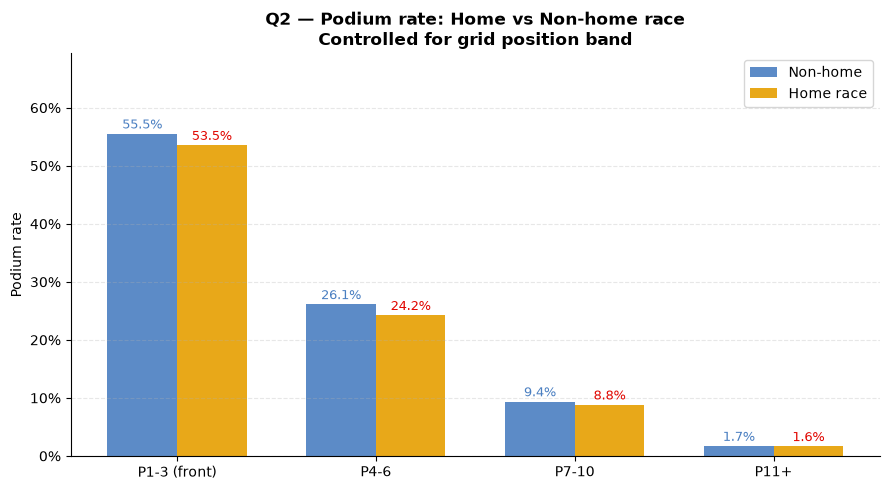

In [40]:
# Q2 Step 3: Grouped podium rates by grid band and home/away

# Keep the grid-band order in the same logical order as the start positions.
# observed=False retains all four bands even if one subgroup is empty.
rates = (
    q2_clean
    .groupby(['grid_band', 'is_home'], observed=True)
    .agg(starts=('podium', 'count'), podiums=('podium', 'sum'))
    .assign(rate=lambda d: d['podiums'] / d['starts'])
    .reset_index()
)
rates = rates[rates['starts'] >= 20]   # drop cells with < 20 starts

rates_pivot = rates.pivot(index='grid_band', columns='is_home', values='rate').rename(
    columns={0: 'Non-home', 1: 'Home'}
)
starts_pivot = rates.pivot(index='grid_band', columns='is_home', values='starts').rename(
    columns={0: 'Non-home starts', 1: 'Home starts'}
)
summary = rates_pivot.join(starts_pivot)
summary['Δ (home − non-home)'] = summary['Home'] - summary['Non-home']
print(summary.map(lambda x: f'{x:.3f}' if isinstance(x, float) else str(x)))    


# Grouped bars make the home/away comparison explicit within each grid band.
bands = rates_pivot.index.tolist()
x = np.arange(len(bands))
w = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_non  = ax.bar(x - w/2, rates_pivot['Non-home'], w, color='#4a7fc1', label='Non-home', alpha=0.9)
bars_home = ax.bar(x + w/2, rates_pivot['Home'],     w, color='#E69F00', label='Home race', alpha=0.9)

for bar in bars_non:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.004, f'{h:.1%}', ha='center', va='bottom', fontsize=9, color='#4a7fc1')
for bar in bars_home:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.004, f'{h:.1%}', ha='center', va='bottom', fontsize=9, color='#e10600')

ax.set_xticks(x)
ax.set_xticklabels(bands, fontsize=10)
ax.set_ylabel('Podium rate', fontsize=10)
ax.set_title('Q2 — Podium rate: Home vs Non-home race\nControlled for grid position band', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.set_ylim(0, rates_pivot.max().max() * 1.25)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [41]:
# ── Q2 Step 4: Logistic regression — podium ~ is_home + C(grid_band) ─────────
globals().pop('C', None)
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")


q2_reg = q2_clean[['podium', 'is_home', 'grid_band']].dropna().copy()
q2_reg['grid_band'] = q2_reg['grid_band'].astype(str)  # categorical for regression

q2_model = smf.logit('podium ~ is_home + C(grid_band)', data=q2_reg).fit(disp=False)

q2_coef = q2_model.params['is_home']
ci_lo, ci_hi = q2_model.conf_int().loc['is_home']
pval    = q2_model.pvalues['is_home']

print("=" * 55)
print("Logistic regression: podium ~ is_home + C(grid_band)")
print("=" * 55)
print(f"  is_home coefficient : {q2_coef:+.4f}")
print(f"  Odds ratio          : {np.exp(q2_coef):.4f}  (1.0 = no effect)")
print(f"  95% CI (odds ratio) : [{np.exp(ci_lo):.4f}, {np.exp(ci_hi):.4f}]")
print(f"  p-value             : {pval:.4f}  {'✅ significant (p < 0.05)' if pval < 0.05 else '❌ not significant (p ≥ 0.05)'}")



Logistic regression: podium ~ is_home + C(grid_band)
  is_home coefficient : -0.0755
  Odds ratio          : 0.9272  (1.0 = no effect)
  95% CI (odds ratio) : [0.7918, 1.0859]
  p-value             : 0.3485  ❌ not significant (p ≥ 0.05)


## Q2 Findings

* **Odds ratio > 1,0** → pembalap kandang lebih mungkin naik podium, dengan posisi grid dikontrol.
* **Odds ratio ≈ 1,0 atau p ≥ 0,05** → tidak ada keuntungan kandang yang signifikan secara statistik setelah posisi grid ditahan konstan. Dorongan yang tampak hanya dijelaskan oleh kualifikasi yang lebih baik di kandang sendiri.

Grafik batang menunjukkan tingkat mentah per kelompok grid, sedangkan regresi logistik memisahkan efek kandang di atasnya.

**Limitations**

* Efek balapan kandang tidak bisa dipisahkan dari keakraban dengan sirkuit (pembalap yang membalap di sirkuit kandangnya selama 10 tahun otomatis punya pengetahuan lokal).
* Kebangsaan yang tidak punya GP kandang di kalender (misalnya Finlandia, Afrika Selatan setelah 1993, dll.) dikeluarkan, karena `is_home`-nya selalu 0.
* Sampelnya tidak seimbang: pembalap Inggris, Jerman, dan Italia menyumbang ratusan baris balapan kandang, sedangkan yang lain jauh lebih sedikit.


### Q2 robustness: control for the exact grid slot, add era, cluster by race

Regresi pertama memakai 4 pita grid. Pita "P11+" mencampur P11 dan P25, sehingga masih ada sisa confounding. Kita fit ulang dengan:

* pita grid yang asli,
* satu dummy per slot grid (dibatasi sampai 20),
* satu dummy per slot grid ditambah dekade (balapan kandang lebih sering terjadi pada era tertentu).

Baris dari balapan yang sama tidak independen, sehingga standard error dikelompokkan (clustered) berdasarkan `raceId`. Kita juga mengeluarkan setiap kebangsaan kandang yang besar satu per satu untuk memeriksa bahwa hasilnya tidak didorong oleh satu negara saja.

Home starts: 2314 | home podium rate 11.4% | non-home podium rate 13.8% (raw, NOT controlled)


,odds_ratio,ci_low,ci_high,p_value
spec,,,,
grid bands,0.927,0.804,1.070,0.301
exact grid slot,0.943,0.815,1.092,0.432
exact grid slot + decade,0.933,0.800,1.088,0.375
without American home starts,0.959,0.808,1.139,0.636
without British home starts,0.859,0.722,1.021,0.085
without Italian home starts,0.962,0.822,1.126,0.628
without French home starts,0.928,0.790,1.090,0.365
without German home starts,0.936,0.795,1.101,0.423
without Brazilian home starts,0.928,0.792,1.088,0.358


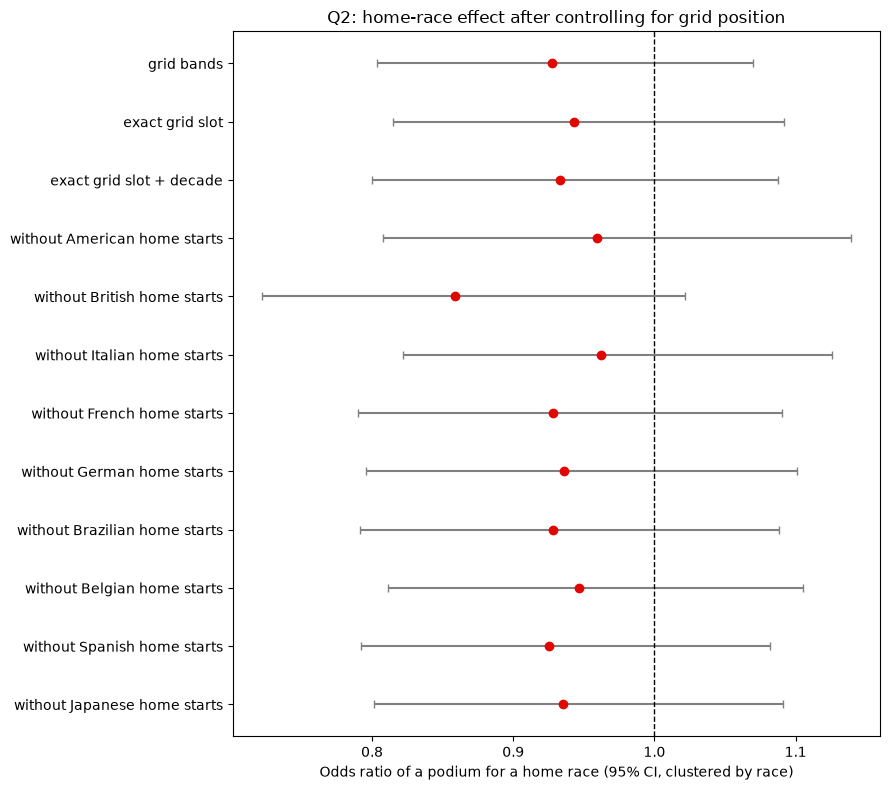

In [42]:
import statsmodels.formula.api as smf

d2 = q2_clean.copy()
d2['grid_c'] = d2['grid'].clip(upper=20)
d2['decade'] = (d2['year'] // 10 * 10).astype(str)
d2['grid_band'] = d2['grid_band'].astype(str)

print(f"Home starts: {int(d2['is_home'].sum())} | home podium rate {d2.loc[d2.is_home==1,'podium'].mean():.1%} "
      f"| non-home podium rate {d2.loc[d2.is_home==0,'podium'].mean():.1%} (raw, NOT controlled)")

specs = {'grid bands':               'podium ~ is_home + C(grid_band)',
         'exact grid slot':          'podium ~ is_home + C(grid_c)',
         'exact grid slot + decade': 'podium ~ is_home + C(grid_c) + C(decade)'}
out = []
for label, f in specs.items():
    r = smf.logit(f, data=d2).fit(disp=False, cov_type='cluster', cov_kwds={'groups': d2['raceId']})
    lo, hi = r.conf_int().loc['is_home']
    out.append({'spec': label, 'odds_ratio': np.exp(r.params['is_home']),
                'ci_low': np.exp(lo), 'ci_high': np.exp(hi), 'p_value': r.pvalues['is_home']})

# leave-one-nationality-out on the strictest spec
big = d2[d2.is_home == 1]['nationality'].value_counts()
for nat in big[big >= 50].index:
    sub = d2[~((d2.is_home == 1) & (d2.nationality == nat))]
    r = smf.logit(specs['exact grid slot + decade'], data=sub).fit(
        disp=False, cov_type='cluster', cov_kwds={'groups': sub['raceId']})
    lo, hi = r.conf_int().loc['is_home']
    out.append({'spec': f'without {nat} home starts', 'odds_ratio': np.exp(r.params['is_home']),
                'ci_low': np.exp(lo), 'ci_high': np.exp(hi), 'p_value': r.pvalues['is_home']})

q2_out = pd.DataFrame(out).set_index('spec')
display(q2_out.round(3))

fig, ax = plt.subplots(figsize=(9, 0.5 * len(q2_out) + 2))
y = np.arange(len(q2_out))[::-1]
ax.errorbar(q2_out['odds_ratio'], y,
            xerr=[q2_out['odds_ratio'] - q2_out['ci_low'], q2_out['ci_high'] - q2_out['odds_ratio']],
            fmt='o', color='#e10600', ecolor='gray', capsize=3)
ax.axvline(1.0, color='black', linestyle='--', linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(q2_out.index)
ax.set_xlabel('Odds ratio of a podium for a home race (95% CI, clustered by race)')
ax.set_title('Q2: home-race effect after controlling for grid position')
plt.tight_layout(); 
plt.show()

## Q2 final answer: is there a home-race effect?

**Answer.** After holding the exact grid slot fixed, a home race multiplies the odds of a podium by 0.94 (95% CI 0.82 to 1.09, p = 0.43). The interval includes 1, so there is no statistically clear home effect. The raw numbers point the other way (home podium rate 11.4% on 2,314 home starts against 13.8% for non-home starts), but that raw gap is not controlled for starting position and is not statistically distinguishable from zero once the grid slot is held fixed.

**Robustness.** The three specifications give almost the same answer: odds ratio 0.927 (grid bands, p = 0.30), 0.943 (exact grid slot, p = 0.43) and 0.933 (exact grid slot + decade, p = 0.38). Dropping the home starts of one large nationality at a time keeps the odds ratio between 0.859 (without British home starts, p = 0.085) and 0.962 (without Italian home starts, p = 0.63). Every one of the 12 confidence intervals includes 1. The closest to significance is the fit without British drivers, which points to a lower, not a higher, podium chance at home, and it is still above p = 0.05.

**Grain / missingness.** One row per (raceId, driverId), non-starters (F, W, E) and the Indianapolis 500 removed, grid = 0 rows dropped from this analysis. `is_home` uses a hand-made nationality -> country map; nationalities without a home Grand Prix are always 0.

**Pre-race cutoff.** `is_home` comes from nationality and circuit country, both known before the race. Valid feature.

**Limitations.** A home effect cannot be separated from circuit familiarity or from crowd and sponsor effects. Home-race starts are few for most nationalities (British, German, Italian dominate). Car strength is not controlled, so a strong home driver in a fast car can still look like a home effect. This is an association, not a causal estimate. A non-significant result means we found no clear effect, not that a small one is ruled out: the intervals still allow anything from about -18% to +9% in the odds.

---

## Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

**Grouping the 139 statuses.** `status.csv` has 139 reasons a race ended, and the brief defines a mechanical retirement as a car component failing, excluding crashes, driver causes and regulation decisions. No column says this directly, so we grouped the statuses by hand into four classes: **Mechanical** (engine, gearbox, brakes...), **Non-Mechanical** (collisions, spins, disqualification, illness...), **Borderline** (Retired, Puncture, Tyre, wing damage, which can come from contact) and **Finished** (+N Laps). An assertion makes sure no status is left unclassified.

In [43]:
# ── Manual grouping of the 139 statuses ───────────────────────────────────────
# Mechanical = a car component failed (brief's definition). Crashes, driver
# causes and regulation decisions are excluded.

mechanical_terms = [
    'Alternator', 'Axle', 'Battery', 'Brake duct', 'Brakes', 'CV joint', 'Chassis',
    'Clutch', 'Cooling system', 'Crankshaft', 'Differential', 'Distributor', 'Driveshaft',
    'Drivetrain', 'ERS', 'Electrical', 'Electronics', 'Engine', 'Engine fire',
    'Engine misfire', 'Exhaust', 'Fuel', 'Fuel leak', 'Fuel pipe', 'Fuel pressure',
    'Fuel pump', 'Fuel rig', 'Fuel system', 'Gearbox', 'Halfshaft', 'Handling',
    'Heat shield fire', 'Hydraulics', 'Ignition', 'Injection', 'Launch control',
    'Magneto', 'Mechanical', 'Oil leak', 'Oil line', 'Oil pipe', 'Oil pressure',
    'Oil pump', 'Out of fuel', 'Overheating', 'Pneumatics', 'Power Unit', 'Power loss',
    'Radiator', 'Spark plugs', 'Steering', 'Supercharger', 'Suspension', 'Technical',
    'Throttle', 'Track rod', 'Transmission', 'Turbo', 'Undertray', 'Vibrations',
    'Water leak', 'Water pipe', 'Water pressure', 'Water pump', 'Wheel bearing',
    'Wheel nut', 'Wheel rim',
    'Wheel',                      # added here instead of a patch cell (judgment call)
]

# Borderline: can come from contact or track conditions, so excluded from the
# strict definition and tested in the "broad" sensitivity check.
borderline_terms = ['Damage', 'Debris', 'Puncture', 'Tyre', 'Tyre puncture',
                    'Front wing', 'Rear wing', 'Broken wing', 'Retired']

# Crash, driver, medical, or regulation causes
non_mechanical_terms = [
    'Accident', 'Collision', 'Collision damage', 'Disqualified', 'Driver unwell',
    'Excluded', 'Eye injury', 'Fatal accident', 'Fire', 'Illness', 'Injured', 'Injury',
    'Physical', 'Safety', 'Safety belt', 'Safety concerns', 'Seat', 'Driver Seat',
    'Spun off', 'Stalled', 'Underweight', 'Withdrew', '107% Rule', 'Did not prequalify',
    'Did not qualify', 'Not classified', 'Not restarted',
    'Refuelling',                 # added here instead of a patch cell
]

# Finished / classified (Finished, +1 Lap, +2 Laps, ...)
finished_terms = [s for s in status_df['status'].unique() if 'Lap' in s or s == 'Finished']

def map_status(status_str):
    if status_str in mechanical_terms:
        return 'Mechanical'
    elif status_str in borderline_terms:
        return 'Borderline/Other'
    elif status_str in non_mechanical_terms:
        return 'Non-Mechanical'
    elif status_str in finished_terms:
        return 'Finished'
    else:
        return 'Other'

status_clean = status_df.copy()                      # raw table stays untouched
status_clean['failure_type'] = status_clean['status'].apply(map_status)

# Every status must be classified, otherwise fail loudly
unmapped = status_clean.loc[status_clean['failure_type'] == 'Other', 'status'].tolist()
assert not unmapped, f"Unmapped statuses: {unmapped}"

print(status_clean['failure_type'].value_counts())

failure_type
Mechanical          68
Finished            34
Non-Mechanical      28
Borderline/Other     9
Name: count, dtype: int64


## Interpretasi Hasil Pengelompokan Status

Dari 139 status unik yang dikelompokkan, hasilnya adalah:

| Kategori | Jumlah Status | Persentase |
|---|---:|---:|
| Mechanical | 68 | 48,9% |
| Finished | 34 | 24,5% |
| Non-Mechanical | 28 | 20,1% |
| Borderline/Other | 9 | 6,5% |
| **Total** | **139** | **100%** |

Kategori **Mechanical** memiliki jumlah status terbanyak, yaitu 68 status atau sekitar 48,9% dari seluruh status unik. Kategori ini mencakup masalah pada komponen atau sistem mobil, seperti mesin, transmisi, rem, dan suspensi.

Kategori **Finished** mencakup 34 status (24,5%) yang menandakan pembalap menyelesaikan atau diklasifikasikan dalam balapan. Sementara itu, **Non-Mechanical** mencakup 28 status (20,1%) yang berkaitan dengan kecelakaan, kondisi pembalap, atau keputusan regulasi. Sebanyak 9 status (6,5%) dimasukkan ke kategori **Borderline/Other** karena penyebabnya tidak dapat dipastikan sebagai kegagalan mekanis berdasarkan definisi yang digunakan.

Pemeriksaan `assert` tidak menghasilkan error, yang menunjukkan bahwa semua status telah dipetakan ke kategori dan tidak ada status yang tersisa sebagai `Other` yang belum terklasifikasi.

**Catatan:** Angka tersebut menunjukkan jumlah jenis status unik, bukan jumlah kejadian atau jumlah pembalap yang mengalami setiap status. Karena itu, hasil ini tidak dapat digunakan langsung untuk menyimpulkan frekuensi kegagalan mekanis dalam balapan.

In [44]:
races_2014_onward = races_df[races_df['year'] >= 2014].index
active_constructor_ids = results_df[results_df['raceId'].isin(races_2014_onward)]['constructorId'].unique()

constructors_df.loc[constructors_df.index.isin(active_constructor_ids), ['name']]

,name
constructorId,
1,McLaren
3,Williams
4,Renault
5,Toro Rosso
6,Ferrari
9,Red Bull
10,Force India
15,Sauber
51,Alfa Romeo


In [45]:
# ── Team Lineage Mapping (2014–2024) ──────────────────────────────────────────
team_lineage_map = {
    # Red Bull's sister team (Faenza)
    'Toro Rosso': 'AlphaTauri / RB',
    'AlphaTauri': 'AlphaTauri / RB',
    'RB F1 Team': 'AlphaTauri / RB',

    # Silverstone team
    'Force India': 'Aston Martin / Force India',
    'Racing Point': 'Aston Martin / Force India',
    'Aston Martin': 'Aston Martin / Force India',

    # Enstone team (DEBATABLE: ownership and branding changed Lotus -> Renault -> Alpine)
    'Lotus F1': 'Alpine / Renault',
    'Renault': 'Alpine / Renault',
    'Alpine F1 Team': 'Alpine / Renault',

    # Hinwil team (DEBATABLE: Alfa Romeo was a title partner, then a rebrand, of Sauber)
    'Sauber': 'Sauber / Alfa Romeo',
    'Alfa Romeo': 'Sauber / Alfa Romeo',

    # Backmarker team renamed during 2014-2016
    'Manor Marussia': 'Marussia / Manor',
    'Marussia': 'Marussia / Manor',

    # Stable teams (no rename)
    'Ferrari': 'Ferrari',
    'Mercedes': 'Mercedes',
    'Red Bull': 'Red Bull',
    'McLaren': 'McLaren',
    'Williams': 'Williams',
    'Haas F1 Team': 'Haas',
    'Caterham': 'Caterham',
}

constructors_clean = constructors_df.copy()   # raw table stays untouched
constructors_clean['team_lineage'] = (constructors_clean['name']
                                      .map(team_lineage_map)
                                      .fillna(constructors_clean['name']))

# Check: every constructor active 2014-2024 is covered by the map
active_names = constructors_df.loc[constructors_df.index.isin(active_constructor_ids), 'name']
missing = [n for n in active_names if n not in team_lineage_map]
assert not missing, f"Constructors missing from lineage map: {missing}"
print("✓ Lineage map covers all", len(active_names), "constructors active 2014–2024")

✓ Lineage map covers all 20 constructors active 2014–2024


## Team Lineage Decisions

Several constructors changed names between 2014 and 2024. Treating each name as a separate team would split one team’s history across different labels and leave too few starts per team. Therefore, names belonging to the same team were merged:

| Merged Team | Names Merged |
|---|---|
| AlphaTauri / RB | Toro Rosso, AlphaTauri, RB F1 Team |
| Aston Martin / Force India | Force India, Racing Point, Aston Martin |
| Alpine / Renault | Lotus F1, Renault, Alpine F1 Team |
| Sauber / Alfa Romeo | Sauber, Alfa Romeo |
| Marussia / Manor | Marussia, Manor Marussia |

Ferrari, Mercedes, Red Bull, McLaren, Williams, Haas, and Caterham were not renamed and remain separate.

### Judgment Calls

Two merges are debatable:

- **Lotus F1 → Renault → Alpine:** The team changed ownership and branding.
- **Sauber → Alfa Romeo:** This was a title-sponsor partnership and later a rebrand, rather than the creation of a new team.

We merge these names because the factory, staff, and car-building operation continued. This assumes that reliability carries over across each rename.

### Coverage Check

An assertion confirms that all 20 constructors active between 2014 and 2024 are covered by the mapping. This prevents any team from silently remaining unmerged.

In [46]:
# ── Q3 base table: one row per race start, 2014–2024 ──────────────────────────
q3 = results_df.copy()                                   # raw table stays untouched

# Exclude non-starters. Reuses the team-wide constant from the Q1 section,
# so both questions follow the same rule (F = DNQ, W = withdrawn).
q3 = q3[~q3['positionText'].isin(NON_STARTER_CODES)]

# Merge race year
q3 = q3.merge(races_df[['year', 'name']].rename(columns={'name': 'race_name'}),
              left_on='raceId', right_index=True, how='left')

# Filter to 2014+ and define eras
q3 = q3[q3['year'] >= 2014].copy()
q3['era'] = np.where(q3['year'] <= 2021, '2014–2021 (V6 Turbo-Hybrid)', '2022–2024 (Ground Effect)')

# Merge failure classification (from the copy, not the raw status table)
q3 = q3.merge(status_clean[['status', 'failure_type']], left_on='statusId', right_index=True, how='left')
q3['is_mechanical'] = (q3['failure_type'] == 'Mechanical').astype(int)                           # strict
q3['is_mech_broad'] = q3['failure_type'].isin(['Mechanical', 'Borderline/Other']).astype(int)    # broad

# Merge constructor lineage
q3 = q3.merge(constructors_clean[['name', 'team_lineage']].rename(columns={'name': 'constructor_name'}),
              left_on='constructorId', right_index=True, how='left')

# ── Sanity checks ─────────────────────────────────────────────────────────────
assert not q3.duplicated(['raceId', 'driverId']).any(), "Grain broken: duplicate (raceId, driverId)"
assert q3[['year', 'failure_type', 'team_lineage']].notna().all().all(), "A join left missing values"

print(f"Total entries (2014–2024): {len(q3)}")
print(f"Mechanical retirements (strict): {q3['is_mechanical'].sum()}")
print(f"Mechanical retirements (broad):  {q3['is_mech_broad'].sum()}")

Total entries (2014–2024): 4598
Mechanical retirements (strict): 381
Mechanical retirements (broad):  450



To evaluate the status grouping, we first count which statuses actually resulted in mechanical retirements between 2014 and 2024.

We then calculate each team’s mechanical-retirement rate for each era:

> **Mechanical-retirement rate = mechanical retirements ÷ race starts**

Each rate is reported with a **95% Wilson confidence interval**. Since each team has only a few dozen mechanical retirements, the interval indicates how much the estimated rate could vary by chance.

A team must have at least **30 starts in an era** to be included. This threshold is applied separately to each era so teams that competed in only one era—such as Caterham and Marussia/Manor—can still be shown for that era.

In [47]:
# What drives the mechanical retirements?
top = (q3[q3['failure_type'].isin(['Mechanical', 'Borderline/Other'])]
       .groupby(['failure_type', 'status']).size()
       .sort_values(ascending=False).head(25).reset_index(name='count'))
display(top)

mech_total = q3['is_mechanical'].sum()
top5 = (top[top['failure_type'] == 'Mechanical'].head(5)['count'].sum())
print(f"Top 5 mechanical statuses = {top5} of {mech_total} mechanical retirements ({top5/mech_total:.0%})")

# ── Rates per team and era, with 95% Wilson confidence intervals ──────────────
from statsmodels.stats.proportion import proportion_confint

Q3_MIN_STARTS = 30   # minimum starts per team IN EACH ERA (applied per era, not jointly)

def rates(flag):
    g = (q3.groupby(['era', 'team_lineage'])
           .agg(starts=(flag, 'count'), fails=(flag, 'sum')).reset_index())
    g = g[g['starts'] >= Q3_MIN_STARTS]
    g['rate'] = g['fails'] / g['starts']
    g[['lo', 'hi']] = [proportion_confint(f, n, method='wilson')
                       for f, n in zip(g['fails'], g['starts'])]
    g['rank'] = g.groupby('era')['rate'].rank(ascending=False, method='min')
    return g

strict, broad = rates('is_mechanical'), rates('is_mech_broad')

for era in strict['era'].unique():
    print(era)
    display(strict[strict['era'] == era].sort_values('rank').round(3))

,failure_type,status,count
0,Mechanical,Engine,79
1,Borderline/Other,Retired,49
2,Mechanical,Brakes,48
3,Mechanical,Gearbox,40
4,Mechanical,Power Unit,39
5,Mechanical,Suspension,25
6,Mechanical,Hydraulics,14
7,Mechanical,Electrical,14
8,Mechanical,Power loss,12
9,Mechanical,Wheel,11


Top 5 mechanical statuses = 231 of 381 mechanical retirements (61%)
2014–2021 (V6 Turbo-Hybrid)


,era,team_lineage,starts,fails,rate,lo,hi,rank
3,2014–2021 (V6 Turbo-Hybrid),Caterham,33,7,0.212,0.107,0.378,1.0
0,2014–2021 (V6 Turbo-Hybrid),AlphaTauri / RB,319,46,0.144,0.110,0.187,2.0
1,2014–2021 (V6 Turbo-Hybrid),Alpine / Renault,318,44,0.138,0.105,0.181,3.0
7,2014–2021 (V6 Turbo-Hybrid),McLaren,316,43,0.136,0.103,0.178,4.0
9,2014–2021 (V6 Turbo-Hybrid),Red Bull,318,34,0.107,0.078,0.146,5.0
5,2014–2021 (V6 Turbo-Hybrid),Haas,241,23,0.095,0.064,0.139,6.0
10,2014–2021 (V6 Turbo-Hybrid),Sauber / Alfa Romeo,319,26,0.082,0.056,0.117,7.0
11,2014–2021 (V6 Turbo-Hybrid),Williams,319,24,0.075,0.051,0.110,8.0
6,2014–2021 (V6 Turbo-Hybrid),Marussia / Manor,108,7,0.065,0.032,0.128,9.0
2,2014–2021 (V6 Turbo-Hybrid),Aston Martin / Force India,317,18,0.057,0.036,0.088,10.0


2022–2024 (Ground Effect)


,era,team_lineage,starts,fails,rate,lo,hi,rank
13,2022–2024 (Ground Effect),Alpine / Renault,135,14,0.104,0.063,0.167,1.0
20,2022–2024 (Ground Effect),Sauber / Alfa Romeo,136,12,0.088,0.051,0.148,2.0
12,2022–2024 (Ground Effect),AlphaTauri / RB,136,9,0.066,0.035,0.121,3.0
21,2022–2024 (Ground Effect),Williams,134,8,0.060,0.031,0.113,4.0
15,2022–2024 (Ground Effect),Ferrari,134,7,0.052,0.026,0.104,5.0
14,2022–2024 (Ground Effect),Aston Martin / Force India,134,6,0.045,0.021,0.094,6.0
16,2022–2024 (Ground Effect),Haas,135,6,0.044,0.021,0.094,7.0
18,2022–2024 (Ground Effect),Mercedes,136,6,0.044,0.020,0.093,8.0
19,2022–2024 (Ground Effect),Red Bull,136,5,0.037,0.016,0.083,9.0
17,2022–2024 (Ground Effect),McLaren,136,5,0.037,0.016,0.083,9.0


**What We Learn** Of the **381 mechanical retirements** between 2014 and 2024, five statuses—**Engine, Brakes, Gearbox, Power Unit, and Suspension**—account for **231 retirements (61%)**. This suggests the result does not depend on rare or debatable labels.

**Retired** is the largest borderline status, with **49 occurrences**. That is why we test its inclusion in the sensitivity check below.

**Mechanical-Retirement Rates by Era**

- **2014–2021:** The highest rates are for Caterham (**21.2%**, based on only 33 starts), AlphaTauri/RB (**14.4%**), Alpine/Renault (**13.8%**), and McLaren (**13.6%**).
- **2022–2024:** Alpine/Renault (**10.4%**) and Sauber/Alfa Romeo (**8.8%**) have the highest rates.

In the later era, each team has only **5–14 mechanical retirements** across roughly **135 starts**. Their confidence intervals therefore overlap substantially, so the observed differences should not be treated as clear evidence that one team was less reliable than another.

### Sensitivity Check: Does the Definition of “Mechanical” Change the Answer?

The **strict definition** counts only clear component failures. Borderline statuses such as *Retired*, *Puncture*, *Tyre*, and wing damage are excluded from the main analysis because they may result from contact or track conditions.

To test how much this choice affects the results, we recalculate each team’s mechanical-retirement rate with these borderline statuses included. This is the **broad definition**.

We then compare the team rankings under the strict and broad definitions using **Spearman’s rank correlation**. A correlation of **1** means the rankings are identical.

In [48]:
from scipy.stats import spearmanr

m = strict.merge(broad, on=['era', 'team_lineage'], suffixes=('_strict','_broad'))

for era, g in m.groupby('era'):
    rho, _ = spearmanr(g['rate_strict'], g['rate_broad'])
    print(f"{era}: Spearmen strict vs board = {rho:.2f}")
    display(g[['team_lineage', 'rate_strict', 'rank_strict', 'rate_broad', 'rank_broad']]
            .sort_values('rank_broad').round(3))

2014–2021 (V6 Turbo-Hybrid): Spearmen strict vs board = 0.98


,team_lineage,rate_strict,rank_strict,rate_broad,rank_broad
3,Caterham,0.212,1.0,0.303,1.0
1,Alpine / Renault,0.138,3.0,0.170,2.0
0,AlphaTauri / RB,0.144,2.0,0.163,3.0
7,McLaren,0.136,4.0,0.152,4.0
5,Haas,0.095,6.0,0.120,5.0
9,Red Bull,0.107,5.0,0.116,6.0
10,Sauber / Alfa Romeo,0.082,7.0,0.097,7.0
11,Williams,0.075,8.0,0.097,7.0
6,Marussia / Manor,0.065,9.0,0.083,9.0
2,Aston Martin / Force India,0.057,10.0,0.066,10.0


2022–2024 (Ground Effect): Spearmen strict vs board = 0.99


,team_lineage,rate_strict,rank_strict,rate_broad,rank_broad
13,Alpine / Renault,0.104,1.0,0.104,1.0
20,Sauber / Alfa Romeo,0.088,2.0,0.103,2.0
12,AlphaTauri / RB,0.066,3.0,0.088,3.0
21,Williams,0.060,4.0,0.082,4.0
15,Ferrari,0.052,5.0,0.067,5.0
14,Aston Martin / Force India,0.045,6.0,0.060,6.0
16,Haas,0.044,7.0,0.052,7.0
18,Mercedes,0.044,8.0,0.044,8.0
19,Red Bull,0.037,9.0,0.044,8.0
17,McLaren,0.037,9.0,0.037,10.0


Yang kita pelajari: Definisi yang digunakan hampir tidak berpengaruh. Peringkat strict dan broad hampir identik (Spearman 0,98 untuk 2014–2021 dan 0,99 untuk 2022–2024). Angka broad lebih tinggi, seperti yang diperkirakan, karena lebih banyak status yang dihitung: 0–3 poin untuk sebagian besar tim, dan 9 poin untuk Caterham (hanya 33 start, sehingga angkanya paling sensitif). Perubahan peringkat yang terjadi hanya berupa pertukaran posisi kecil (Alpine dan AlphaTauri/RB bertukar posisi ke-2 dan ke-3 pada 2014–2021, Haas dan Red Bull bertukar posisi ke-5 dan ke-6), dan urutan 2022–2024 tidak berubah kecuali untuk posisi seri. Karena itu, kami mempertahankan definisi strict untuk hasil utama.

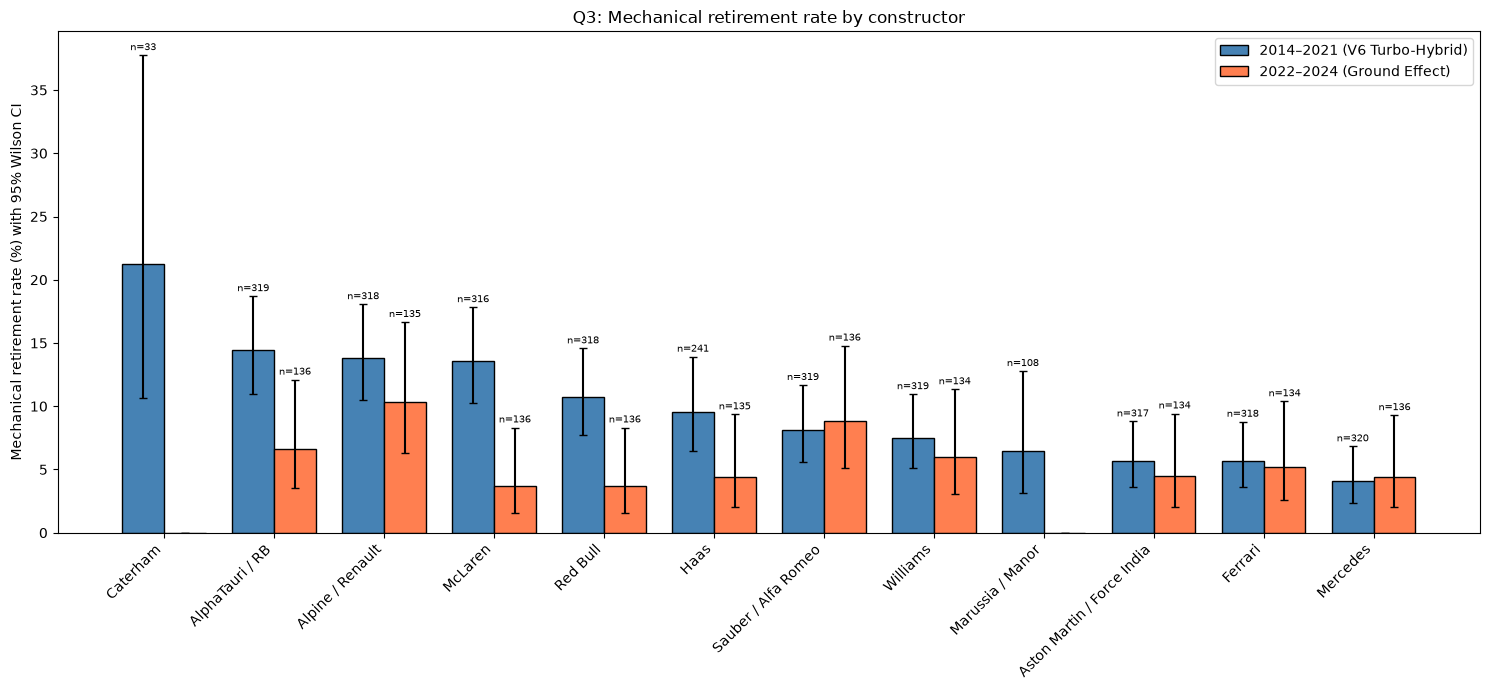

In [49]:
teams = strict.groupby('team_lineage')['rate'].max().sort_values(ascending=False).index.to_list()
x, w = np.arange(len(teams)), 0.38
fig, ax = plt.subplots(figsize=(15, 7))
for k, (era, color) in enumerate(zip(strict['era'].unique(), ['steelblue', 'coral'])):
    g = strict[strict['era'] == era].set_index('team_lineage').reindex(teams)
    err = [(g['rate'] - g['lo']).fillna(0) * 100, (g['hi'] - g['rate']).fillna(0) * 100]
    ax.bar(x + (k - 0.5) * w, g['rate'].fillna(0) * 100, w, yerr=err, capsize=3,
           label=era, color=color, edgecolor='black')
    for xi, (r, n) in enumerate(zip(g['rate'], g['starts'])):
        if pd.notna(r):
            ax.text(xi + (k - 0.5) * w, r * 100 + err[1].iloc[xi] + 0.4,
                    f"n={int(n)}", ha='center', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(teams, rotation=45, ha='right')
ax.set_ylabel('Mechanical retirement rate (%) with 95% Wilson CI')
ax.set_title('Q3: Mechanical retirement rate by constructor')
ax.legend(); 
plt.tight_layout(); 
plt.show()

**Reading the chart**: Each bar is a team's mechanical-retirement rate, the whiskers are 95% confidence intervals and n is the number of starts. Caterham and Marussia/Manor have no 2022–2024 bar because they no longer existed. In 2014–2021 AlphaTauri/RB, Alpine and McLaren sit clearly above Mercedes, Ferrari and Force India. In 2022–2024 most bars fall inside each other's whiskers, so only McLaren's drop is clearly outside the noise. Caterham's very wide whisker shows why a high rate on 33 starts should not be trusted.

## Q3 Final Answer: Mechanical Retirement Rate by Constructor

### Answer

Mechanical failures ended about **8% of all race starts** in 2014–2024 (**381 of 4,598**).

- **2014–2021:** The highest rates were AlphaTauri/RB (**14.4%**), Alpine/Renault (**13.8%**), and McLaren (**13.6%**), well above Ferrari (**5.7%**), Force India (**5.7%**), and Mercedes (**4.1%**). Their 95% confidence intervals do not overlap. Caterham had the highest raw rate (**21.2%**), but it is based on only 33 starts (95% CI: **10.7–37.8%**), so the estimate is uncertain.
- **2022–2024:** Alpine/Renault (**10.4%**) and Sauber/Alfa Romeo (**8.8%**) had the highest point estimates. However, with about 135 starts per team, the confidence intervals overlap with those of most other teams. The results do not clearly identify one team as the least reliable.
- **Change between eras:** McLaren was the only team with a clear improvement (**13.6% → 3.7%**; confidence intervals do not overlap). Other teams’ rates mostly fell, but the changes are within the range of statistical uncertainty. Mercedes and Sauber did not improve.

### Status Grouping

The 139 statuses were manually grouped into **Mechanical**, **Non-Mechanical**, **Borderline**, and **Finished**. Five statuses—**Engine, Brakes, Gearbox, Power Unit, and Suspension**—account for **61%** of mechanical retirements, so the result does not depend on rare, debatable labels such as *Wheel*, *Undertray*, and *Mechanical* (about 6% of cases).

Borderline statuses—such as *Retired*, *Puncture*, *Tyre*, and wing damage—are excluded from the main definition because they may result from contact.

### Sensitivity Analysis

Counting borderline statuses as mechanical raises rates by **0–3 percentage points for most teams** and **9 points for Caterham**, but barely changes the rankings (Spearman correlation: **0.98** for 2014–2021 and **0.99** for 2022–2024).

### Data Grain and Missingness

The analysis uses one row per `(raceId, driverId)` from main-race results only; sprint races are excluded. Non-starters (`positionText` **F** and **W**) are excluded because a car that never started cannot retire.

Teams need at least **30 starts in an era** to be reported. This threshold is applied separately to each era.

### Team Lineage

The following constructor names were merged:

- Toro Rosso → AlphaTauri → RB
- Force India → Racing Point → Aston Martin
- Lotus F1 → Renault → Alpine
- Sauber → Alfa Romeo
- Marussia → Manor

The Renault → Alpine and Sauber → Alfa Romeo merges are judgment calls because ownership and branding changed. Merging them assumes that reliability carries over across those changes.

### Limitations

- The eras have different lengths (**8 seasons vs. 3 seasons**), so rates—not counts—are compared.
- There are few failures per team (**5–14 in 2022–2024**), making the rankings uncertain.
- Failures are attributed to the constructor, not the engine supplier. McLaren, Red Bull, and Toro Rosso’s high rates in 2014–2021 may partly reflect their power-unit suppliers; this is a hypothesis, not tested here.
- Car age, track mix, and driver behaviour are not controlled for.

## Phase 2: Building the Modeling Table

### Step 1: Which Rows Are Real Race Starters?

**Why:** The team disagrees about which `positionText` codes mean “never started.”

- Q1 and Q3 exclude only **F** (failed to qualify) and **W** (withdrawn).
- The cleaning notes and Q2 exclude **F**, **N** (not classified), **W**, **D** (disqualified), and **E** (excluded).

Because this rule determines which rows the modeling table keeps, we test it using the data rather than relying on opinion.

**How:** For each code, we measure two signs of having actually raced:

1. A grid slot greater than 0.
2. At least one completed lap.

**R** (retired) is included as a reference group because those drivers did start the race.

> **Caution:** A car that crashes on the first lap may also have 0 completed laps, so 0 laps alone does not prove that the driver never started.

              rows  share_with_grid  share_with_laps  median_laps
positionText                                                     
F             1368            0.015            0.001          0.0
W              336            0.396            0.015          0.0
N              190            1.000            1.000         56.0
D              151            0.960            0.934         51.0
E                9            0.222            0.111          0.0
R             8897            0.998            0.908         22.0

F/W rows with grid > 0: 153
  of those, with at least 1 lap: 6
count    153.0
mean       0.6
std        3.5
min        0.0
25%        0.0
50%        0.0
75%        0.0
max       25.0
Name: laps, dtype: float64


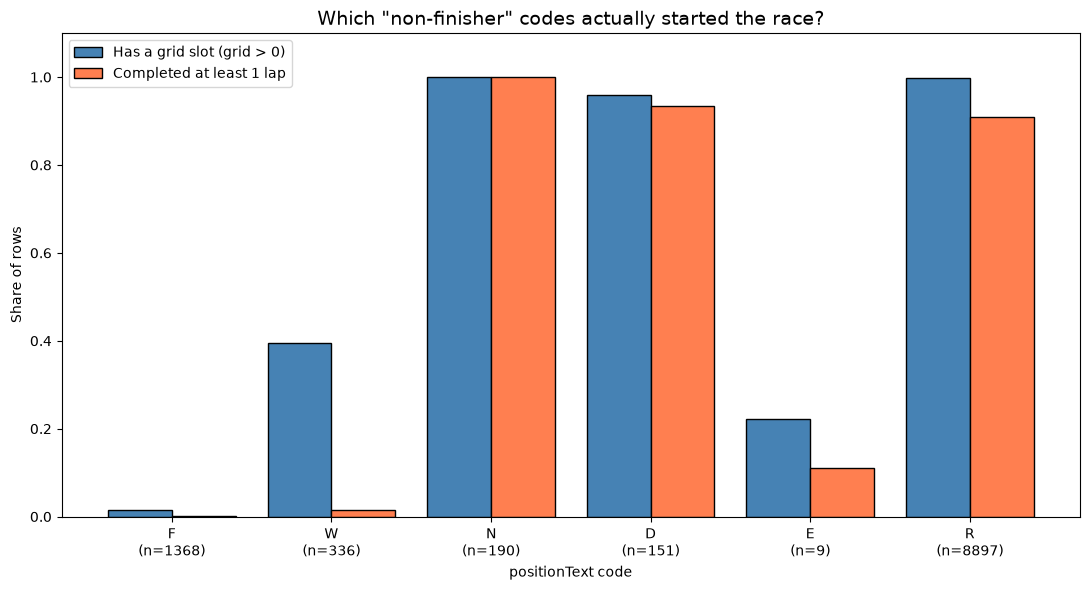

In [50]:
codes = ['F', 'W', 'N', 'D', 'E', 'R']

check = results[results['positionText'].isin(codes)].copy()
check['grid_above_0'] = check['grid'] > 0
check['laps_above_0'] = check['laps'] > 0

summary = (check.groupby('positionText')
           .agg(rows=('laps', 'size'),
                share_with_grid=('grid_above_0', 'mean'),
                share_with_laps=('laps_above_0', 'mean'),
                median_laps=('laps', 'median'))
           .reindex(codes)
           .round(3))
print(summary)

# The F/W rows that have a grid slot: did they actually drive?
fw_with_grid = results[results['positionText'].isin(['F', 'W']) & (results['grid'] > 0)]
print(f"\nF/W rows with grid > 0: {len(fw_with_grid)}")
print(f"  of those, with at least 1 lap: {int((fw_with_grid['laps'] > 0).sum())}")
print(fw_with_grid['laps'].describe().round(1))

# Plot: how many of each code show signs of racing?
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(summary))
ax.bar(x - 0.2, summary['share_with_grid'], width=0.4,
       label='Has a grid slot (grid > 0)', color='steelblue', edgecolor='black')
ax.bar(x + 0.2, summary['share_with_laps'], width=0.4,
       label='Completed at least 1 lap', color='coral', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels([f"{c}\n(n={int(summary.loc[c, 'rows'])})" for c in summary.index])
ax.set_xlabel('positionText code')
ax.set_ylabel('Share of rows')
ax.set_ylim(0, 1.1)
ax.set_title('Which "non-finisher" codes actually started the race?', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()


- **N (not classified)** and **D (disqualified)** rows represent drivers who started the race. All **N** rows and **93% of D** rows recorded at least one lap; their median lap counts were **56** and **51**, respectively. We therefore keep these rows. Excluding them would remove genuine race entries.
- **F (failed to qualify)** and **W (withdrawn)** rows generally represent drivers who did not start. Only **0.1% of F** rows and **1.5% of W** rows recorded any laps; the median was **0**.
- **E (excluded)** rows mostly represent drivers who did not start. There are **9 rows**, with a median of **0 laps**, so we treat them like F and W.
- **`positionText`**, not `grid`, **identifies non-starters.** Of the **153 F/W rows** with an assigned grid slot, **147 recorded 0 laps**. A rule based only on grid position would incorrectly keep them.
- **Laps alone are not enough to identify starters.** About **9% of retired (R)** drivers recorded 0 laps, likely because they crashed on the first lap. They still started the race.

### Decision

Exclude **F**, **W**, and **E** (**1,713 rows**). Keep **N**, **D**, and **R**.

This matches the rule used in Q1 and Q3, except that those analyses do not exclude the 9 **E** rows. **Q2 must be rerun using this rule.**


### Why

Every teammate will build features on top of one shared table. It therefore needs a clear grain—**one row per driver per race**—and must include only actual race starters. Features used to predict an outcome must not contain information that becomes available only after the race.

### Rules Applied

1. **Exclude non-starters:** Remove rows where `positionText` is **F**, **W**, or **E**. Step 1 showed these drivers did not race. Keep **N** and **D**, since those drivers did start.
2. **Resolve shared drives:** If the same driver has two rows in the same race, keep one. Prefer the classified finish (numeric `positionText`); otherwise, keep the row with the better `positionOrder`.
3. **Exclude the Indianapolis 500:** Identify it by race name and year (**1950–1960**) so the regular US Grand Prix at the same venue remains included.
4. **Define the target:** Set `podium = 1` when `positionOrder <= 3`; otherwise, set it to `0`.
5. **Keep the required columns:** Retain identifiers, year, round, date, `circuitId`, `grid`, `positionOrder`, and `points`.

### Preventing Data Leakage

`grid` is known before the race and can be used as a feature. `positionOrder`, `points`, and `podium` describe the race outcome: use them to define the target or derive **past-race features using earlier races only**, but never as features for predicting the same race. Drop other post-race columns, including `time`, `laps`, `fastestLap`, and `statusId`.

In [51]:
# MODEL_NON_STARTER_CODES = ['F', 'W', 'E'] comes from the shared-constants cell (N and D did race, so they stay)

funnel = []   # (step, rows) so we can see what each rule removes

# 0. Start from the working copy (the raw table is never touched)
m = results.copy()
funnel.append(('Start (all result rows)', len(m)))

# 1. Remove drivers who never started
m = m[~m['positionText'].isin(MODEL_NON_STARTER_CODES)]
funnel.append(('After removing non-starters (F, W, E)', len(m)))

# 2. One row per (raceId, driverId): prefer a classified finish, else the better positionOrder
m = m.assign(_is_retirement=(~m['positionText'].str.isnumeric()).astype(int))
m = (m.sort_values(['raceId', 'driverId', '_is_retirement', 'positionOrder'])
       .drop_duplicates(['raceId', 'driverId'], keep='first')
       .drop(columns='_is_retirement'))
funnel.append(('After fixing shared-drive duplicates', len(m)))

# 3. Attach race info (races is indexed by raceId)
race_info = races[['year', 'round', 'date', 'circuitId', 'name']].rename(columns={'name': 'race_name'})
m = m.merge(race_info, left_on='raceId', right_index=True, how='left')

# 4. Remove the Indianapolis 500 (1950 to 1960), by name and year
is_indy500 = m['race_name'].str.contains('Indianapolis 500', case=False, na=False) & (m['year'] <= 1960)
m = m[~is_indy500]
funnel.append(('After removing the Indianapolis 500', len(m)))

# 5. Target
m['podium'] = (m['positionOrder'] <= 3).astype(int)

# 6. Keep only the agreed columns, sorted in time order
KEEP = ['raceId', 'driverId', 'constructorId', 'year', 'round', 'date', 'circuitId',
        'grid', 'positionOrder', 'points', 'podium']
modeling = (m[KEEP]
            .sort_values(['date', 'raceId', 'driverId'])
            .copy())

# ---- Checks ----
assert not modeling.duplicated(['raceId', 'driverId']).any(), "Grain broken: duplicate (raceId, driverId)"
assert modeling[['raceId', 'driverId', 'constructorId', 'year', 'circuitId', 'grid', 'podium']].notna().all().all(), "Missing values in key columns"
assert modeling['year'].between(1950, 2024).all(), "Unexpected year"

funnel_df = pd.DataFrame(funnel, columns=['step', 'rows'])
funnel_df['removed'] = -funnel_df['rows'].diff().fillna(0).astype(int)
print(funnel_df.to_string(index=False))
print(f"\nFinal modeling table: {modeling.shape[0]:,} rows x {modeling.shape[1]} columns")
print(f"Podium rate: {modeling['podium'].mean():.1%}")
print(f"Years covered: {modeling['year'].min()} to {modeling['year'].max()}")
modeling.head()

                                 step  rows  removed
              Start (all result rows) 26759        0
After removing non-starters (F, W, E) 25046     1713
 After fixing shared-drive duplicates 24958       88
  After removing the Indianapolis 500 24577      381

Final modeling table: 24,577 rows x 11 columns
Podium rate: 13.7%
Years covered: 1950 to 2024


,raceId,driverId,constructorId,year,round,date,circuitId,grid,positionOrder,points,podium
resultId,,,,,,,,,,,
20036,833,579,51,1950,1,1950-05-13,9,3,12,0.0,0
20042,833,589,105,1950,1,1950-05-13,9,11,18,0.0,0
20030,833,619,151,1950,1,1950-05-13,9,13,6,0.0,0
20029,833,627,154,1950,1,1950-05-13,9,9,5,2.0,0
20041,833,640,105,1950,1,1950-05-13,9,8,17,0.0,0


## Step 3: Validate the Modeling Table

**Why:** Every teammate builds on this table, so we validate it before sharing. We check that:

- The table’s keys are unique.
- Every ID refers to an existing row in its parent table.
- The time-based split works correctly.
- We know how many rows have `grid = 0` (pit-lane starts or missing grid slots).
- The table agrees with the Q1 base table, confirming that both pipelines produce consistent results.

In [52]:
def time_split(df):
    """Split by season: train <= 2019, validation 2020-2021, test >= 2022 (used here to check the modeling table)."""
    train = df[df['year'] <= 2019]
    val   = df[df['year'].between(2020, 2021)]
    test  = df[df['year'] >= 2022]

    # Safety checks: no row lost, no row in two sets, and strictly in time order
    assert len(train) + len(val) + len(test) == len(df)
    assert train['year'].max() < val['year'].min()
    assert val['year'].max() < test['year'].min()
    return train, val, test

In [53]:
# ---------- Key checks helpers ----------
def check_pk(df, name, cols=None):
    """cols=None means the index is the key."""
    if cols is None:
        n_null = int(df.index.isna().sum())
        n_dup  = int(df.index.duplicated().sum())
    else:
        n_null = int(df[cols].isna().any(axis=1).sum())
        n_dup  = int(df.duplicated(cols).sum())
    flag = 'OK     ' if (n_null == 0 and n_dup == 0) else 'PROBLEM'
    print(f'{flag} {name:42} nulls={n_null}  duplicates={n_dup}')

def check_fk(values, parent_index, label):
    orphans = int((~values.dropna().isin(parent_index)).sum())
    flag = 'OK     ' if orphans == 0 else 'PROBLEM'
    print(f'{flag} {label:50} orphan rows={orphans}')

# ---------- Raw tables ----------
print('--- Primary keys (working copies) ---')
for nm, df in [('circuits', circuits), ('constructors', constructors), ('drivers', drivers),
               ('races', races), ('results', results), ('qualifying', qualifying),
               ('status', status), ('driver_standings', driver_standings),
               ('constructor_standings', constructor_standings)]:
    check_pk(df, nm)
check_pk(lap_times, 'lap_times (raceId, driverId, lap)', ['raceId', 'driverId', 'lap'])
check_pk(pit_stops, 'pit_stops (raceId, driverId, stop)', ['raceId', 'driverId', 'stop'])

print('\n--- Foreign keys (working copies) ---')
check_fk(results['raceId'],          races.index,        'results.raceId -> races')
check_fk(results['driverId'],        drivers.index,      'results.driverId -> drivers')
check_fk(results['constructorId'],   constructors.index, 'results.constructorId -> constructors')
check_fk(results['statusId'],        status.index,       'results.statusId -> status')
check_fk(races['circuitId'],         circuits.index,     'races.circuitId -> circuits')
check_fk(qualifying['raceId'],       races.index,        'qualifying.raceId -> races')
check_fk(qualifying['driverId'],     drivers.index,      'qualifying.driverId -> drivers')
check_fk(driver_standings['raceId'], races.index,        'driver_standings.raceId -> races')
check_fk(lap_times['raceId'],        races.index,        'lap_times.raceId -> races')
check_fk(pit_stops['raceId'],        races.index,        'pit_stops.raceId -> races')

print('\nKnown, expected: results rows repeating (raceId, driverId):',
      int(results.duplicated(['raceId', 'driverId']).sum()), '(shared drives, fixed in the modeling table)')

# ---------- Modeling table ----------
print('\n--- Modeling table ---')
check_pk(modeling, 'modeling (resultId index)')
check_pk(modeling, 'modeling (raceId, driverId)', ['raceId', 'driverId'])
check_fk(modeling['raceId'],        races.index,        'modeling.raceId -> races')
check_fk(modeling['driverId'],      drivers.index,      'modeling.driverId -> drivers')
check_fk(modeling['constructorId'], constructors.index, 'modeling.constructorId -> constructors')
check_fk(modeling['circuitId'],     circuits.index,     'modeling.circuitId -> circuits')

# ---------- Time split on the modeling table ----------
train_m, val_m, test_m = time_split(modeling)
print('\n--- Time split ---')
for name, part in [('Train', train_m), ('Val', val_m), ('Test', test_m)]:
    print(f"{name:6} rows={len(part):6,}  years={part['year'].min()}-{part['year'].max()}  podium rate={part['podium'].mean():.1%}")

# ---------- grid = 0 rows ----------
g0 = modeling[modeling['grid'] == 0]
print(f"\n--- grid = 0 ---")
print(f"Rows with grid = 0: {len(g0):,} ({len(g0)/len(modeling):.1%} of the table)")
print(f"Podium rate of grid = 0 rows: {g0['podium'].mean():.1%}")
print(g0.groupby(pd.cut(g0['year'], bins=[1949, 1979, 2000, 2013, 2024]), observed=True).size())

# ---------- Agreement with the Q1 base table ----------
if 'q1' in globals():
    mine = set(zip(modeling['raceId'], modeling['driverId']))
    theirs = set(zip(q1['raceId'], q1['driverId']))
    print(f"\n--- Compared with the Q1 table ---")
    print(f"Only in modeling: {len(mine - theirs)}   Only in Q1 table: {len(theirs - mine)}  (expected: 0 and 9)")

--- Primary keys (working copies) ---
OK      circuits                                   nulls=0  duplicates=0
OK      constructors                               nulls=0  duplicates=0
OK      drivers                                    nulls=0  duplicates=0
OK      races                                      nulls=0  duplicates=0
OK      results                                    nulls=0  duplicates=0
OK      qualifying                                 nulls=0  duplicates=0
OK      status                                     nulls=0  duplicates=0
OK      driver_standings                           nulls=0  duplicates=0
OK      constructor_standings                      nulls=0  duplicates=0
OK      lap_times (raceId, driverId, lap)          nulls=0  duplicates=0
OK      pit_stops (raceId, driverId, stop)         nulls=0  duplicates=0

--- Foreign keys (working copies) ---
OK      results.raceId -> races                            orphan rows=0
OK      results.driverId -> drivers            

### What We Found

All primary-key and foreign-key checks passed. The only repeated `(raceId, driverId)` pairs were the **91 shared drives** in the raw results table: **88** were resolved in the modeling table, and **3** were removed with the non-starters.

The modeling table has **no duplicate keys or orphan IDs** and agrees with the Q1 base table, except for the **9 E rows**.

The time-based split produced:

| Split | Rows | Podium Rate |
|---|---:|---:|
| Train | 22,450 | 13.5% |
| Validation | 775 | 15.1% |
| Test | 1,352 | 15.1% |

Only **80 rows (0.3%)** have `grid = 0`, and none resulted in a podium finish. Of these, **73** were pit-lane starts from 2014 onward.

Because a model could interpret `grid = 0` as the best starting position, we handle these values explicitly in Step 4.

## Step 4: Handle `grid = 0`

**Why:** There are **80 rows** with `grid = 0`, representing pit-lane starts or missing grid slots. A model could interpret `0` as the best starting position, which would be incorrect.

**How:** Keep the original `grid` column and add two columns:

- `grid_is_zero`: a flag indicating whether the original grid value was 0.
- `grid_filled`: the original grid value, with 0 replaced by one slot behind the last grid slot in the same race.

Both added values are based on information available before the race starts, so this step does not introduce data leakage.

## EDA after cleaning: what did the cleaning change?

**Why:** The brief asks us to show the impact of cleaning, not just describe the raw data.

We compare the raw results table (**26,759 rows**) with the final modeling table using the same statistics:

- Number of rows
- Duplicate `(raceId, driverId)` keys
- Podium rate
- Number of drivers per race
- Share of rows with `grid = 0`

Three plots summarize the changes:

1. How many rows each cleaning rule removed.
2. How the podium rate changed across eras.
3. How the number of drivers per race changed.

dataset,raw results,modeling (cleaned)
rows,26759.000000,24577.000000
races,1125.000000,1114.000000
"duplicate (raceId, driverId) rows",91.000000,0.000000
podium rate,0.126948,0.136672
mean entries per race,23.785778,22.061939
share with grid = 0,0.061213,0.003255
rows with positionText F/W/E,1713.000000,0.000000


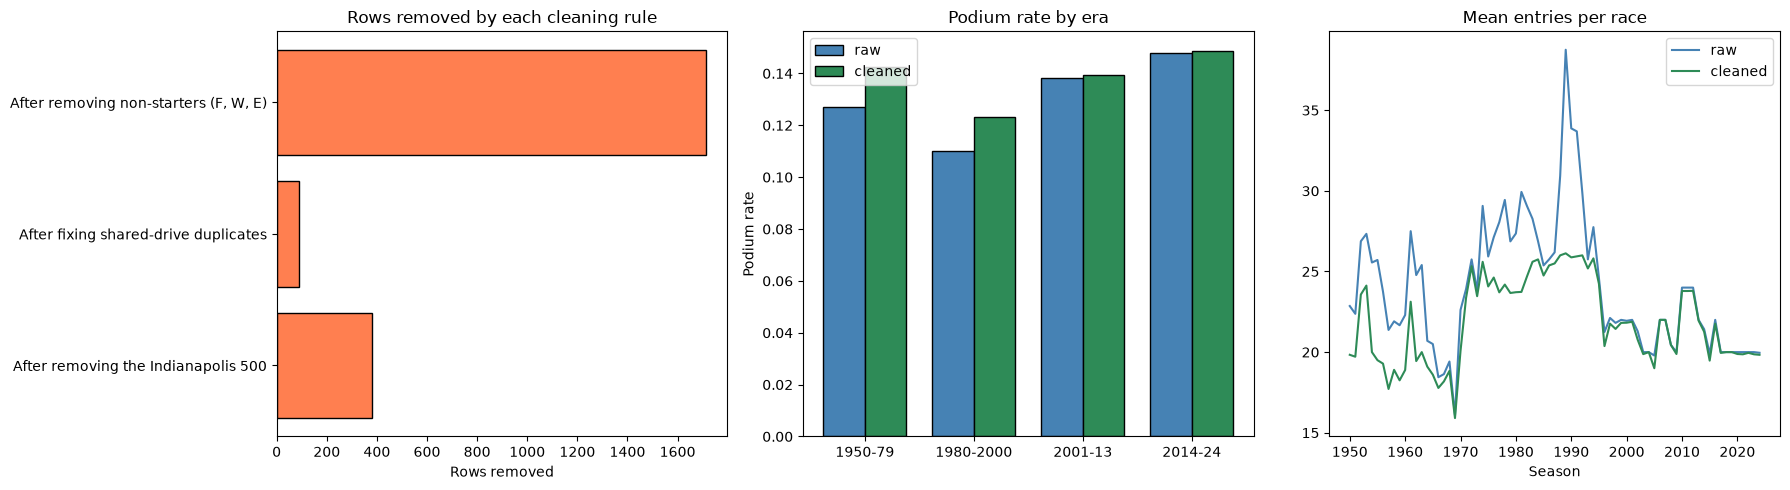

In [54]:
raw = results_df.merge(races_df[['year']], left_on='raceId', right_index=True)
raw['podium'] = (raw['positionOrder'] <= 3).astype(int)
clean = modeling.copy()

def summ(df, name):
    per_race = df.groupby('raceId').size()
    return {'dataset': name, 'rows': len(df), 'races': df['raceId'].nunique(),
            'duplicate (raceId, driverId) rows': int(df.duplicated(['raceId', 'driverId']).sum()),
            'podium rate': df['podium'].mean(),
            'mean entries per race': per_race.mean(),
            'share with grid = 0': (df['grid'] == 0).mean(),
            'rows with positionText F/W/E': int(df['positionText'].isin(MODEL_NON_STARTER_CODES).sum()) if 'positionText' in df else 0}

cmp_tbl = pd.DataFrame([summ(raw, 'raw results'), summ(clean, 'modeling (cleaned)')]).set_index('dataset').T
display(cmp_tbl)

bins   = [1949, 1979, 2000, 2013, 2024]
labels = ['1950-79', '1980-2000', '2001-13', '2014-24']
era_raw   = raw.groupby(pd.cut(raw['year'],   bins, labels=labels), observed=True)['podium'].mean()
era_clean = clean.groupby(pd.cut(clean['year'], bins, labels=labels), observed=True)['podium'].mean()
size_raw   = raw.groupby(['year', 'raceId']).size().groupby('year').mean()
size_clean = clean.groupby(['year', 'raceId']).size().groupby('year').mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) cleaning funnel (from the modeling-table step)
if 'funnel_df' in globals():
    f = funnel_df.iloc[1:]
    axes[0].barh(f['step'], f['removed'], color='coral', edgecolor='black')
    axes[0].set_title('Rows removed by each cleaning rule')
    axes[0].set_xlabel('Rows removed'); axes[0].invert_yaxis()

# 2) podium rate per era
x = np.arange(len(labels)); w = 0.38
axes[1].bar(x - w/2, era_raw.values,   w, label='raw',     color='steelblue', edgecolor='black')
axes[1].bar(x + w/2, era_clean.values, w, label='cleaned', color='seagreen', edgecolor='black')
axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_title('Podium rate by era'); axes[1].set_ylabel('Podium rate'); axes[1].legend()

# 3) field size per race over time
axes[2].plot(size_raw.index,   size_raw.values,   label='raw',     color='steelblue')
axes[2].plot(size_clean.index, size_clean.values, label='cleaned', color='seagreen')
axes[2].set_title('Mean entries per race'); axes[2].set_xlabel('Season'); axes[2].legend()
plt.tight_layout(); 
plt.show()

### What We Found

Cleaning reduced the table from **26,759 rows to 24,577** and the number of races from **1,125 to 1,114**. Duplicate `(raceId, driverId)` rows fell from **91 to 0**.

The overall podium rate rose from **12.7% to 13.7%**. This is because removing drivers who never started reduces the denominator, while the three podium places per race remain. The share of rows with `grid = 0` fell from **6.1% to 0.3%**, and rows with `positionText` **F/W/E** fell from **1,713 to 0**.

#### Changes by Era

The podium rate changed most in earlier eras:

| Era | Raw Podium Rate | Cleaned Podium Rate |
|---|---:|---:|
| 1950–1979 | ~12.7% | ~14.3% |
| 1980–2000 | ~11.0% | ~12.3% |
| 2001–2013 | ~13.8% | ~13.9% |
| 2014–2024 | ~14.8% | ~14.9% |

The earlier eras had many entries that never started, such as non-starters and drivers who failed to qualify. These entries increased the raw field size and lowered the raw podium rate. From 2001 onward, the raw and cleaned rates are nearly identical because fields were smaller and almost all entrants started.

The mean field size fell from **23.8 to 22.1 drivers per race**. The raw field size peaked at about **39 entries in 1989**, while the cleaned field peaked at about **26**.

#### Summary

Cleaning removed **1,713 non-starters**, **88 shared-drive duplicate rows**, and **381 Indianapolis 500 rows**. The final table has one row per `(raceId, driverId)` and includes only drivers who started, matching the goal of **one prediction per driver per race**.

In [55]:
# Re-run this cell after the Step 2 cell if you ever rebuild `modeling`
modeling['grid_is_zero'] = (modeling['grid'] == 0).astype(int)

last_slot = modeling.groupby('raceId')['grid'].transform('max')
modeling['grid_filled'] = modeling['grid'].where(modeling['grid'] > 0, last_slot + 1)

# ---- Checks ----
assert modeling['grid_filled'].min() >= 1, "grid_filled still contains 0"
assert (modeling.loc[modeling['grid_is_zero'] == 1, 'grid_filled']
        > modeling.groupby('raceId')['grid'].transform('max').loc[modeling['grid_is_zero'] == 1]).all(), \
       "A filled slot is not behind the last real slot"

print(f"Rows flagged grid_is_zero: {modeling['grid_is_zero'].sum()}")
print(modeling.loc[modeling['grid_is_zero'] == 1, ['raceId', 'driverId', 'year', 'grid', 'grid_filled', 'podium']].head(8))
print(f"\nFinal modeling table: {modeling.shape[0]:,} rows x {modeling.shape[1]} columns")

Rows flagged grid_is_zero: 80
          raceId  driverId  year  grid  grid_filled  podium
resultId                                                   
11659        486       136  1981     0           25       0
10252        436       181  1984     0           27       0
10547        447       185  1984     0           27       0
8213         364       161  1989     0           27       0
8326         367       131  1989     0           27       0
7038         321       112  1990     0           27       0
7213         326        90  1990     0           27       0
22645        931       832  2015     0           20       0

Final modeling table: 24,577 rows x 13 columns


In [56]:
modeling.to_csv('modeling_table.csv')   # resultId is saved as the first column
print('Saved modeling_table.csv with', modeling.shape[0], 'rows')

Saved modeling_table.csv with 24577 rows


In [57]:
modeling = pd.read_csv('modeling_table.csv', index_col=0, parse_dates=['date'])
modeling.info()
modeling.head()

<class 'pandas.core.frame.DataFrame'>
Index: 24577 entries, 20036 to 26759
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   raceId         24577 non-null  int64         
 1   driverId       24577 non-null  int64         
 2   constructorId  24577 non-null  int64         
 3   year           24577 non-null  int64         
 4   round          24577 non-null  int64         
 5   date           24577 non-null  datetime64[ns]
 6   circuitId      24577 non-null  int64         
 7   grid           24577 non-null  int64         
 8   positionOrder  24577 non-null  int64         
 9   points         24577 non-null  float64       
 10  podium         24577 non-null  int64         
 11  grid_is_zero   24577 non-null  int64         
 12  grid_filled    24577 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(11)
memory usage: 2.6 MB


,raceId,driverId,constructorId,year,round,date,circuitId,grid,positionOrder,points,podium,grid_is_zero,grid_filled
resultId,,,,,,,,,,,,,
20036,833,579,51,1950,1,1950-05-13,9,3,12,0.0,0,0,3
20042,833,589,105,1950,1,1950-05-13,9,11,18,0.0,0,0,11
20030,833,619,151,1950,1,1950-05-13,9,13,6,0.0,0,0,13
20029,833,627,154,1950,1,1950-05-13,9,9,5,2.0,0,0,9
20041,833,640,105,1950,1,1950-05-13,9,8,17,0.0,0,0,8


## Phase 2: Form features (leakage-safe)

### What we are building

Grid position tells the model where a driver starts, but not how well driver and team have been performing lately. We add **form** features: the driver's recent results, and later the constructor's. A driver in a fast car on a hot streak is more likely to podium than the grid slot alone suggests.

### The rule that keeps it valid: past races only

Our prediction is made **after qualifying and before the race**. So the form for a race may use only earlier races. If the current race leaks into its own feature, the model sees the answer and the results look better than they are (data leakage). We prevent it in two ways:

1. **Chronological order.** We sort by `year`, then `round`. We never sort by `raceId`, because it is not in time order (`raceId` 1 is the 2009 Australian GP).
2. **`shift(1)` before averaging.** This pushes each driver's history down one race, so the current race is excluded from its own average.

### Step 1: driver form

- `driver_podium_rate_5`: share of the driver's previous 5 races that ended on the podium (0 = none, 1 = all five).
- A driver's first ever race has no history, so the value is empty (`NaN`). We flag these with `is_first_race` and decide how to fill them later, using the **training set only**.
- We start from the shared `modeling` table (one row per driver per race) and do not modify it. The new columns go into a copy called `feat`.

### How we check it

We print one driver's first races and verify by eye that each value equals the average of the rows above it, **never his own row**.

In [58]:
# Phase 2, Step 1: driver form = podium rate over the PREVIOUS 5 races

# 1. Put the races in time order (by year, then round; NOT by raceId)
feat = modeling.sort_values(['year', 'round', 'raceId']).copy()

# 2. For each driver, take the last 5 races BEFORE the current one
#    shift(1) pushes everything down one row, so the current race is excluded
feat['driver_podium_rate_5'] = feat.groupby('driverId')['podium'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# 3. Look at one driver (Hamilton = driverId 1), first 8 races
feat[feat['driverId'] == 1][['year', 'round', 'podium', 'driver_podium_rate_5']].head(8)

,year,round,podium,driver_podium_rate_5
resultId,,,,
371,2007,1,1,NaN
392,2007,2,1,1.0
414,2007,3,1,1.0
436,2007,4,1,1.0
458,2007,5,1,1.0
479,2007,6,1,1.0
501,2007,7,1,1.0
525,2007,8,1,1.0


### What we found

For Lewis Hamilton's first 8 races (2007), the feature is `NaN` in round 1 and `1.0` afterwards.

- **Round 1 is empty** even though he finished on the podium that day. This shows the current race is not included in its own feature (no leakage).
- **From round 2 on**, the value is the podium rate of the previous races only (up to 5). He podiumed in all of them, so every value is `1.0`.

Debut rows are `NaN` by design. We will flag them with `is_first_race` and decide how to fill them later, using the **training set only**.

### Step 2: driver points average and debut flag

- `driver_points_avg_5`: average championship points the driver scored in his previous 5 races. Podium rate only says "top 3 or not"; points also reward finishing 4th-10th, so this captures **consistency**.
- `is_first_race_driver`: `1` for a driver's first ever race (no history), `0` otherwise. It tells the model that an empty form value means "new driver", not "bad form".
- `points` is a post-race value, so it is never used for the same race. Only points from earlier races are used (`shift(1)`), which is leakage-safe.

In [59]:
g = feat.groupby('driverId')

# Average points over the PREVIOUS 5 races (shift(1) excludes the current race)
feat['driver_points_avg_5'] = g['points'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Average points over the PREVIOUS 5 races (shift(1) excludes the current race)
feat['driver_points_avg_5'] = g['points'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# cumcount() numbers each driver's races 0, 1, 2, ... so 0 = first ever race
feat['is_first_race_driver'] = (g.cumcount() == 0).astype(int)

# Check: a driver with MIXED results, so we can see the window actually move
cols = ['year', 'round', 'podium', 'points',
        'driver_podium_rate_5', 'driver_points_avg_5', 'is_first_race_driver']
display(feat[feat['driverId'] == 4][cols].head(10))     # driverId 4 = Alonso

print("Debut rows:", feat['is_first_race_driver'].sum())
print("Missing driver_points_avg_5:", feat['driver_points_avg_5'].isna().sum())

,year,round,podium,points,driver_podium_rate_5,driver_points_avg_5,is_first_race_driver
resultId,,,,,,,
2568,2001,1,0,0.0,NaN,NaN,1
2591,2001,2,0,0.0,0.0,0.0,0
2619,2001,3,0,0.0,0.0,0.0,0
2644,2001,4,0,0.0,0.0,0.0,0
2657,2001,5,0,0.0,0.0,0.0,0
2681,2001,6,0,0.0,0.0,0.0,0
2701,2001,7,0,0.0,0.0,0.0,0
2729,2001,8,0,0.0,0.0,0.0,0
2746,2001,9,0,0.0,0.0,0.0,0


Debut rows: 682
Missing driver_points_avg_5: 682


**What we found**: `driver_points_avg_5` and `is_first_race_driver` were added. There are 682 debut rows and exactly 682 missing values, so every missing value is a driver's first race and nothing else is missing. Alonso's 2001 season shows the pattern: NaN and flag = 1 in round 1, then averages of earlier races only (all 0.0, since he scored no points that year). A driver with mixed results (Hamilton, 2009) shows the rolling window changing from race to race.

### Step 3: constructor (team) form


Car performance is the dominant factor in F1, so we also measure how well the team has done recently, not only the driver.

**The trap.** A team has two cars per race. If we shifted team rows directly, a driver's "previous row" would often be his teammate in the same race, which leaks the current result into the feature.

**The fix.**

1. Collapse to **one row per (constructor, race)**: the share of its cars on the podium and its total points.
2. Shift by one race and average the previous 5 races of that team.
3. Merge the value back, so both teammates get the same constructor form.

New columns: `constructor_podium_rate_5`, `constructor_points_avg_5`, `is_first_race_constructor`.

> **Limitation:** renamed teams get a new `constructorId`, so their history restarts. We note this in the report.

In [60]:
# Phase 2, Step 3: constructor form, leakage-safe

# 1. One row per (team, race): podium share and total points of its cars
team = (feat.groupby(['constructorId', 'raceId', 'year', 'round'], as_index=False)
            .agg(team_podium=('podium', 'mean'), team_points=('points', 'sum'))
            .sort_values(['year', 'round', 'raceId']))

# 2. Previous 5 RACES of that team (shift(1) excludes the current race)
tg = team.groupby('constructorId')
team['constructor_podium_rate_5'] = tg['team_podium'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team['constructor_points_avg_5'] = tg['team_points'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team['is_first_race_constructor'] = (tg.cumcount() == 0).astype(int)

# 3. Give the value back to every driver of that team in that race
cols = ['constructorId', 'raceId', 'constructor_podium_rate_5',
        'constructor_points_avg_5', 'is_first_race_constructor']
feat = (feat.reset_index()
            .merge(team[cols], on=['constructorId', 'raceId'], how='left')
            .set_index('resultId'))

# ── Checks ──
assert len(feat) == len(modeling), "row count changed"
same = feat.groupby(['constructorId', 'raceId'])['constructor_podium_rate_5'].nunique(dropna=False)
assert (same == 1).all(), "teammates got different team form"
print("Checks passed: same rows, and teammates share the same team form")

print("Team debut rows:", feat['is_first_race_constructor'].sum())
print("Missing constructor_podium_rate_5:", feat['constructor_podium_rate_5'].isna().sum())

# Look at one team: Ferrari is constructorId 6 (both cars shown per race)
show = ['year', 'round', 'driverId', 'podium', 'constructor_podium_rate_5',
        'constructor_points_avg_5', 'is_first_race_constructor']
display(feat[(feat['constructorId'] == 6) & (feat['year'] == 2010)][show].head(8))

Checks passed: same rows, and teammates share the same team form
Team debut rows: 262
Missing constructor_podium_rate_5: 262


,year,round,driverId,podium,constructor_podium_rate_5,constructor_points_avg_5,is_first_race_constructor
resultId,,,,,,,
20323,2010,1,4,1,0.1,2.8,0
20324,2010,1,13,1,0.1,2.8,0
20350,2010,2,4,0,0.2,10.2,0
20349,2010,2,13,1,0.2,10.2,0
20383,2010,3,4,0,0.3,15.6,0
20377,2010,3,13,0,0.3,15.6,0
20398,2010,4,4,0,0.3,15.8,0
20403,2010,4,13,0,0.3,15.8,0


### **Step 4: leakage test (brute-force recomputation)**
Our form features were built with shift and rolling. To prove they use only earlier races, we recompute them the slow, obvious way for 300 random rows: list every race strictly before the current one (earlier year, or same year and earlier round), keep the last 5, and average. If the slow result equals the feature for every sampled row, the features are correct and leakage-free. We test the driver podium rate, the driver points average and the constructor podium rate (the constructor feature is where leakage is most likely to hide, because of teammates in the same race).

In [61]:
# Phase 2, Step 4: brute-force check that features use only PAST races
rng = np.random.default_rng(0)
sample_pos = rng.choice(len(feat), 300, replace=False)

def earlier(df, year, rnd):
    """All rows strictly before (year, round)."""
    return df[(df['year'] < year) | ((df['year'] == year) & (df['round'] < rnd))]

# Team-level table: one row per (team, race), built from scratch here
team_rows = (feat.groupby(['constructorId', 'raceId', 'year', 'round'], as_index=False)
                 .agg(team_podium=('podium', 'mean')))

bad = 0
for i in sample_pos:
    row = feat.iloc[i]

    # Driver: his own earlier races, last 5
    d = earlier(feat[feat['driverId'] == row['driverId']], row['year'], row['round'])
    d = d.sort_values(['year', 'round']).tail(5)
    exp_pod = d['podium'].mean() if len(d) else np.nan
    exp_pts = d['points'].mean() if len(d) else np.nan

    # Constructor: the team's earlier RACES (one row per race), last 5
    t = earlier(team_rows[team_rows['constructorId'] == row['constructorId']], row['year'], row['round'])
    t = t.sort_values(['year', 'round']).tail(5)
    exp_con = t['team_podium'].mean() if len(t) else np.nan

    ok = (np.isclose(row['driver_podium_rate_5'],      exp_pod, equal_nan=True) and
          np.isclose(row['driver_points_avg_5'],       exp_pts, equal_nan=True) and
          np.isclose(row['constructor_podium_rate_5'], exp_con, equal_nan=True))
    if not ok:
        bad += 1
        print("Mismatch: raceId", row['raceId'], "driverId", row['driverId'])

print(f"Rows tested: {len(sample_pos)} | mismatches: {bad}")
assert bad == 0, "Leakage or logic error found"
print("PASSED: all features equal the average of earlier races only")

Rows tested: 300 | mismatches: 0
PASSED: all features equal the average of earlier races only


### What we found

We recomputed three features by brute force for **300 random rows** (all races strictly before the current one, last 5, averaged):

- driver podium rate
- driver points average
- constructor podium rate

There were **0 mismatches**, so the features use only earlier races and do not leak the current race, including the teammate case for the constructor features.

### Step 5: filling the empty form values

Debut rows (a driver's or a team's first race) have no history, so their form is `NaN`. Logistic regression and the neural network cannot accept missing values, so we fill them with `0` and keep the `is_first_race_*` flags. The flag tells the model the `0` means "no history", not "bad form".

- A constant fill uses no statistics from the data, so it **cannot leak** information from validation or test.
- We keep the unfilled columns too, so tree models can use the raw `NaN` if we decide to compare the two options in the preprocessing experiments.

In [62]:
# Phase 2, Step 5: fill debut NaNs with 0 (keep the flags)
FORM_RAW = ['driver_podium_rate_5', 'driver_points_avg_5',
            'constructor_podium_rate_5', 'constructor_points_avg_5']

for c in FORM_RAW:
    feat[c + '_filled'] = feat[c].fillna(0)          # raw column kept untouched

FORM_FEATURES = ([c + '_filled' for c in FORM_RAW] +
                 ['is_first_race_driver', 'is_first_race_constructor'])

assert feat[FORM_FEATURES].isna().sum().sum() == 0
print("No missing values left in:", FORM_FEATURES)
display(feat[FORM_FEATURES].describe().round(3))

No missing values left in: ['driver_podium_rate_5_filled', 'driver_points_avg_5_filled', 'constructor_podium_rate_5_filled', 'constructor_points_avg_5_filled', 'is_first_race_driver', 'is_first_race_constructor']


,driver_podium_rate_5_filled,driver_points_avg_5_filled,constructor_podium_rate_5_filled,constructor_points_avg_5_filled,is_first_race_driver,is_first_race_constructor
count,24577.000,24577.000,24577.000,24577.000,24577.000,24577.000
mean,0.135,2.130,0.138,4.575,0.028,0.011
std,0.236,3.669,0.205,6.957,0.164,0.103
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.200,0.000,0.000
50%,0.000,0.600,0.000,1.800,0.000,0.000
75%,0.200,2.600,0.200,5.800,0.000,0.000
max,1.000,28.600,1.000,44.400,1.000,1.000


### Step 6: evidence for the form features
The brief asks us to justify each feature with exploratory evidence. For each form feature we split the rows into 5 equally sized groups (lowest to highest form) and plot the actual podium rate of each group. If the bars rise from left to right, higher recent form goes with a higher chance of a podium, so the feature carries useful signal. This shows association only, not causation.

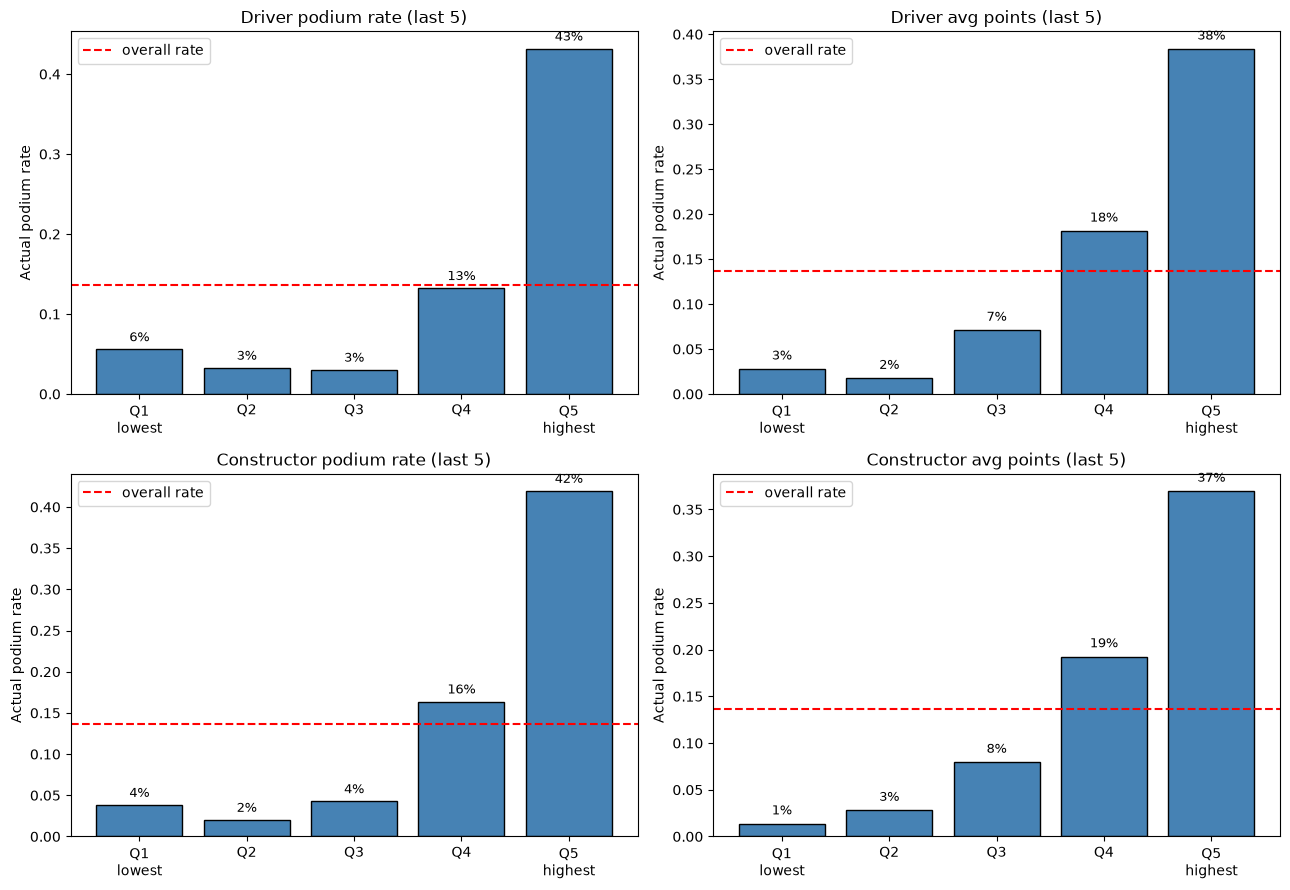

In [63]:
# Phase 2, Step 6: podium rate by form quintile
feats_to_plot = {
    'driver_podium_rate_5_filled':      'Driver podium rate (last 5)',
    'driver_points_avg_5_filled':       'Driver avg points (last 5)',
    'constructor_podium_rate_5_filled': 'Constructor podium rate (last 5)',
    'constructor_points_avg_5_filled':  'Constructor avg points (last 5)',
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.ravel(), feats_to_plot.items()):
    # rank first so ties (many zeros) can still be split into 5 groups
    q = pd.qcut(feat[col].rank(method='first'), 5,
                labels=['Q1\nlowest', 'Q2', 'Q3', 'Q4', 'Q5\nhighest'])
    rate = feat.groupby(q, observed=True)['podium'].mean()
    ax.bar(rate.index.astype(str), rate.values, color='steelblue', edgecolor='black')
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
    ax.axhline(feat['podium'].mean(), color='red', linestyle='--', label='overall rate')
    ax.set_title(title)
    ax.set_ylabel('Actual podium rate')
    ax.legend()
plt.tight_layout()
plt.show()

### Temuan

Keempat fitur form membawa sinyal yang jelas. Seperlima baris teratas berdasarkan form (Q5) finis di podium **37-43%** dari waktu, sekitar **tiga kali lipat** dari tingkat keseluruhan sebesar 13,7%, sedangkan seperlima terbawah hanya 1-6%. Pola ini berlaku untuk pembalap maupun konstruktor, baik untuk podium rate maupun rata-rata poin.

Hubungannya tidak mulus di bagian bawah: banyak baris punya nilai form tepat 0 (tidak ada podium atau poin belakangan ini), sehingga Q1-Q3 sebagian besar berisi nilai seri yang dibagi berdasarkan urutan baris dan hanya berbeda karena noise (2-6%). Dalam praktiknya, fitur-fitur ini memisahkan "form baru-baru ini kuat" dari "sisanya", yang berguna untuk model berbasis pohon (*tree models*).

Fitur konstruktor sama kuatnya dengan fitur pembalap, yang mendukung hipotesis kami bahwa performa mobil sama pentingnya dengan pembalapnya.

> **Catatan:** ini adalah asosiasi, bukan sebab-akibat. Form tim dan form pembalap juga saling berkorelasi, sehingga kontribusi nyata tiap kelompok fitur akan kami periksa dalam eksperimen ablasi.

### Step 7: packaging the form features as one function

Steps 1-5 are combined into `add_form_features(modeling)`, so my teammates can build the identical features with one call.

The function:

- does **not modify** the input table
- keeps the `resultId` index and the original row order
- returns the unfilled columns, the 0-filled columns (`*_filled`) and the debut flags

The function is followed by the same checks as before:

- row count
- teammates share the team form
- no missing values after the fill
- a brute-force leakage test on random rows

In [64]:
# PHASE 2: add_form_features(modeling) -> table with leakage-safe form columns
FORM_RAW = ['driver_podium_rate_5', 'driver_points_avg_5',
            'constructor_podium_rate_5', 'constructor_points_avg_5']
FORM_FEATURES = ([c + '_filled' for c in FORM_RAW] +
                 ['is_first_race_driver', 'is_first_race_constructor'])

def add_form_features(df, window=5):
    """Form of the previous `window` races only. Input table is not modified."""
    idx_name = df.index.name or 'index'
    out = df.sort_values(['year', 'round', 'raceId', 'driverId']).copy()

    # Driver form (one row per driver per race, so shift(1) is safe)
    g = out.groupby('driverId')
    out['driver_podium_rate_5'] = g['podium'].transform(
        lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    out['driver_points_avg_5'] = g['points'].transform(
        lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    out['is_first_race_driver'] = (g.cumcount() == 0).astype(int)

    # Constructor form: collapse to one row per (team, race) BEFORE shifting
    team = (out.groupby(['constructorId', 'raceId', 'year', 'round'], as_index=False)
               .agg(team_podium=('podium', 'mean'), team_points=('points', 'sum'))
               .sort_values(['year', 'round', 'raceId']))
    tg = team.groupby('constructorId')
    team['constructor_podium_rate_5'] = tg['team_podium'].transform(
        lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    team['constructor_points_avg_5'] = tg['team_points'].transform(
        lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    team['is_first_race_constructor'] = (tg.cumcount() == 0).astype(int)

    cols = ['constructorId', 'raceId', 'constructor_podium_rate_5',
            'constructor_points_avg_5', 'is_first_race_constructor']
    out = (out.reset_index().merge(team[cols], on=['constructorId', 'raceId'], how='left')
              .set_index(idx_name))

    # Constant fill (no statistics from the data, so it cannot leak); raw columns are kept
    for c in FORM_RAW:
        out[c + '_filled'] = out[c].fillna(0)

    return out.loc[df.index]          # same rows, same order as the input

features = add_form_features(modeling)

# ── Checks ──
assert len(features) == len(modeling) and features.index.equals(modeling.index)
assert not features.duplicated(['raceId', 'driverId']).any()
assert features[FORM_FEATURES].isna().sum().sum() == 0
assert (features.groupby(['constructorId', 'raceId'])['constructor_podium_rate_5']
        .nunique(dropna=False) == 1).all()

# Same numbers as the step-by-step version
assert np.allclose(features.loc[feat.index, FORM_FEATURES].values, feat[FORM_FEATURES].values)

# Brute-force leakage test on 300 random rows
rng = np.random.default_rng(1)
for i in rng.choice(len(features), 300, replace=False):
    r = features.iloc[i]
    past = features[(features['driverId'] == r['driverId']) &
                    ((features['year'] < r['year']) |
                     ((features['year'] == r['year']) & (features['round'] < r['round'])))]
    exp = past.sort_values(['year', 'round']).tail(5)['podium'].mean() if len(past) else np.nan
    assert np.isclose(r['driver_podium_rate_5'], exp, equal_nan=True)

print("All checks passed.", features.shape[0], "rows,", len(FORM_FEATURES), "form features")

All checks passed. 24577 rows, 6 form features


### Adding qualifying and standings features

The modeling table above has one validated row per driver per race, and the form features are already added (`features`). Two more groups of pre-race information are added on top of it: the **qualifying position** and the **championship standings before the race**.

#### Qualifying position

`grid` is where a driver starts after penalties. `quali_pos` is where they qualified, before penalties. The gap between the two (`quali_grid_gap = grid_filled − quali_pos`) captures whether a driver was penalised:

- `quali_grid_gap = 0` → no penalty
- `quali_grid_gap > 0` → the driver dropped back (for example an engine penalty)
- `quali_grid_gap < 0` → the driver moved forward (another driver ahead was penalised)

> **Coverage caveat.** From our EDA (Plot 4), qualifying data is complete from 2003 onward and unreliable before. For races without qualifying data we use the grid slot as a proxy for `quali_pos`, which sets `quali_grid_gap = 0`. This loses the penalty signal for older races but avoids systematic missingness. The flag `has_quali` tells the model which rows have real qualifying data.

We use `grid_filled` (not `grid`) so that pit-lane starts (`grid = 0`) do not create a fake large gap.

In [65]:
idx_name = features.index.name or 'index'
model_table = features.reset_index()
n_rows = len(model_table)

quali_pos = (qualifying[['raceId', 'driverId', 'position']]
             .rename(columns={'position': 'quali_pos'}))
assert not quali_pos.duplicated(['raceId', 'driverId']).any(), "qualifying is not unique per (raceId, driverId)"

model_table = model_table.merge(quali_pos, on=['raceId', 'driverId'], how='left')
assert len(model_table) == n_rows, "the qualifying merge changed the number of rows"

# Flag rows with real qualifying data, then fall back to the grid slot
model_table['has_quali'] = model_table['quali_pos'].notna().astype(int)
model_table['quali_pos'] = model_table['quali_pos'].fillna(model_table['grid_filled'])

# Gap between starting slot and qualifying position captures grid penalties
model_table['quali_grid_gap'] = model_table['grid_filled'] - model_table['quali_pos']

assert model_table['quali_pos'].notna().all()
print(f"Missing quali_pos after fallback: {model_table['quali_pos'].isna().sum()}")
print(f"Rows with real qualifying data: {model_table['has_quali'].mean():.1%}")
print("\nquali_grid_gap statistics:")
print(model_table['quali_grid_gap'].describe().round(2))

Missing quali_pos after fallback: 0
Rows with real qualifying data: 42.4%

quali_grid_gap statistics:
count    24577.0
mean         0.0
std          1.0
min         -9.0
25%          0.0
50%          0.0
75%          0.0
max         23.0
Name: quali_grid_gap, dtype: float64


#### Leakage-safe championship standings

Championship standings are updated after each race, so the standings for race R contain race R's own points. Using the current-race standings as a feature would **leak the target directly** into the model.

**Fix:** we shift every standings row forward by one round before merging. A standings row originally tagged `(year=2018, round=3)` is relabelled `round=4`, so when we merge on `(year, round)` it lands on round 4, the next race. This means every race sees the standings as they stood **before** it started.

We add four features:

| Feature | Description |
|---|---|
| `drv_pts_prev` | Driver's championship points entering this race |
| `drv_standing_prev` | Driver's championship position entering this race |
| `con_pts_prev` | Constructor's championship points entering this race |
| `con_standing_prev` | Constructor's championship position entering this race |

**Round 1.** The first race of each season has no previous standings. These rows get filled with `0` (zero points, no position), which is the correct pre-season state.

In [66]:
race_rounds = races.reset_index()[['raceId', 'year', 'round']]

drv_std = (driver_standings.reset_index()[['raceId', 'driverId', 'points', 'position']]
           .merge(race_rounds, on='raceId', how='left')
           [['driverId', 'year', 'round', 'points', 'position']]
           .rename(columns={'points': 'drv_pts_prev', 'position': 'drv_standing_prev'}))
drv_std['round'] += 1  # shift: "after round N" becomes the feature for round N+1

con_std = (constructor_standings.reset_index()[['raceId', 'constructorId', 'points', 'position']]
           .merge(race_rounds, on='raceId', how='left')
           [['constructorId', 'year', 'round', 'points', 'position']]
           .rename(columns={'points': 'con_pts_prev', 'position': 'con_standing_prev'}))
con_std['round'] += 1

assert not drv_std.duplicated(['driverId', 'year', 'round']).any()
assert not con_std.duplicated(['constructorId', 'year', 'round']).any()

n_rows = len(model_table)
model_table = model_table.merge(drv_std, on=['driverId', 'year', 'round'], how='left')
model_table = model_table.merge(con_std, on=['constructorId', 'year', 'round'], how='left')
assert len(model_table) == n_rows, "the standings merge changed the number of rows"

# Round 1 of each season (or no standings entry yet): no previous standings -> fill 0
for c in ['drv_pts_prev', 'drv_standing_prev', 'con_pts_prev', 'con_standing_prev']:
    model_table[c] = model_table[c].fillna(0)

# Sanity check: 2018 round 2 should show points scored in round 1 only
check = (model_table[(model_table['year'] == 2018) & (model_table['round'] == 2)]
         .nlargest(5, 'drv_pts_prev')
         [['driverId', 'drv_pts_prev', 'drv_standing_prev', 'con_pts_prev', 'con_standing_prev']])
print("2018 Bahrain GP (round 2): standings entering the race")
print(check.to_string(index=False))

model_table = model_table.set_index(idx_name)

2018 Bahrain GP (round 2): standings entering the race
 driverId  drv_pts_prev  drv_standing_prev  con_pts_prev  con_standing_prev
       20          25.0                1.0          40.0                1.0
        1          18.0                2.0          22.0                2.0
        8          15.0                3.0          40.0                1.0
      817          12.0                4.0          20.0                3.0
        4          10.0                5.0          12.0                4.0


#### What we found

The standings shift works correctly. The 2018 Bahrain Grand Prix (round 2) sanity check shows:

| Driver | Points entering round 2 | Position |
|---|---|---|
| Hamilton (20) | 25 | P1 |
| Vettel (1) | 18 | P2 |
| Räikkönen (8) | 15 | P3 |

These are exactly the points awarded at the 2018 Australian Grand Prix (round 1): Hamilton won (25 pts), Vettel second (18 pts), Räikkönen third (15 pts). The shift is landing on the correct race. ✓

`drv_standing_prev` can exceed 100, which looks large but is correct: early F1 had fields of 30+ drivers who sometimes appeared only once, placing them far down the standings.

> **Limitation:** the `0` values for round-1 rows reflect the pre-season state, but `0` is numerically better than P1. Models that treat the value as a number should be read with care.

### Feature inventory

Every feature of the final modeling table is listed below with its group. The groups are the units for the feature-group ablation later.

| Group | Features | Why it is valid at the pre-race cutoff |
|---|---|---|
| **Grid** | `grid_filled`, `grid_is_zero` | the starting slot is fixed before the race; `grid = 0` pit-lane starts are handled explicitly |
| **Qualifying** | `quali_pos`, `quali_grid_gap`, `has_quali` | qualifying is finished before the race; pre-2003 rows fall back to the grid slot |
| **Driver form** | `driver_podium_rate_5_filled`, `driver_points_avg_5_filled`, `is_first_race_driver` | built from the previous 5 races only (`shift(1)`), verified by a brute-force test |
| **Constructor form** | `constructor_podium_rate_5_filled`, `constructor_points_avg_5_filled`, `is_first_race_constructor` | one row per (team, race) before shifting, so a teammate in the same race can never leak in |
| **Standings** | `drv_pts_prev`, `drv_standing_prev`, `con_pts_prev`, `con_standing_prev` | standings shifted by one round, so they never include the current race |

Three more features, `driver_te`, `constructor_te` and `circuit_te`, are added by the target-encoding step **after the split**.

> **Not features:** `positionOrder`, `points` and `podium` stay in the table only to build the target and the past-race features. They describe the race outcome and must **never** be used as inputs for the same race.

In [67]:
# ── Feature inventory and leakage guard ──────────────────────────────────────
FEATURE_GROUPS = {
    'grid':             ['grid_filled', 'grid_is_zero'],
    'qualifying':       ['quali_pos', 'quali_grid_gap', 'has_quali'],
    'driver_form':      ['driver_podium_rate_5_filled', 'driver_points_avg_5_filled', 'is_first_race_driver'],
    'constructor_form': ['constructor_podium_rate_5_filled', 'constructor_points_avg_5_filled', 'is_first_race_constructor'],
    'standings':        ['drv_pts_prev', 'drv_standing_prev', 'con_pts_prev', 'con_standing_prev'],
}
FEATURE_COLS = [c for cols in FEATURE_GROUPS.values() for c in cols]

# Columns that describe the race outcome must never be features
POST_RACE_COLS = ['positionOrder', 'points', 'podium']
assert not set(FEATURE_COLS) & set(POST_RACE_COLS), "a post-race column is in the feature list"
assert set(FEATURE_COLS) <= set(model_table.columns), "a feature column is missing"
assert model_table[FEATURE_COLS].isna().sum().sum() == 0, "missing values in the features"
assert not model_table.duplicated(['raceId', 'driverId']).any(), "grain broken"

print(f"Modeling table: {model_table.shape[0]:,} rows x {model_table.shape[1]} columns")
print(f"Target (podium) rate: {model_table['podium'].mean():.1%}")
print(f"Features: {len(FEATURE_COLS)} in {len(FEATURE_GROUPS)} groups (+3 target-encoded after the split)")
display(model_table[FEATURE_COLS].describe().round(3).T)

Modeling table: 24,577 rows x 30 columns
Target (podium) rate: 13.7%
Features: 15 in 5 groups (+3 target-encoded after the split)


,count,mean,std,min,25%,50%,75%,max
grid_filled,24577.0,11.797,6.744,1.0,6.0,12.0,17.0,34.0
grid_is_zero,24577.0,0.003,0.057,0.0,0.0,0.0,0.0,1.0
quali_pos,24577.0,11.794,6.743,1.0,6.0,12.0,17.0,34.0
quali_grid_gap,24577.0,0.002,0.999,-9.0,0.0,0.0,0.0,23.0
has_quali,24577.0,0.424,0.494,0.0,0.0,0.0,1.0,1.0
driver_podium_rate_5_filled,24577.0,0.135,0.236,0.0,0.0,0.0,0.2,1.0
driver_points_avg_5_filled,24577.0,2.130,3.669,0.0,0.0,0.6,2.6,28.6
is_first_race_driver,24577.0,0.028,0.164,0.0,0.0,0.0,0.0,1.0
constructor_podium_rate_5_filled,24577.0,0.138,0.205,0.0,0.0,0.0,0.2,1.0
constructor_points_avg_5_filled,24577.0,4.575,6.957,0.0,0.2,1.8,5.8,44.4


### Train / validation / test split

**Why a time-ordered split.** The model predicts future races from past ones, so the data must be split by time. A random split would train on later seasons and test on earlier ones, which leaks information about the future into the model.

**Split:**

| Set | Seasons | Use |
|---|---|---|
| Train | up to 2019 | fit the models |
| Validation | 2020-2021 | choose hyperparameters and thresholds |
| Test | 2022-2024 | used **once**, at the very end |

> **Limitation:** 2020 was a COVID-shortened season (17 races), so part of the validation set is atypical.

,rows,races,first_year,last_year,podium_rate
train,22450,1007,1950,2019,13.5%
validation,775,39,2020,2021,15.1%
test,1352,68,2022,2024,15.1%


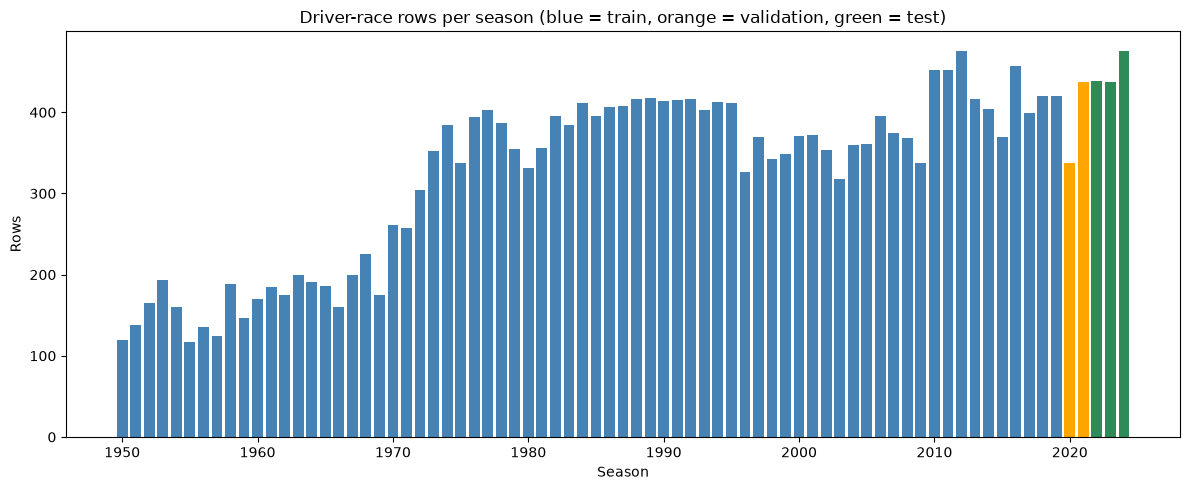

In [68]:
# ── Time-ordered split ────────────────────────────────────────────────────────
# The final modeling table built above (grid + qualifying + form + standings features):
model_df = model_table.copy()

REQUIRED = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'podium']
missing = [c for c in REQUIRED if c not in model_df.columns]
assert not missing, f"Modeling table is missing columns: {missing}"

# Sort so "past" and "future" are well defined
model_df = model_df.sort_values(['year', 'round', 'raceId']).reset_index(drop=True)

train_df = model_df[model_df['year'] <= 2019].copy()
val_df   = model_df[model_df['year'].between(2020, 2021)].copy()
test_df  = model_df[model_df['year'] >= 2022].copy()

# ── Checks ───────────────────────────────────────────────────────────────────
assert len(train_df) + len(val_df) + len(test_df) == len(model_df), "Rows lost or duplicated"
assert train_df['year'].max() < val_df['year'].min() < test_df['year'].min(), "Splits overlap in time"
assert set(train_df['raceId']).isdisjoint(val_df['raceId']) and \
       set(val_df['raceId']).isdisjoint(test_df['raceId']), "A race appears in two splits"

summary = pd.DataFrame({
    'rows':        [len(train_df), len(val_df), len(test_df)],
    'races':       [d['raceId'].nunique() for d in (train_df, val_df, test_df)],
    'first_year':  [d['year'].min() for d in (train_df, val_df, test_df)],
    'last_year':   [d['year'].max() for d in (train_df, val_df, test_df)],
    'podium_rate': [d['podium'].mean() for d in (train_df, val_df, test_df)],
}, index=['train', 'validation', 'test'])
display(summary.style.format({'podium_rate': '{:.1%}'}))

# ── Plot: rows per season, coloured by split ──────────────────────────────────
rows_per_year = model_df.groupby('year').size()
colors = ['steelblue' if y <= 2019 else 'orange' if y <= 2021 else 'seagreen'
          for y in rows_per_year.index]
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(rows_per_year.index, rows_per_year.values, color=colors, edgecolor='none')
ax.set_title('Driver-race rows per season (blue = train, orange = validation, green = test)')
ax.set_xlabel('Season'); ax.set_ylabel('Rows')
plt.tight_layout(); plt.show()

### What we learn

The split is strictly time-ordered with no overlap (asserted):

| Set | Seasons | Rows |
|---|---|---|
| Train | 1950-2019 | 22,450 |
| Validation | 2020-2021 | 775 |
| Test | 2022-2024 | 1,352 |

- **Small validation set.** With about 117 podiums, model comparisons on validation are noisy, so we only trust clear differences.
- **Distribution shift.** The podium rate is 13.5% in train but 15.1% in validation and test, because modern fields have exactly 20 cars while historical fields varied. This is why we report **PR-AUC and F1** rather than accuracy.
- **Old eras dominate training.** Most training rows come from before 2003, where qualifying data is missing. Whether to restrict the training window to modern seasons is a modeling decision we will test as an experiment.
- **2020 is shortened** (17 races), so part of validation is atypical.

In [69]:
M = 20   # smoothing strength; a hyperparameter, to be tuned on validation only

def race_prior(train):
    """Overall podium rate using only races BEFORE each race."""
    r = (train.groupby('raceId')
              .agg(s=('podium', 'sum'), n=('podium', 'count'),
                   year=('year', 'first'), round=('round', 'first'))
              .sort_values(['year', 'round']))
    past_s, past_n = r['s'].cumsum() - r['s'], r['n'].cumsum() - r['n']
    # first race of the dataset has no past: fall back to the training mean
    return (past_s / past_n.replace(0, np.nan)).fillna(train['podium'].mean())

def encode_train(train, col, m=M):
    """Training rows: smoothed podium rate of this category in strictly earlier races."""
    prior = race_prior(train)
    g = (train.groupby([col, 'raceId'])['podium'].agg(s='sum', n='count').reset_index()
              .merge(train[['raceId', 'year', 'round']].drop_duplicates(), on='raceId')
              .sort_values([col, 'year', 'round']))
    g['past_s'] = g.groupby(col)['s'].cumsum() - g['s']     # excludes the current race
    g['past_n'] = g.groupby(col)['n'].cumsum() - g['n']
    g['prior']  = g['raceId'].map(prior)
    g['enc']    = (g['past_s'] + m * g['prior']) / (g['past_n'] + m)
    out = train[[col, 'raceId']].merge(g[[col, 'raceId', 'enc']], on=[col, 'raceId'], how='left')
    out.index = train.index
    return out['enc']

def encode_other(train, other, col, m=M):
    """Validation/test rows: statistics from ALL training rows; unseen category -> overall rate."""
    prior = train['podium'].mean()
    stats = train.groupby(col)['podium'].agg(s='sum', n='count')
    s = other[col].map(stats['s']).fillna(0)
    n = other[col].map(stats['n']).fillna(0)
    return (s + m * prior) / (n + m)

ENCODE = {'driverId': 'driver_te', 'constructorId': 'constructor_te', 'circuitId': 'circuit_te'}
for col, name in ENCODE.items():
    train_df[name] = encode_train(train_df, col)
    val_df[name]   = encode_other(train_df, val_df, col)
    test_df[name]  = encode_other(train_df, test_df, col)

# ── Checks and evidence ───────────────────────────────────────────────────────
from sklearn.metrics import roc_auc_score
names = list(ENCODE.values())
assert train_df[names].notna().all().all() and val_df[names].notna().all().all() \
       and test_df[names].notna().all().all(), "NaN in encoded columns"

print("Share of rows whose category never appears in training:")
for col in ENCODE:
    print(f"  {col:14s} val {1 - val_df[col].isin(train_df[col]).mean():.1%} | "
          f"test {1 - test_df[col].isin(train_df[col]).mean():.1%}")

ev = pd.DataFrame({'feature': names,
                   'train_AUC': [roc_auc_score(train_df['podium'], train_df[n]) for n in names],
                   'val_AUC':   [roc_auc_score(val_df['podium'],   val_df[n])   for n in names]})
display(ev.round(3))

Share of rows whose category never appears in training:
  driverId       val 13.7% | test 21.9%
  constructorId  val 15.6% | test 20.0%
  circuitId      val 12.9% | test 14.6%


,feature,train_AUC,val_AUC
0,driver_te,0.785,0.739
1,constructor_te,0.789,0.842
2,circuit_te,0.520,0.501


### What we learn (target encoding)

Each driver, constructor and circuit is replaced by its **smoothed podium rate from strictly earlier races** (smoothing M = 20), so no row sees its own result. Validation and test rows use the final training statistics, and unseen categories fall back to the overall podium rate.

- **Constructor is the strongest encoded feature** (AUC 0.79 train, 0.84 validation), consistent with car performance being the dominant factor in F1.
- **Driver is useful but weaker on validation** (0.79 → 0.74), partly because 13.7% of validation rows are drivers never seen in training.
- **Circuit alone is uninformative** (AUC ≈ 0.50): every race has exactly three podium places, so circuits have similar podium rates. We keep it as a candidate and test it in the ablation experiment.
- **Unseen categories** are mostly renamed teams (AlphaTauri, Alpine, RB) and new drivers, which is the identity drift the brief warns about. Test has the most (20.0% constructors, 21.9% drivers).

,A_correct_train,A_correct_val,B_self_leak_train,C_before_split_val
feature,,,,
driver_te,0.785,0.739,0.829,0.835
constructor_te,0.789,0.842,0.800,0.879
circuit_te,0.520,0.501,0.524,0.500


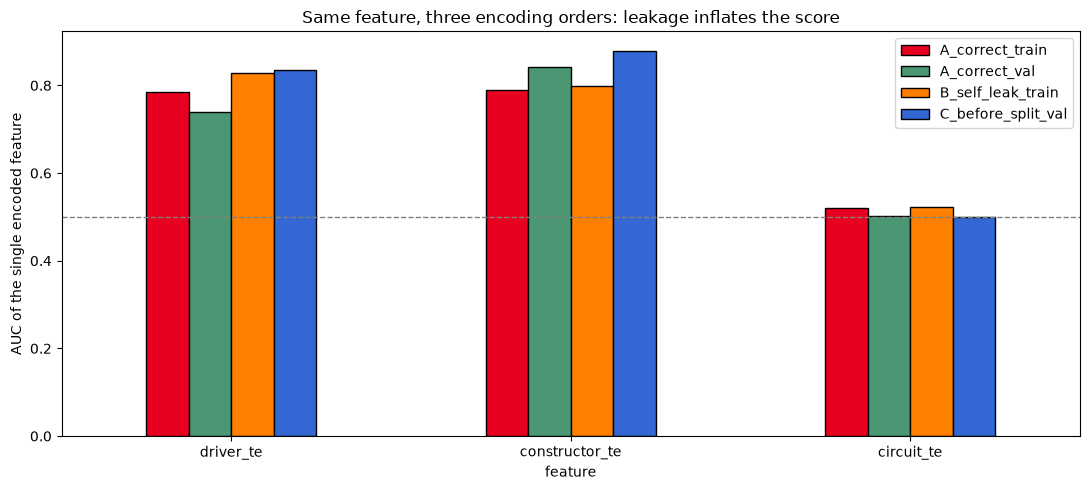

In [70]:
# ── Experiment: does the order of "encode" and "split" matter? ───────────────
def encode_static(stats_source, target, col, m=M):
    prior = stats_source['podium'].mean()
    st = stats_source.groupby(col)['podium'].agg(s='sum', n='count')
    s = target[col].map(st['s']).fillna(0)
    n = target[col].map(st['n']).fillna(0)
    return (s + m * prior) / (n + m)

rows = []
for col, name in ENCODE.items():
    rows.append({
        'feature': name,
        # A) correct: expanding past-only encoding for train, train stats for val
        'A_correct_train':      roc_auc_score(train_df['podium'], train_df[name]),
        'A_correct_val':        roc_auc_score(val_df['podium'],   val_df[name]),
        # B) wrong: one static table from all train rows, applied to those same rows
        'B_self_leak_train':    roc_auc_score(train_df['podium'], encode_static(train_df, train_df, col)),
        # C) wrong: statistics fitted on ALL data (train+val+test) BEFORE splitting
        'C_before_split_val':   roc_auc_score(val_df['podium'],   encode_static(model_df, val_df, col)),
    })
exp = pd.DataFrame(rows).set_index('feature')
display(exp.round(3))

ax = exp.plot.bar(figsize=(11, 5), edgecolor='black', color=['#E80020', '#4B9774', '#FF8000', '#3267D4'])
ax.set_ylabel('AUC of the single encoded feature')
ax.set_title('Same feature, three encoding orders: leakage inflates the score')
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
plt.xticks(rotation=0); 
plt.tight_layout(); 
plt.show()

### Preprocessing-order experiment: encoding before vs after splitting

We compared three ways to build the same encoded features and measured how well each single feature separates podium finishers (AUC):

- **A (our method):** training rows use only earlier races, validation uses training statistics.
- **B (wrong):** one table from all training rows applied to those same rows, so each row's own result is inside its feature.
- **C (wrong):** statistics fitted on the whole dataset before splitting, so validation and test results leak in.

#### What we learn

Wrong orders **inflate the scores**:

| Feature | Split | A (ours) | Wrong order | Inflation |
|---|---|---|---|---|
| `driver_te` | Train | 0.785 | 0.829 (B) | +0.044 |
| `driver_te` | Validation | 0.739 | 0.835 (C) | +0.096 |
| `constructor_te` | Validation | 0.842 | 0.879 (C) | +0.037 |

- For `constructor_te` the inflation is smaller because each team has many rows.
- `circuit_te` is unaffected (AUC ≈ 0.50) because it carries almost no signal.

Wrongly ordered preprocessing would make the model look better than it is on new races, so we **keep method A**. This is one of our preprocessing-order experiments.

driver_te               constructor_te               circuit_te  \
                 min   mean    max            min   mean    max        min   
test           0.014  0.148  0.569          0.015  0.206  0.470      0.122   
train          0.014  0.146  0.606          0.004  0.153  0.472      0.112   
validation     0.014  0.167  0.569          0.015  0.207  0.470      0.122   

                          
             mean    max  
test        0.137  0.149  
train       0.139  0.209  
validation  0.136  0.149

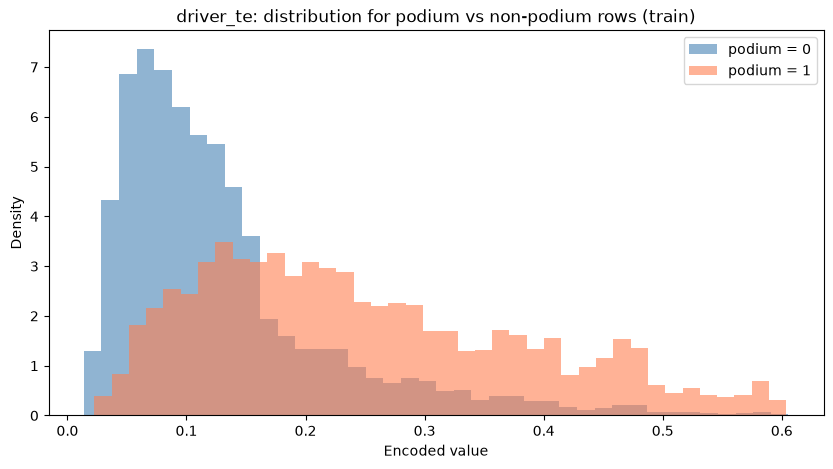

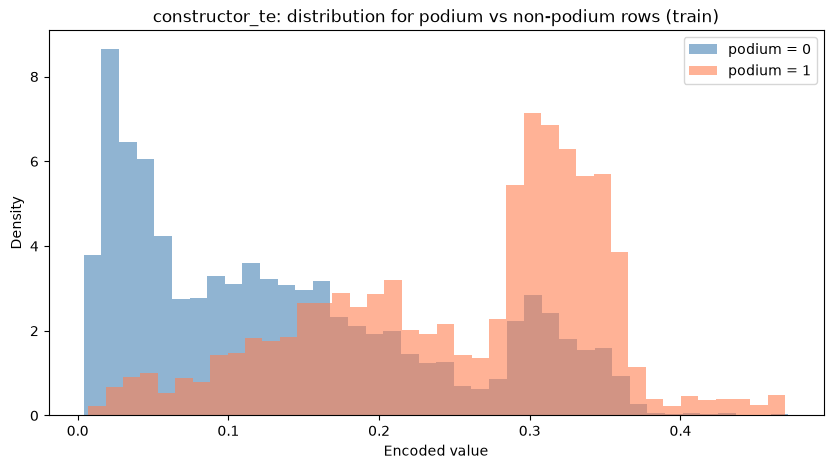

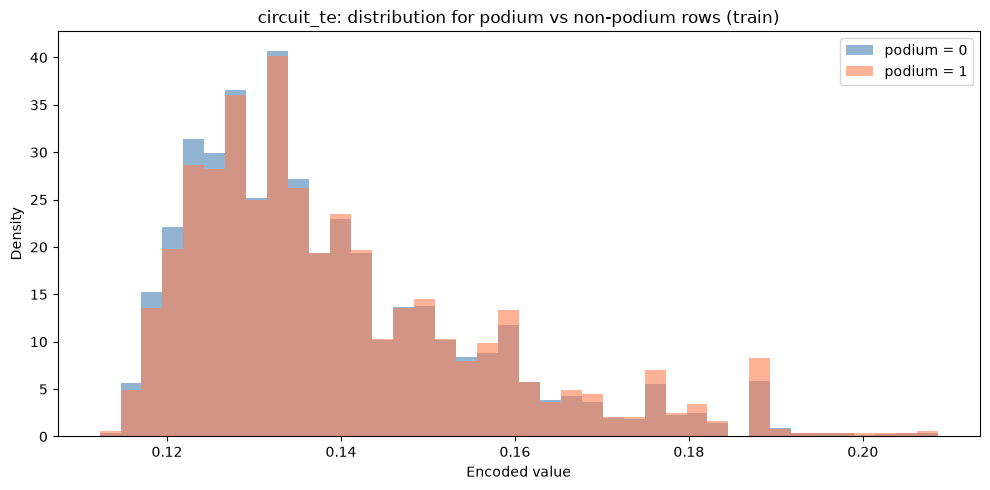

In [72]:
display(pd.concat({'train': train_df[names], 'validation': val_df[names], 'test': test_df[names]})
        .groupby(level=0)[names].agg(['min', 'mean', 'max']).round(3))

for n in names:
    fig, ax = plt.subplots(figsize=(10, 5))
    for label, color in [(0, 'steelblue'), (1, 'coral')]:
        ax.hist(train_df.loc[train_df['podium'] == label, n], bins=40, alpha=0.6,
               density=True, color=color, label=f'podium = {label}')
        ax.set_title(f'{n}: distribution for podium vs non-podium rows (train)')
        ax.set_xlabel('Encoded value'); ax.set_ylabel('Density'); ax.legend()
plt.tight_layout()
plt.show()

### What the distributions show

We plot each encoded feature for podium (orange) and non-podium (blue) rows in the training set. Heights are densities, so the shapes can be compared even though podium rows are only about 13% of the data.

- **`constructor_te` separates the classes best.** Non-podium rows peak at 0.02-0.05 (weak teams), while podium rows have a strong peak at 0.28-0.36 (dominant teams). Non-podium rows still appear at high values, because even a top team has only two cars and some retire.
- **`driver_te` separates partially.** Podium rows have a long tail up to 0.6, and values above 0.3 are almost all podiums, but the classes overlap between 0.1 and 0.2.
- **`circuit_te` does not separate the classes.** The two distributions overlap almost completely (AUC ≈ 0.50), so a circuit's past podium rate says almost nothing about whether a given driver reaches the podium there. We keep it only as a candidate for the ablation experiment.

> **Note:** these plots are evidence of **association, not causation**: a high constructor value reflects car strength that is also visible in other features.

In [73]:
print(train_df[train_df['year'] >= 2010][names].mean().round(3))
print(val_df[names].mean().round(3))
print(train_df[train_df['year'] >= 2017][names].mean().round(3))

driver_te         0.152
constructor_te    0.168
circuit_te        0.136
dtype: float64
driver_te         0.167
constructor_te    0.207
circuit_te        0.136
dtype: float64
driver_te         0.153
constructor_te    0.186
circuit_te        0.136
dtype: float64


### Range and shift of the encoded values

All encoded values lie in [0, 1] with no missing values. Smoothing keeps them away from the extremes: no driver exceeds 0.61 and no constructor exceeds 0.47. `circuit_te` hardly varies (0.12-0.15 in validation and test), which matches its AUC of about 0.50, so it adds little on its own and will be tested in the ablation.

`constructor_te` has a higher mean in validation and test (0.21) than in train (0.15). The gap shrinks as the training rows get more recent:

| Training window | Mean `constructor_te` |
|---|---|
| All training rows | 0.15 |
| 2010-2019 | 0.17 |
| 2017-2019 | 0.19 |
| Validation and test | 0.21 |

Later rows have both longer encoding histories and modern grids with fewer weak teams, so this shows the shift is mainly a time effect, and we did not separate the two causes.

> **Limitation:** this shift comes from encoding with past data only.

In [74]:
rows = []
for m in [1, 5, 20, 50, 100, 200]:
    for col, name in ENCODE.items():
        tr = encode_train(train_df, col, m=m)
        va = encode_other(train_df, val_df, col, m=m)
        rows.append({'M': m, 'feature': name,
                     'train_AUC': roc_auc_score(train_df['podium'], tr),
                     'val_AUC':   roc_auc_score(val_df['podium'],   va)})
sweep = pd.DataFrame(rows).pivot(index='M', columns='feature', values=['train_AUC', 'val_AUC'])
display(sweep.round(3))

train_AUC                             val_AUC                 \
feature circuit_te constructor_te driver_te circuit_te constructor_te   
M                                                                       
1            0.521          0.793     0.805      0.501          0.842   
5            0.521          0.792     0.798      0.501          0.842   
20           0.520          0.789     0.785      0.501          0.842   
50           0.519          0.786     0.776      0.501          0.843   
100          0.517          0.784     0.768      0.501          0.843   
200          0.515          0.780     0.758      0.501          0.815   

                   
feature driver_te  
M                  
1           0.757  
5           0.755  
20          0.739  
50          0.735  
100         0.736  
200         0.736

### Choosing the smoothing strength M

M acts as a number of pretend starts at the overall podium rate. We tried M from 1 to 200 and measured each encoded feature's AUC on its own.

#### What we learn

| Feature | Effect of M | Validation AUC |
|---|---|---|
| `constructor_te` | insensitive | 0.842-0.843 from M = 1 to 100 |
| `circuit_te` | no change | 0.501 |
| `driver_te` | slightly better with less smoothing | 0.757 at M = 1 vs 0.739 at M = 20 |

- With only about 117 podiums in validation, the `driver_te` gap is **within noise**.
- Very small M gives extreme values to drivers with one or two starts.

We **keep M = 20** and will revisit it in the modeling section using each model's validation PR-AUC.

### Evidence for the qualifying and standings features, and feature correlation

Form and grid features already have plots. Here we add the same kind of evidence for the other groups:

- **Qualifying:** podium rate by `quali_pos` next to `grid_filled`, and by `quali_grid_gap` (does a grid penalty change the podium chance?).
- **Standings:** podium rate by championship position before the race (driver and constructor).
- **Single-feature AUC** for every feature (how well it separates podium rows on its own, training set only).
- **Correlation matrix** to find near-duplicate features (for example `grid_filled` and `quali_pos`), which matters when reading SHAP and permutation importance.

,feature,group,AUC,strength |AUC - 0.5|
0,quali_pos,qualifying,0.116,0.384
1,grid_filled,grid,0.117,0.383
2,constructor_podium_rate_5_filled,constructor_form,0.828,0.328
3,driver_points_avg_5_filled,driver_form,0.818,0.318
4,constructor_points_avg_5_filled,constructor_form,0.814,0.314
5,driver_podium_rate_5_filled,driver_form,0.813,0.313
6,constructor_te,target_encoded,0.789,0.289
7,driver_te,target_encoded,0.785,0.285
8,drv_pts_prev,standings,0.757,0.257
9,con_standing_prev,standings,0.247,0.253


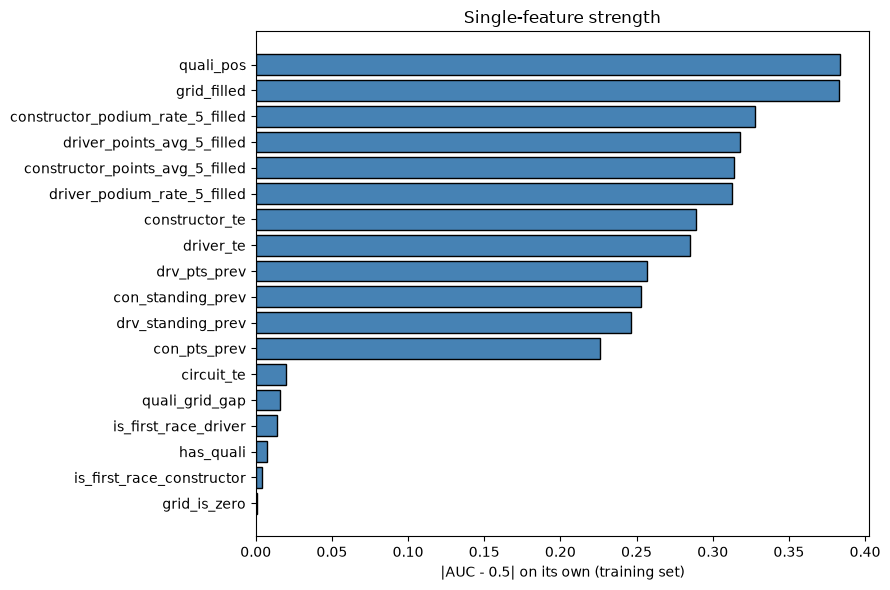

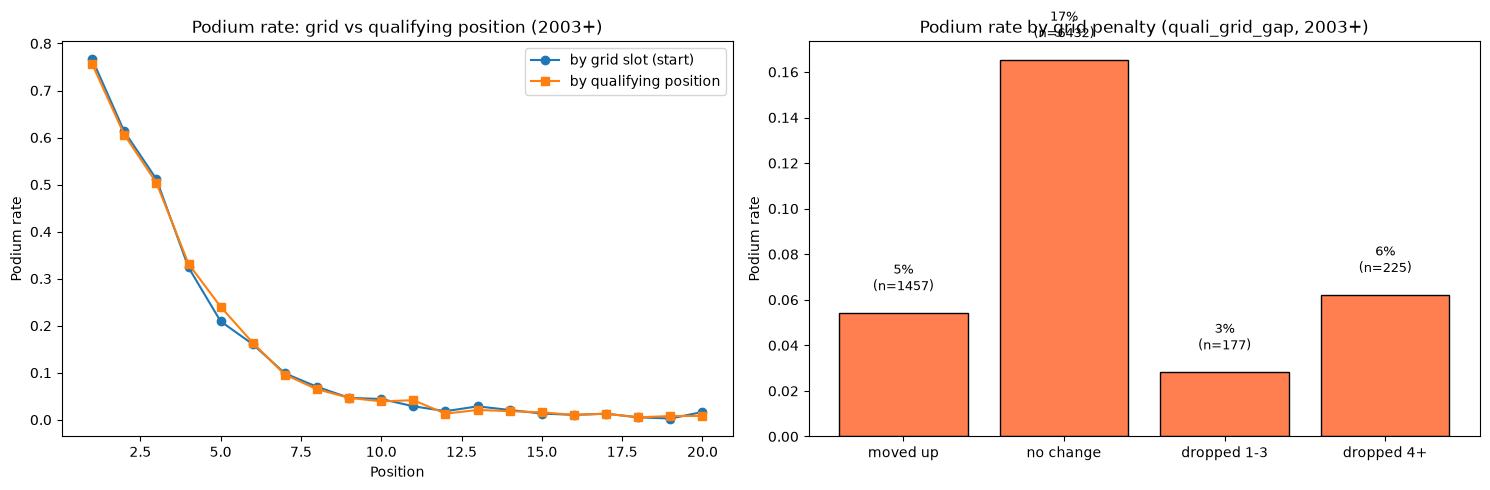

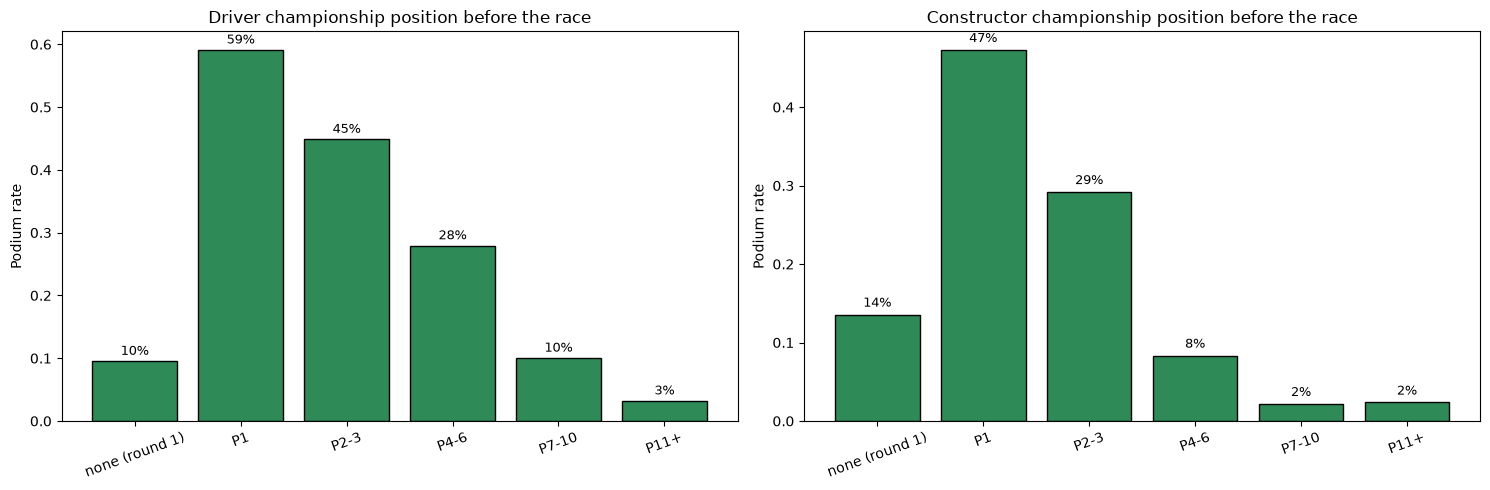

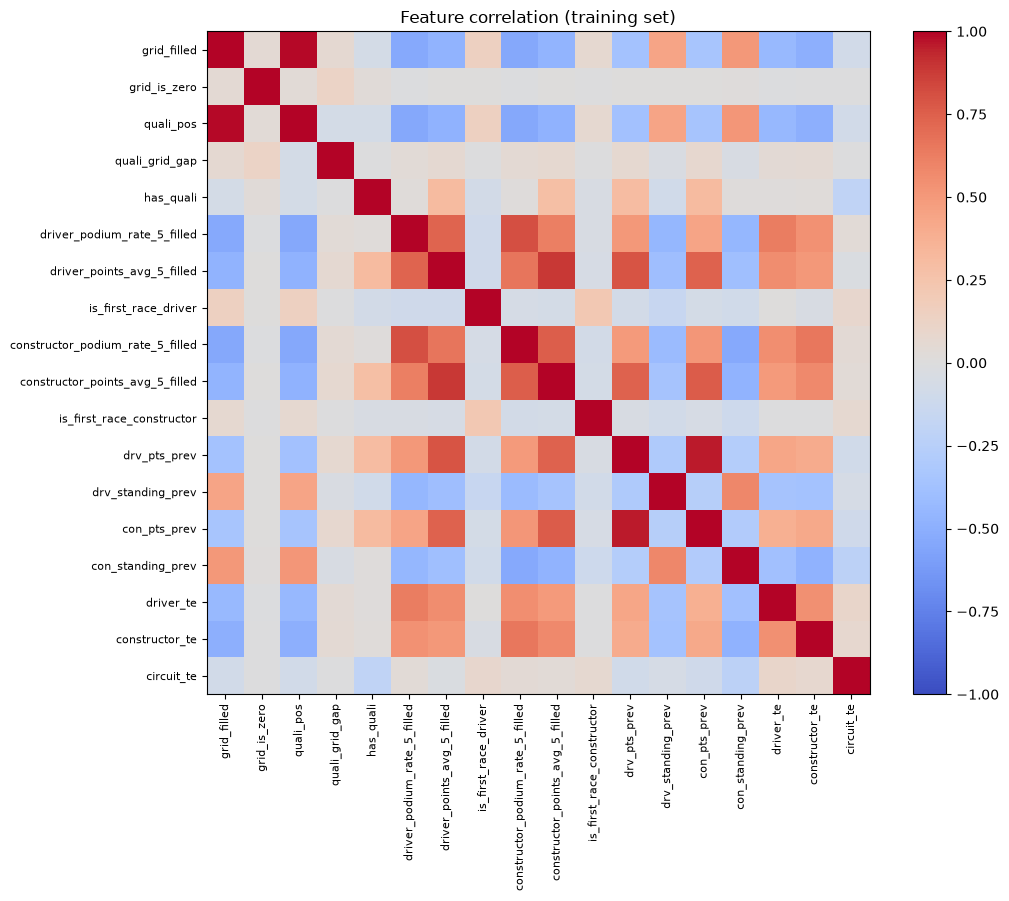

,a,b,corr
1,grid_filled,quali_pos,0.992
133,drv_pts_prev,con_pts_prev,0.958
89,driver_points_avg_5_filled,constructor_points_avg_5_filled,0.889


In [75]:
tr = train_df.copy()
ALL_FEATS = FEATURE_COLS + ['driver_te', 'constructor_te', 'circuit_te']
group_of = {c: g for g, cols in {**FEATURE_GROUPS, 'target_encoded': ['driver_te', 'constructor_te', 'circuit_te']}.items() for c in cols}

# 1) single-feature AUC (training set only)
auc_tbl = pd.DataFrame({'feature': ALL_FEATS,
                        'group': [group_of[c] for c in ALL_FEATS],
                        'AUC': [roc_auc_score(tr['podium'], tr[c]) for c in ALL_FEATS]})
auc_tbl['strength |AUC - 0.5|'] = (auc_tbl['AUC'] - 0.5).abs()
auc_tbl = auc_tbl.sort_values('strength |AUC - 0.5|', ascending=False).reset_index(drop=True)
display(auc_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(auc_tbl['feature'][::-1], auc_tbl['strength |AUC - 0.5|'][::-1], color='steelblue', edgecolor='black')
ax.set_xlabel('|AUC - 0.5| on its own (training set)'); ax.set_title('Single-feature strength')
plt.tight_layout(); plt.show()

# 2) qualifying evidence (2003+ rows with real qualifying data)
q = tr[tr['has_quali'] == 1]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pg = q[q['grid_filled'].between(1, 20)].groupby('grid_filled')['podium'].mean()
pq = q[q['quali_pos'].between(1, 20)].groupby('quali_pos')['podium'].mean()
axes[0].plot(pg.index, pg.values, marker='o', label='by grid slot (start)')
axes[0].plot(pq.index, pq.values, marker='s', label='by qualifying position')
axes[0].set_title('Podium rate: grid vs qualifying position (2003+)')
axes[0].set_xlabel('Position'); axes[0].set_ylabel('Podium rate'); axes[0].legend()

gap_bin = pd.cut(q['quali_grid_gap'], [-100, -1, 0, 3, 100],
                 labels=['moved up', 'no change', 'dropped 1-3', 'dropped 4+'])
gr = q.groupby(gap_bin, observed=True)['podium'].agg(['mean', 'count'])
axes[1].bar(gr.index.astype(str), gr['mean'], color='coral', edgecolor='black')
for i, (m_, n_) in enumerate(zip(gr['mean'], gr['count'])):
    axes[1].text(i, m_ + 0.01, f'{m_:.0%}\n(n={n_})', ha='center', fontsize=9)
axes[1].set_title('Podium rate by grid penalty (quali_grid_gap, 2003+)'); axes[1].set_ylabel('Podium rate')
plt.tight_layout(); plt.show()

# 3) standings evidence
sb = [-1, 0, 1, 3, 6, 10, 200]
sl = ['none (round 1)', 'P1', 'P2-3', 'P4-6', 'P7-10', 'P11+']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, title in [(axes[0], 'drv_standing_prev', 'Driver championship position before the race'),
                       (axes[1], 'con_standing_prev', 'Constructor championship position before the race')]:
    s = tr.groupby(pd.cut(tr[col], sb, labels=sl), observed=True)['podium'].agg(['mean', 'count'])
    ax.bar(s.index.astype(str), s['mean'], color='seagreen', edgecolor='black')
    for i, (m_, n_) in enumerate(zip(s['mean'], s['count'])):
        ax.text(i, m_ + 0.01, f'{m_:.0%}', ha='center', fontsize=9)
    ax.set_title(title); ax.set_ylabel('Podium rate'); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

# 4) correlation matrix and near-duplicates
corr = tr[ALL_FEATS].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_FEATS))); ax.set_xticklabels(ALL_FEATS, rotation=90, fontsize=8)
ax.set_yticks(range(len(ALL_FEATS))); ax.set_yticklabels(ALL_FEATS, fontsize=8)
plt.colorbar(im, ax=ax); ax.set_title('Feature correlation (training set)')
plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
             .rename('corr').reset_index().rename(columns={'level_0': 'a', 'level_1': 'b'}))
display(pairs[pairs['corr'].abs() > 0.85].sort_values('corr', key=abs, ascending=False).round(3))

### What we found

#### Qualifying

Qualifying position separates podiums about as well as the grid slot. The two podium-rate curves lie almost on top of each other (about 76% for P1, 50% for P3 and under 5% from P9 down).

Grid penalties matter:

| `quali_grid_gap` group | Podium rate | n |
|---|---|---|
| No change | ~17% | 6,432 |
| Moved up | ~5% | 1,457 |
| Dropped 1-3 places | ~3% | 177 |
| Dropped 4+ places | ~6% | 225 |

Because the penalised groups are small, we read these as a **direction, not a precise rate**.

#### Standings

Podium rate by championship position before the race:

| Position | Driver | Constructor |
|---|---|---|
| P1 | ~59% | ~47% |
| P2-3 | 45% | 29% |
| P4-6 | 28% | 8% |
| P7-10 | 10% | ~2% (P7 or lower) |
| P11 or lower | ~3% | (included above) |

The step down is steady for both drivers and constructors.

#### Single-feature AUC

The strongest three features:

| Feature | AUC | Strength (\|AUC − 0.5\|) |
|---|---|---|
| `quali_pos` | 0.116 | 0.384 |
| `grid_filled` | 0.117 | 0.383 |
| `constructor_podium_rate_5_filled` | 0.828 | 0.328 |

The first two are below 0.5 because a lower number is better, so they are as informative as an AUC of 0.88.

Close to 0.5, as expected (flags and the circuit encoding carry little on their own):

- `grid_is_zero` (0.499)
- `is_first_race_constructor` (0.496)
- `has_quali` (0.507)
- `is_first_race_driver` (0.486)
- `quali_grid_gap` (0.516)
- `circuit_te` (0.520)

#### Correlation

Three pairs exceed 0.85:

| Pair | Correlation |
|---|---|
| `grid_filled` / `quali_pos` | 0.992 |
| `drv_pts_prev` / `con_pts_prev` | 0.958 |
| `driver_points_avg_5_filled` / `constructor_points_avg_5_filled` | 0.889 |

Near-duplicate features share credit in SHAP and permutation importance, so we read **group totals and the ablation** rather than single bars.

> These plots show association with the podium, not causation.

### Hand-off: split and encoded features

`train_df`, `val_df` and `test_df` are the **only** train, validation and test tables to use for modeling (time-ordered: ≤2019, 2020-2021, ≥2022).

They contain:

- the target `podium`
- the feature groups listed in `FEATURE_GROUPS`
- three target-encoded features: `driver_te`, `constructor_te` and `circuit_te` (past-only for training rows, training statistics for validation and test)

The smoothing strength is `M = 20`, to be revisited in the modeling section with each model's validation PR-AUC.

### Evaluation metrics

**Why:** only about 12.7% of rows are podiums, so a model that always predicts "no podium" would be about 87% accurate and completely useless. Accuracy and `classification_report` therefore cannot be our headline numbers.

We report:

- **PR-AUC (main metric):** how well the model ranks the rare podium finishers at the top. A random model scores roughly the podium rate.
- **ROC-AUC (secondary):** a general ranking score where 0.5 means random.
- **F1:** a balance of precision and recall at one decision threshold.

The threshold is chosen on the **validation set only**, then applied unchanged to the test set. Accuracy is printed for reference only, to show how misleading it is.

In [76]:
def best_f1_threshold(y_true, y_score):
    """Cutoff that gives the best F1. Call this on VALIDATION data only."""
    p, r, thr = precision_recall_curve(y_true, y_score)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return thr[np.argmax(f1)]

def report(y_true, y_score, threshold, name=''):
    """All metrics for one model on one dataset."""
    y_pred = (y_score >= threshold).astype(int)
    return {
        'model': name,
        'PR-AUC (main)': average_precision_score(y_true, y_score),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'Accuracy (for reference only)': accuracy_score(y_true, y_pred),
    }

### Reference scores to beat

Before training any real model we score three trivial "models" on the validation set. Every real model must clearly beat them.

- **Always no podium:** shows how high accuracy gets while the model is useless.
- **Random scores:** shows what chance level looks like for PR-AUC and ROC-AUC.
- **Grid only:** ranks drivers purely by starting position (a better start is a higher score). This is the bar a real model must beat.

In [77]:
y_val = val_df['podium'].astype(int)
y_test = test_df['podium'].astype(int)

def grid_score(df):
    # Better (lower) grid slot = higher score. grid_filled already puts pit-lane starts (grid = 0) behind the last slot.
    return -df['grid_filled']

rng = np.random.default_rng(42)
candidates = {
    'Always no podium': np.zeros(len(val_df)),
    'Random scores':    rng.random(len(val_df)),
    'Grid only':        grid_score(val_df),
}

rows = []
for name, scores in candidates.items():
    thr = 0.5 if name == 'Always no podium' else best_f1_threshold(y_val, scores)
    rows.append(report(y_val, scores, thr, name))

pd.DataFrame(rows).set_index('model').round(3)

,PR-AUC (main),ROC-AUC,F1,Accuracy (for reference only)
model,,,,
Always no podium,0.151,0.500,0.000,0.849
Random scores,0.157,0.505,0.264,0.203
Grid only,0.648,0.910,0.695,0.908


### What we found (validation set)

| Reference | Accuracy | PR-AUC | ROC-AUC | F1 |
|---|---|---|---|---|
| Always no podium | ~85% | n/a | n/a | 0.000 |
| Random scores | n/a | ~0.17 | ~0.5 | n/a |
| Grid only | n/a | ~0.64 | ~0.91 | ~0.69 |

- **Accuracy is misleading.** A model that always predicts "no podium" reaches about 85% accuracy, yet its F1 is 0.000, so it finds no podiums at all. This is why accuracy is not our headline metric.
- **Chance level.** Random scores give a PR-AUC of about 0.17 and a ROC-AUC of about 0.5, close to the floor (the validation podium rate is about 15%, and 0.5 for ROC-AUC). These are the numbers any real model must beat.
- **Grid position alone is a strong baseline.** Ranking drivers only by their starting slot gives a PR-AUC of about 0.64, a ROC-AUC of about 0.91 and an F1 of about 0.69. This confirms what the EDA showed: grid position is highly predictive. Our real models must **clearly beat** these numbers to justify the extra features.

### Baseline: logistic regression

**How it works.** Logistic regression computes a weighted sum of the standardised features and squashes it through a sigmoid into a podium probability. Each weight says how much a feature moves the log-odds of a podium, which makes it easy to read and a fair baseline for the more complex models.

**Choices.**

- Features are standardised (scaler fitted on **training data only**).
- `class_weight='balanced'` handles the ~1:6 imbalance.
- The regularisation strength `C` is picked by validation PR-AUC from a small grid.
- The F1 threshold is picked on validation only.

**Limitations.**

- It is linear, so it cannot represent interactions (strong team x front-row start) unless we add them by hand.
- Correlated features such as `grid_filled` and `quali_pos` make individual coefficients unstable.
- It treats all years alike, although eras differ.

,C,train PR-AUC,val PR-AUC
0,0.001,0.565,0.703
1,0.010,0.568,0.718
2,0.100,0.568,0.722
3,1.000,0.568,0.722
4,10.000,0.568,0.723


,PR-AUC (main),ROC-AUC,F1,Accuracy (for reference only)
model,,,,
LR train,0.568,0.901,0.587,0.870
LR validation,0.723,0.925,0.710,0.908
LR test,0.686,0.934,0.680,0.882


Chosen C = 10.0; F1 threshold (from validation) = 0.731


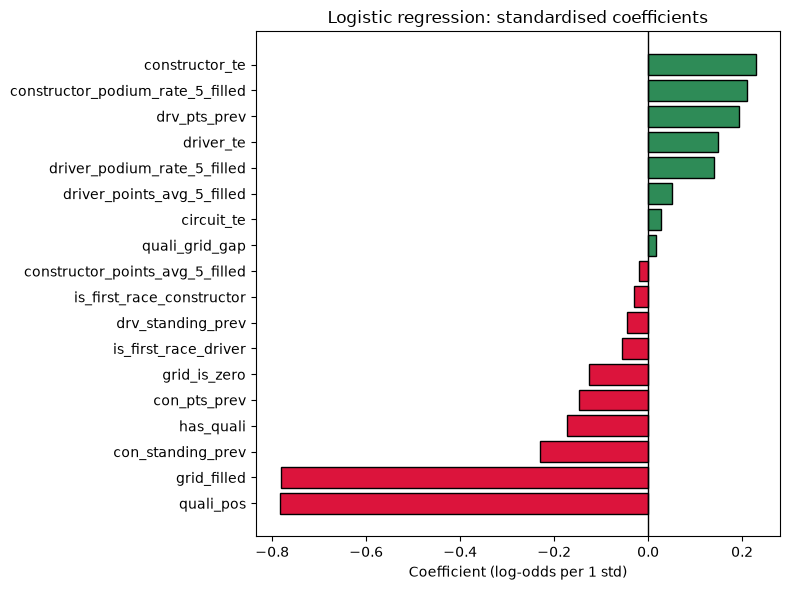

In [78]:
from sklearn.pipeline import make_pipeline

LR_FEATURES = FEATURE_COLS + ['driver_te', 'constructor_te', 'circuit_te']
ytr_lr = train_df['podium'].astype(int)
yva_lr = val_df['podium'].astype(int)
yte_lr = test_df['podium'].astype(int)

c_rows = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    p = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000))
    p.fit(train_df[LR_FEATURES], ytr_lr)
    c_rows.append({'C': C,
                   'train PR-AUC': average_precision_score(ytr_lr, p.predict_proba(train_df[LR_FEATURES])[:, 1]),
                   'val PR-AUC':   average_precision_score(yva_lr, p.predict_proba(val_df[LR_FEATURES])[:, 1])})
c_tbl = pd.DataFrame(c_rows)
display(c_tbl.round(3))

best_C = float(c_tbl.sort_values('val PR-AUC', ascending=False).iloc[0]['C'])
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, class_weight='balanced', max_iter=3000))
lr_pipe.fit(train_df[LR_FEATURES], ytr_lr)

p_tr = lr_pipe.predict_proba(train_df[LR_FEATURES])[:, 1]
p_va = lr_pipe.predict_proba(val_df[LR_FEATURES])[:, 1]
p_te = lr_pipe.predict_proba(test_df[LR_FEATURES])[:, 1]
lr_val_scores, lr_test_scores = p_va, p_te   # keep LR scores under their own names (p_va/p_te are reused later)
thr_lr = best_f1_threshold(yva_lr, p_va)
display(pd.DataFrame([report(ytr_lr, p_tr, thr_lr, 'LR train'), report(yva_lr, p_va, thr_lr, 'LR validation'),
                      report(yte_lr, p_te, thr_lr, 'LR test')]).set_index('model').round(3))
print(f"Chosen C = {best_C}; F1 threshold (from validation) = {thr_lr:.3f}")

# Standardised coefficients: direction and relative size (association, not causation)
coef = pd.Series(lr_pipe[-1].coef_[0], index=LR_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(coef.index, coef.values, color=['crimson' if v < 0 else 'seagreen' for v in coef.values], edgecolor='black')
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Logistic regression: standardised coefficients'); ax.set_xlabel('Coefficient (log-odds per 1 std)')
plt.tight_layout(); 
plt.show()

### What we found (LR baseline)

The best regularisation was **C = 10**, but validation PR-AUC is 0.718 to 0.723 for every C from 0.01 to 10, so the choice is within noise.

Scores at C = 10 (F1 threshold 0.731 chosen on validation):

| Split | PR-AUC | ROC-AUC | F1 |
|---|---|---|---|
| Train | 0.568 | 0.901 | 0.587 |
| Validation | 0.723 | 0.925 | 0.710 |
| Test | 0.686 | 0.934 | 0.680 |

Grid only scores 0.648 on validation and 0.647 on test, so logistic regression is about **0.075 better on validation** and **0.039 better on test**: the extra features help even a linear model.

#### Coefficients

The largest coefficients (per one standard deviation):

| Feature | Coefficient |
|---|---|
| `quali_pos` | -0.784 |
| `grid_filled` | -0.782 |
| `constructor_te` | +0.230 |
| `con_standing_prev` | -0.230 |
| `constructor_podium_rate_5_filled` | +0.210 |

- `grid_filled` and `quali_pos` have the same sign and nearly the same size (both about -0.78), because the model splits the credit between two almost identical features (correlation 0.99).
- The same caution applies to `con_pts_prev` (-0.147): its negative sign comes from overlap with other team features, not from a real penalty.

This is the baseline every other model must beat in the comparison table.

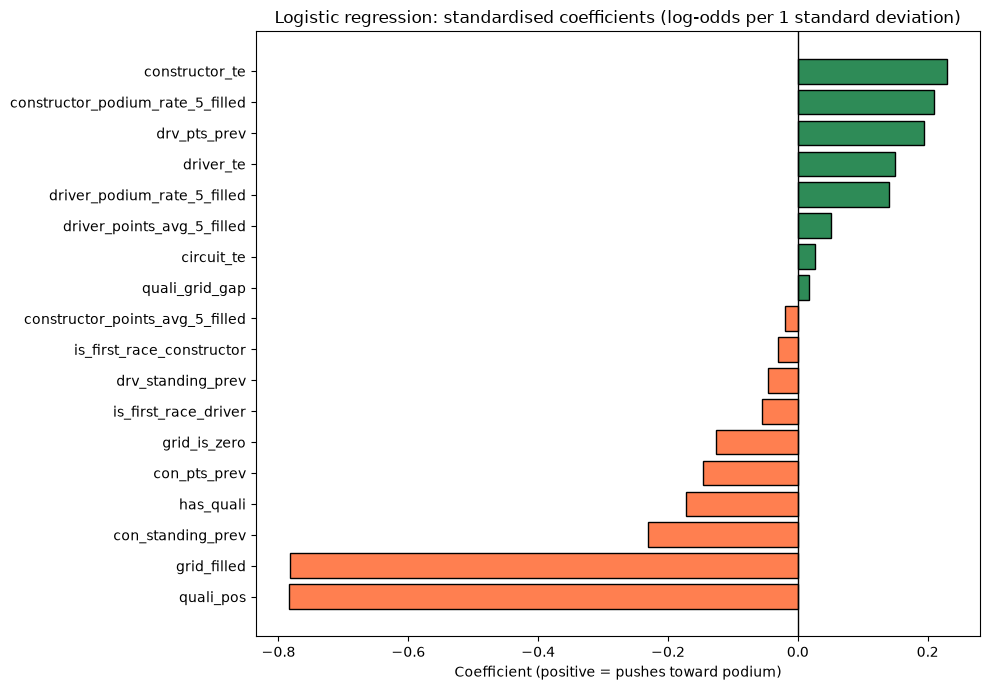

,coefficient,odds ratio per 1 SD
constructor_te,0.230,1.258
constructor_podium_rate_5_filled,0.210,1.234
drv_pts_prev,0.194,1.214
driver_te,0.149,1.161
driver_podium_rate_5_filled,0.141,1.152
driver_points_avg_5_filled,0.052,1.053
circuit_te,0.026,1.027
quali_grid_gap,0.018,1.018
constructor_points_avg_5_filled,-0.020,0.980
is_first_race_constructor,-0.031,0.969


In [79]:
final_lr = lr_pipe.named_steps['logisticregression']
coef = pd.Series(final_lr.coef_[0], index=LR_FEATURES).sort_values()
odds = np.exp(coef)


fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(coef.index, coef.values, color=['coral' if v < 0 else 'seagreen' for v in coef.values], edgecolor='black')
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Logistic regression: standardised coefficients (log-odds per 1 standard deviation)', fontsize=12)
ax.set_xlabel('Coefficient (positive = pushes toward podium)')
plt.tight_layout(); plt.show()

display(pd.DataFrame({'coefficient': coef, 'odds ratio per 1 SD': odds}).sort_values('coefficient', ascending=False).round(3))

### What we found (logistic regression baseline)

- **Performance.** Logistic regression reaches a validation PR-AUC of 0.723 and a test PR-AUC of 0.686 (ROC-AUC 0.925 / 0.934, test F1 0.68). It clearly beats grid only (0.648 validation, 0.647 test), so the form, standings and encoded features add information even to a simple linear model.
- **The complex models are only slightly better.** Random Forest, XGBoost and the shallow neural network reach about 0.70 to 0.71 on test, 0.01 to 0.03 above logistic regression. With about 200 podiums in the test set and 95% ranges of roughly 0.65 to 0.77, this gap is **not proven**. Most of the available signal is simple, and the extra complexity buys little.
- **Regularisation barely matters.** Validation PR-AUC is between 0.718 and 0.723 for all four values of C (0.01 to 10), so the choice is within noise. We use C = 10, the best on validation.
- **Validation is more optimistic than test** (0.723 against 0.686), a similar drop to the other models. The test column is the honest estimate.

#### Reading the coefficients

- **Starting position is the strongest signal.** `grid_filled` and `quali_pos` have almost identical coefficients (about -0.78), because they carry nearly the same information and the model splits the credit. Together, starting about one standard deviation (about 6.7 slots) further back multiplies the podium odds by about **0.21**, other features held equal.
- **Team strength comes next.** `constructor_te` (+0.23) and recent team podium rate (+0.21) have the largest positive effects, followed by the driver's championship points (+0.19) and the driver's historical podium rate (+0.15). Team features outweigh driver form, which matches SHAP for XGBoost.
- **Standing features have negative signs for a simple reason.** A lower number means a better championship position, so `con_standing_prev` (-0.23) means a better-placed team is more likely to podium.
- **Some coefficients cannot be read one by one.** `con_pts_prev` (-0.15) is negative even though more team points should help. It overlaps strongly with `constructor_te` and `con_standing_prev`, and a linear model can give one of several correlated features a negative weight. The same caution applies to `has_quali` (-0.17), which is tied to the era.
- **Several features add almost nothing** (`circuit_te`, `quali_grid_gap`, the first-race flags): their odds ratios are between 0.95 and 1.03.

#### Limitations

- The model treats every feature as a straight line and cannot combine them (for example a strong team and a front-row start).
- Class weights make the predicted probabilities higher than real podium rates, so we read them as **scores**.
- Coefficients are per one standard deviation and describe **associations, not causes**.

### Shallow Neural Network

We train a shallow feed-forward neural network on the same feature set used by the logistic regression baseline. The goal is to capture **non-linear interactions** between features (e.g. a strong constructor combined with a front-row start) that a linear model cannot represent.

**Architecture:** 2 hidden layers with ReLU activations, dropout for regularisation, and a single sigmoid output node for binary classification.

**Training details:**

- **Loss:** binary cross-entropy
- **Optimiser:** Adam
- **Primary metric:** PR-AUC (area under the precision-recall curve), chosen because the positive class (podium) is only 13.8% of rows
- **Early stopping** on validation PR-AUC to avoid overfitting
- **Class weights** to handle the imbalance (~1:6 positive:negative)

**Evaluation:** we report PR-AUC and ROC-AUC on both validation and test sets, and compare against the logistic regression baseline.

### Step 1: Preprocessing

Neural networks are sensitive to feature scale. We standardise all numeric features to zero mean and unit variance using `StandardScaler` fitted on **training data only**. The validation and test sets are transformed with the training statistics, never re-fitted. This is the same leakage rule applied earlier.

The feature set is the engineered columns listed in `FEATURE_GROUPS` (grid, qualifying, form, standings) plus the 3 target-encoded columns added in the previous section.

In [80]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

FEATURES = FEATURE_COLS + ['driver_te', 'constructor_te', 'circuit_te']

X_train = train_df[FEATURES].values
y_train = train_df['podium'].values

X_val   = val_df[FEATURES].values
y_val   = val_df['podium'].values

X_test  = test_df[FEATURES].values
y_test  = test_df['podium'].values

# Fit scaler on training data only
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# Class weight: ratio of negatives to positives
neg, pos = np.bincount(y_train)
class_weight = {0: 1.0, 1: neg / pos}
print(f"Training rows: {len(X_train)}, features: {X_train.shape[1]}")
print(f"Class weight for positives: {class_weight[1]:.2f}")

Training rows: 22450, features: 18
Class weight for positives: 6.39


### Step 2: Model architecture

The network has:

- **Input layer:** one unit per feature (`len(FEATURES)`, the engineered columns plus the 3 target-encoded ones)
- **Hidden layer 1:** 64 units, ReLU, Dropout 0.3
- **Hidden layer 2:** 32 units, ReLU, Dropout 0.3
- **Output layer:** 1 unit, sigmoid → outputs a podium probability in [0, 1]

Dropout randomly zeros 30% of activations during training, which acts as regularisation and prevents the network from memorising training examples. It is disabled automatically at inference time.

We use `EarlyStopping` monitoring validation PR-AUC with a patience of 10 epochs, restoring the best weights when training stops.

In [83]:
# P3 : Model definition and trianing

tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=1e-3),
    loss = 'binary_crossentropy',
    metrics = [keras.metrics.AUC(curve='PR', name='pr_auc')]
)

model.summary()

early_stop = EarlyStopping(
    monitor='val_pr_auc',
    mode='max',
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=256,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=0,
)

best_epoch = np.argmax(history.history['val_pr_auc']) + 1
print(f"\nBest epoch: {best_epoch}")
print(f"Best val PR-AUC: {max(history.history['val_pr_auc']):.4f}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,329 (13.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 48: early stopping
Restoring model weights from the end of the best epoch: 38.

Best epoch: 38
Best val PR-AUC: 0.7622


### Step 3: Evaluation

We evaluate the final model (best weights, restored by early stopping) on both validation and test sets. Reported metrics:

- **PR-AUC:** primary metric; measures quality of ranked predictions for the minority class
- **ROC-AUC:** secondary metric; easier to compare across literature but less informative under class imbalance

────────────────────────────────────────
                           Val      Test
────────────────────────────────────────
PR-AUC                  0.7606    0.7004
ROC-AUC                 0.9225    0.9315
────────────────────────────────────────


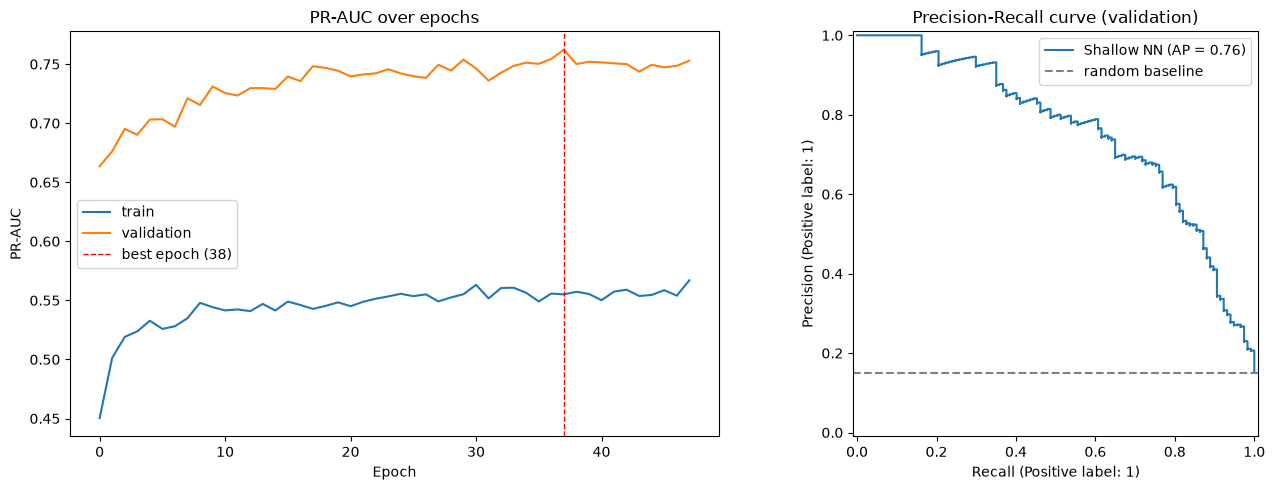

In [85]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

val_probs = model.predict(X_val, verbose=0).flatten()
test_probs = model.predict(X_test, verbose=0).flatten()

val_pr_auc = average_precision_score(y_val, val_probs)
val_roc_auc = roc_auc_score(y_val, val_probs)
tst_pr_auc = average_precision_score(y_test, test_probs)
tst_roc_auc = roc_auc_score(y_test, test_probs)

print("─" * 40)
print(f"{'':20s}  {'Val':>8}  {'Test':>8}")
print("─" * 40)
print(f"{'PR-AUC':20s}  {val_pr_auc:8.4f}  {tst_pr_auc:8.4f}")
print(f"{'ROC-AUC':20s}  {val_roc_auc:8.4f}  {tst_roc_auc:8.4f}")
print("─" * 40)

# Training curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['pr_auc'],     label='train')
axes[0].plot(history.history['val_pr_auc'], label='validation')
axes[0].axvline(best_epoch - 1, color='red', linestyle='--', linewidth=1, label=f'best epoch ({best_epoch})')
axes[0].set_title('PR-AUC over epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('PR-AUC')
axes[0].legend()

# Precision-recall curve on validation
PrecisionRecallDisplay.from_predictions(y_val, val_probs, ax=axes[1], name='Shallow NN')
axes[1].axhline(y_val.mean(), color='gray', linestyle='--', label='random baseline')
axes[1].set_title('Precision-Recall curve (validation)')
axes[1].legend()

plt.tight_layout()
plt.show()